# 💰 Predicting Loan Default Using Machine Learning — Colab edition

A single-notebook version of [suhasmaddali/Predicting-Loan-Default-Using-Machine-Learning](https://github.com/suhasmaddali/Predicting-Loan-Default-Using-Machine-Learning).
The repo ships three notebooks; they appear here **in order and cell-for-cell**:

| Part | Original notebook |
|---|---|
| 1 | `Exploratory Data Analysis (EDA).ipynb` |
| 2 | `Data Preprocessing.ipynb` |
| 3 | `Machine Learning Models.ipynb` |
| Bonus | *Not in the original* — a leakage-free re-evaluation (clearly labelled) |

**Dataset:** the *Home Credit Default Risk* data (public, from the Kaggle competition of the same name). The
repo stores the two CSVs with Git LFS; the setup cell below downloads them straight from GitHub — no Kaggle account needed.

**Changes vs. the original code** are limited to keeping it runnable on today's libraries. Every changed line is
tagged `# [Colab fix]`. Cells added for Colab are tagged `# [Added for Colab]`.

**Runtime:** the default CPU runtime of the Colab free tier is enough (no GPU needed). A full *Run all* takes roughly 25–40 minutes, most of it in the Random Forest cells of Part 3.


In [1]:
# [Added for Colab] Install the two libraries Colab may not have pre-installed
!pip install -q imbalanced-learn missingno

In [2]:
# [Added for Colab] Get the dataset (~190 MB) if it is not already next to the notebook
import os, urllib.request

BASE = "https://media.githubusercontent.com/media/suhasmaddali/Predicting-Loan-Default-Using-Machine-Learning/main/"
for fname in ["application_train.csv", "application_test.csv"]:
    if os.path.exists(fname) and os.path.getsize(fname) > 1_000_000:
        print(f"{fname} already present ({os.path.getsize(fname)/1e6:.0f} MB)")
        continue
    print(f"Downloading {fname} ...")
    urllib.request.urlretrieve(BASE + fname, fname)
    print(f"  done ({os.path.getsize(fname)/1e6:.0f} MB)")

# Fallback if the GitHub download ever fails (LFS bandwidth limits):
#   1. Kaggle → Account → Create New API Token  (downloads kaggle.json)
#   2. Upload kaggle.json to Colab, then run:
#   !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
#   !kaggle competitions download -c home-credit-default-risk -f application_train.csv
#   !kaggle competitions download -c home-credit-default-risk -f application_test.csv
#   !unzip -o '*.zip'
#   (You must first click "Join competition / I understand and accept" on the Kaggle competition page.)

application_train.csv already present (166 MB)
application_test.csv already present (27 MB)


In [3]:
# [Added for Colab] Version-compatibility settings
import pandas as pd
# pandas 3 stores text as a new 'str' dtype; the original code expects the classic 'object' dtype.
try:
    pd.set_option("future.infer_string", False)
except Exception:
    pass

# sklearn >= 1.2 removed plot_confusion_matrix(); this shim keeps the original call sites unchanged.
from sklearn.metrics import ConfusionMatrixDisplay
def plot_confusion_matrix(estimator, X, y, ax=None, **kwargs):
    return ConfusionMatrixDisplay.from_estimator(estimator, X, y, ax=ax, **kwargs)

import sklearn, numpy
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| numpy", numpy.__version__)

pandas 3.0.5 | scikit-learn 1.9.1 | numpy 2.5.3


---
# Part 1 — Exploratory Data Analysis (EDA)
*Original file: `Exploratory Data Analysis (EDA).ipynb`*

## Exploratory Data Analysis (EDA)

In [4]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

In [5]:
df = pd.read_csv("application_train.csv")

In [6]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
print("The total shape of the dataframe: {}".format(df.shape))

The total shape of the dataframe: (307511, 122)


In [8]:
df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [9]:
df['NAME_CONTRACT_TYPE'].value_counts()

NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

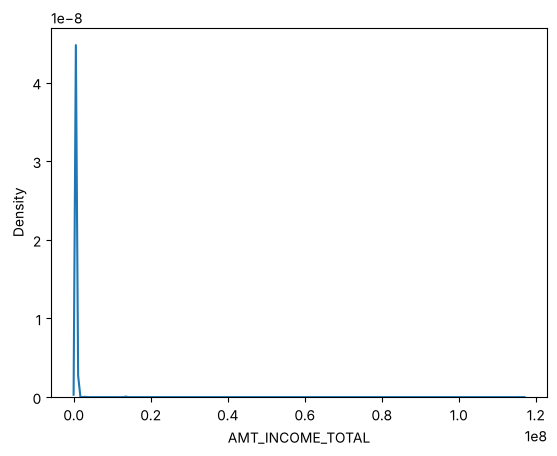

In [10]:
sns.kdeplot(x = 'AMT_INCOME_TOTAL', data = df)  # [Colab fix] column is upper-case at this point
plt.show()

In [11]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
df.columns = [column.lower() for column in df.columns]

In [13]:
df[df.target == 1].shape

(24825, 122)

In [14]:
defaulted_df = df[df.target == 1]
non_defaulted_df = df[df.target == 0]

In [15]:
defaulted_df.shape

(24825, 122)

In [16]:
non_defaulted_df.shape

(282686, 122)

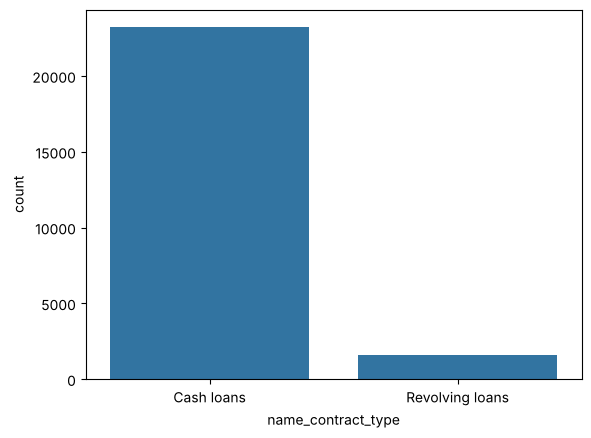

In [17]:
sns.countplot(data = defaulted_df, x = 'name_contract_type')
plt.show()

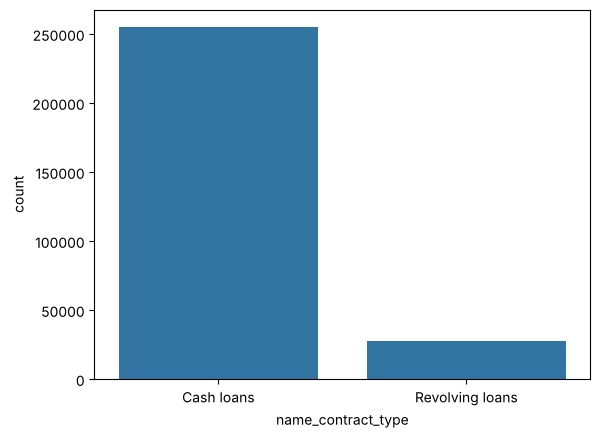

In [18]:
sns.countplot(data = non_defaulted_df, x = 'name_contract_type')
plt.show()

In [19]:
df.head()

,sk_id_curr,target,name_contract_type,code_gender,flag_own_car,flag_own_realty,cnt_children,amt_income_total,amt_credit,amt_annuity,...,flag_document_18,flag_document_19,flag_document_20,flag_document_21,amt_req_credit_bureau_hour,amt_req_credit_bureau_day,amt_req_credit_bureau_week,amt_req_credit_bureau_mon,amt_req_credit_bureau_qrt,amt_req_credit_bureau_year
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [20]:
defaulted_df.head()

,sk_id_curr,target,name_contract_type,code_gender,flag_own_car,flag_own_realty,cnt_children,amt_income_total,amt_credit,amt_annuity,...,flag_document_18,flag_document_19,flag_document_20,flag_document_21,amt_req_credit_bureau_hour,amt_req_credit_bureau_day,amt_req_credit_bureau_week,amt_req_credit_bureau_mon,amt_req_credit_bureau_qrt,amt_req_credit_bureau_year
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
26,100031,1,Cash loans,F,N,Y,0,112500.0,979992.0,27076.5,...,0,0,0,0,0.0,0.0,0.0,0.0,2.0,2.0
40,100047,1,Cash loans,M,N,Y,0,202500.0,1193580.0,35028.0,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,4.0
42,100049,1,Cash loans,F,N,N,0,135000.0,288873.0,16258.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,2.0
81,100096,1,Cash loans,F,N,Y,0,81000.0,252000.0,14593.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


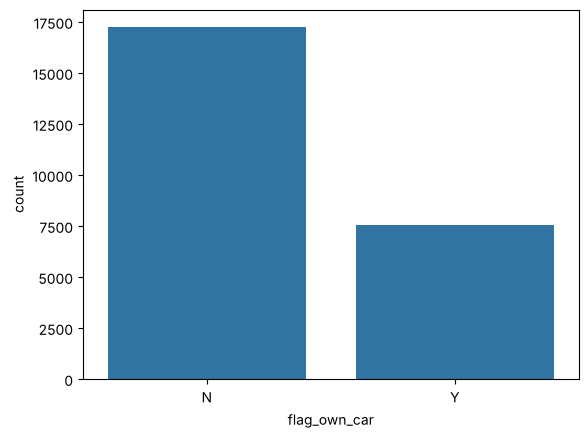

In [21]:
sns.countplot(data = defaulted_df, x = 'flag_own_car')
plt.show()

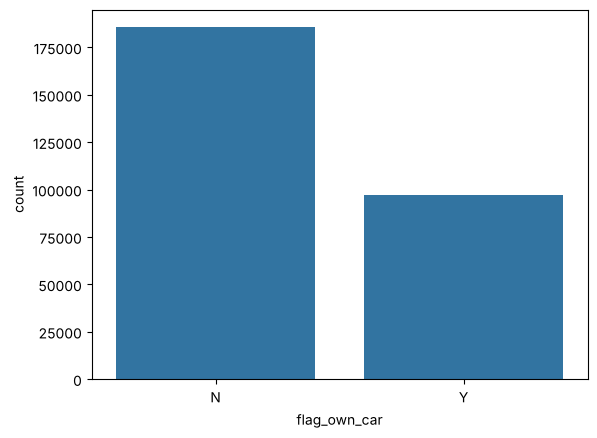

In [22]:
sns.countplot(data = non_defaulted_df, x = 'flag_own_car')
plt.show()

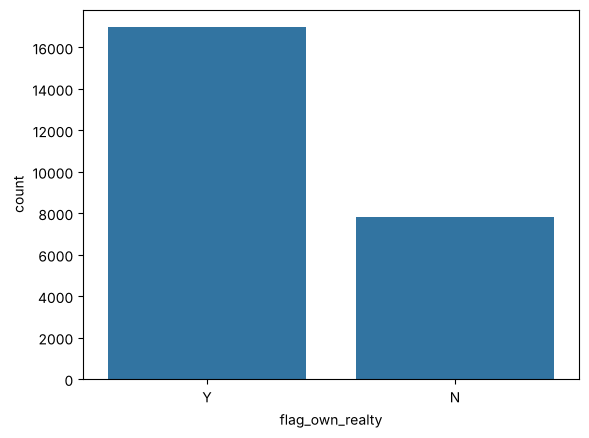

In [23]:
sns.countplot(data = defaulted_df, x = 'flag_own_realty')
plt.show()

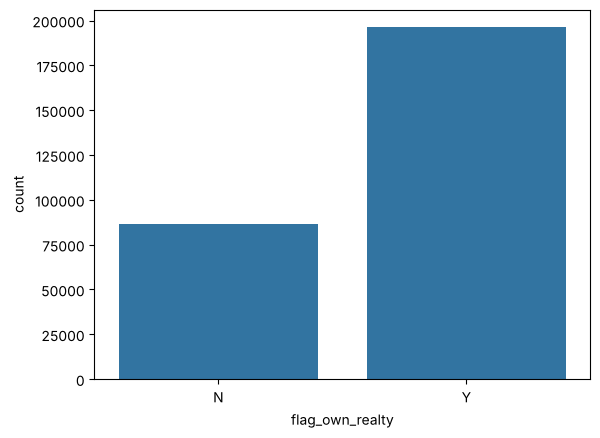

In [24]:
sns.countplot(data = non_defaulted_df, x = 'flag_own_realty')
plt.show()

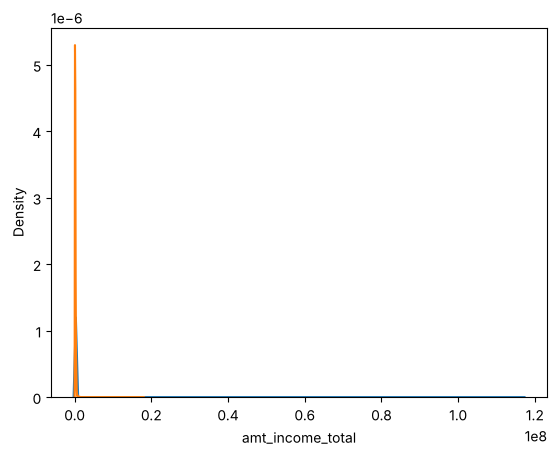

In [25]:
sns.kdeplot(data = defaulted_df, x = 'amt_income_total')

sns.kdeplot(data = non_defaulted_df, x = 'amt_income_total')
plt.show()

In [26]:
threshold_income = 500000
defaulted_income_df = defaulted_df[defaulted_df['amt_income_total'] < threshold_income]
non_defaulted_income_df = non_defaulted_df[non_defaulted_df['amt_income_total'] < threshold_income]

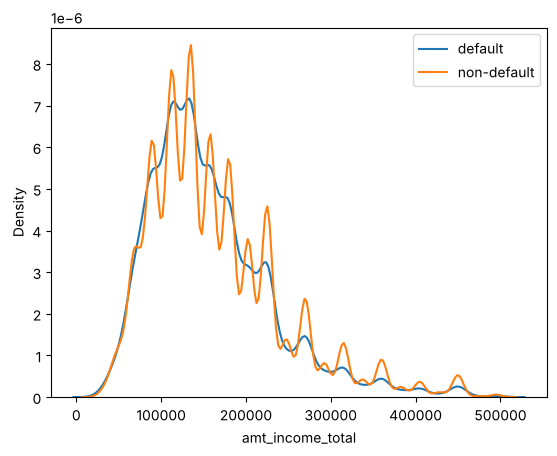

In [27]:
sns.kdeplot(data = defaulted_income_df, x = 'amt_income_total', label = 'default')
sns.kdeplot(data = non_defaulted_income_df, x = 'amt_income_total', label = 'non-default')
plt.legend()
plt.show()

In [28]:
for column in defaulted_df.columns:
    print(column)

sk_id_curr
target
name_contract_type
code_gender
flag_own_car
flag_own_realty
cnt_children
amt_income_total
amt_credit
amt_annuity
amt_goods_price
name_type_suite
name_income_type
name_education_type
name_family_status
name_housing_type
region_population_relative
days_birth
days_employed
days_registration
days_id_publish
own_car_age
flag_mobil
flag_emp_phone
flag_work_phone
flag_cont_mobile
flag_phone
flag_email
occupation_type
cnt_fam_members
region_rating_client
region_rating_client_w_city
weekday_appr_process_start
hour_appr_process_start
reg_region_not_live_region
reg_region_not_work_region
live_region_not_work_region
reg_city_not_live_city
reg_city_not_work_city
live_city_not_work_city
organization_type
ext_source_1
ext_source_2
ext_source_3
apartments_avg
basementarea_avg
years_beginexpluatation_avg
years_build_avg
commonarea_avg
elevators_avg
entrances_avg
floorsmax_avg
floorsmin_avg
landarea_avg
livingapartments_avg
livingarea_avg
nonlivingapartments_avg
nonlivingarea_avg
apart

In [29]:
df['name_education_type'].value_counts()

name_education_type
Secondary / secondary special    218391
Higher education                  74863
Incomplete higher                 10277
Lower secondary                    3816
Academic degree                     164
Name: count, dtype: int64

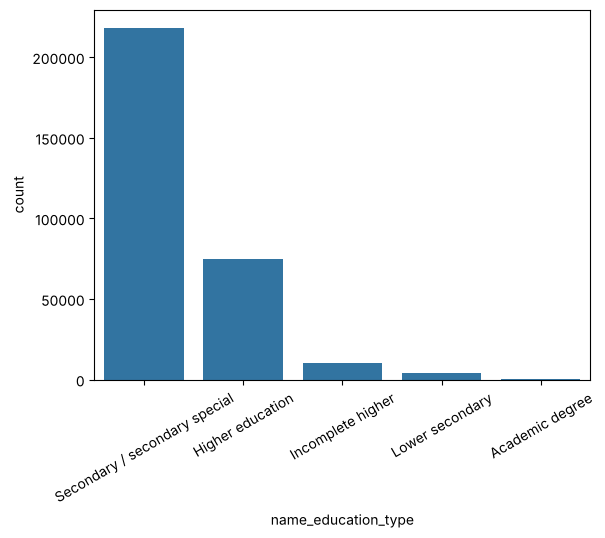

In [30]:
sns.countplot(data = df, x = 'name_education_type')
plt.xticks(rotation = 30)
plt.show()

In [31]:
df['name_education_type'].value_counts().values

array([218391,  74863,  10277,   3816,    164])

In [32]:
df['name_education_type'].value_counts().index

Index(['Secondary / secondary special', 'Higher education',
       'Incomplete higher', 'Lower secondary', 'Academic degree'],
      dtype='object', name='name_education_type')

In [33]:
total = sum(df['name_education_type'].value_counts().values)

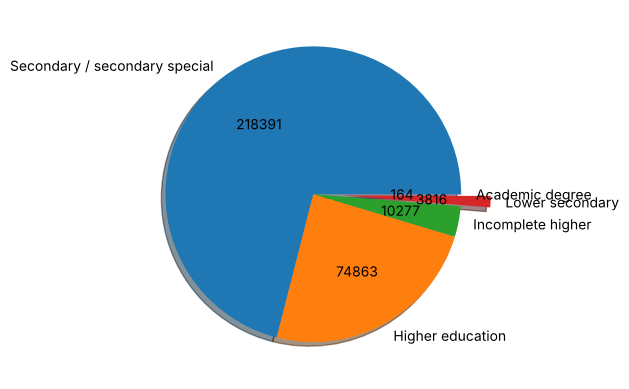

In [34]:
plt.pie(df['name_education_type'].value_counts().values,
       labels = df['name_education_type'].value_counts().index,
        autopct = lambda p: '{:.0f}'.format(p * total / 100),
       startangle = 0, explode = [0, 0, 0, 0.2, 0],
       shadow = True)
plt.show()

In [35]:
defaulted_df['name_education_type'].value_counts()

name_education_type
Secondary / secondary special    19524
Higher education                  4009
Incomplete higher                  872
Lower secondary                    417
Academic degree                      3
Name: count, dtype: int64

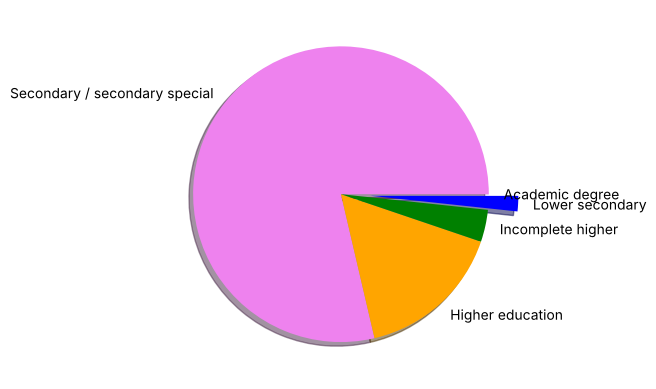

In [36]:
mycolors = ['violet', 'orange', 'green', 'blue', 'purple']
plt.pie(defaulted_df['name_education_type'].value_counts().values,
       labels = defaulted_df['name_education_type'].value_counts().index,
       explode = [0, 0, 0, 0.2, 0],
       shadow = True, colors = mycolors)
plt.show()

In [37]:
# [Added for Colab] free memory before the next part (each part re-reads the CSVs)
import gc
del df, defaulted_df, non_defaulted_df, defaulted_income_df, non_defaulted_income_df
gc.collect()

16660

---
# Part 2 — Data Preprocessing
*Original file: `Data Preprocessing.ipynb`*

In [38]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

In [39]:
df_train = pd.read_csv('application_train.csv')
df_test = pd.read_csv('application_test.csv')

In [40]:
def null_percentage(data):
    null_values_total = data.isnull().sum().sort_values(ascending = False)
    total_null_percent = (data.isnull().sum()/data.isnull().count() * 100).sort_values(ascending = False)
    return pd.concat([null_values_total, total_null_percent], axis = 1, keys = ['Total', 'Percent'])

In [41]:
print("The shape of the training dataset is: {}".format(df_train.shape))
print("The shape of the testing dataset is: {}".format(df_test.shape))

The shape of the training dataset is: (307511, 122)
The shape of the testing dataset is: (48744, 121)


In [42]:
# Dropping columns that contain more than 50 percent null values per feature
for column in df_train.columns:
    if null_percentage(df_train[column].to_frame())['Percent'].iloc[0] > 50.00:  # [Colab fix] .iloc[0]
        df_train.drop([column], axis = 1, inplace = True)
        df_test.drop([column], axis = 1, inplace = True)

In [43]:
def mean_imputation(data):
    """
    This function would take the NULL values present in data and replace them with average values of the data respectively.
    """
    imputed_data = data.fillna(data.mean()).copy()
    return imputed_data

def median_imputation(data):
    """
    This function would take the NULL values present in data and replace them with median values in our data respectively.
    """
    imputed_data = data.fillna(data.median()).copy()
    return imputed_data

def mode_imputation(data):
    """
    This function would take the NULL values present in data and replace them with mode values of the given data respectively.
    """
    imputed_data = data.fillna(data.mode()).copy()
    return imputed_data

In [44]:
mean_imputation(df_train['FLOORSMAX_AVG'])
mean_imputation(df_train['FLOORSMAX_MEDI'])
mean_imputation(df_train['FLOORSMAX_MODE'])
mean_imputation(df_train['YEARS_BEGINEXPLUATATION_AVG'])
mean_imputation(df_train['YEARS_BEGINEXPLUATATION_MEDI'])
mean_imputation(df_train['YEARS_BEGINEXPLUATATION_MODE'])

0         0.972200
1         0.985100
2         0.977065
3         0.977065
4         0.977065
            ...   
307506    0.978200
307507    0.972700
307508    0.981600
307509    0.977200
307510    0.988100
Name: YEARS_BEGINEXPLUATATION_MODE, Length: 307511, dtype: float64

In [45]:
null_percent_values = null_percentage(df_train)['Percent']
features_with_low_null_values = []
for i in range(len(df_train.columns)):
    if null_percent_values.iloc[i] < 10.0:
        features_with_low_null_values.append(null_percent_values.index[i]) 

In [46]:
df_train_converted = df_train[features_with_low_null_values]

In [47]:
## This is done to get the categorical features. We can then perform mode imputation to get the values respectively.
## The suggestion was implemented from the website https://stackoverflow.com/questions/29803093/check-which-columns-in-dataframe-are-categorical
total_columns =df_train_converted.columns 
numeric_data = df_train_converted._get_numeric_data()
categorical_columns = list(set(total_columns) - set(numeric_data.columns))

In [48]:
categorical_data = df_train_converted[categorical_columns]

In [49]:
mode_imputation(categorical_data)

,WEEKDAY_APPR_PROCESS_START,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,FLAG_OWN_CAR
0,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Business Entity Type 3,Unaccompanied,N
1,MONDAY,House / apartment,Higher education,State servant,N,F,Married,Cash loans,School,Family,N
2,MONDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Revolving loans,Government,Unaccompanied,Y
3,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,F,Civil marriage,Cash loans,Business Entity Type 3,Unaccompanied,N
4,THURSDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Religion,Unaccompanied,N
...,...,...,...,...,...,...,...,...,...,...,...
307506,THURSDAY,With parents,Secondary / secondary special,Working,N,M,Separated,Cash loans,Services,Unaccompanied,N
307507,MONDAY,House / apartment,Secondary / secondary special,Pensioner,Y,F,Widow,Cash loans,XNA,Unaccompanied,N
307508,THURSDAY,House / apartment,Higher education,Working,Y,F,Separated,Cash loans,School,Unaccompanied,N
307509,WEDNESDAY,House / apartment,Secondary / secondary special,Commercial associate,Y,F,Married,Cash loans,Business Entity Type 1,Unaccompanied,N


In [50]:
categorical_data['NAME_TYPE_SUITE'] = categorical_data['NAME_TYPE_SUITE'].fillna(value = 'Unaccompanied')  # [Colab fix] assign instead of chained inplace

In [51]:
numeric_data.head()

,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,TARGET,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,1,...,0,0,0,0,0,0,0,0,0,0
1,1.0,0.0,1.0,0.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,...,0,0,0,0,0,0,0,0,0,0
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,...,0,0,0,0,0,0,0,0,0,0
3,2.0,0.0,2.0,0.0,0.650442,297000.0,29686.5,2.0,-617.0,0,...,0,0,0,0,0,0,0,0,0,0
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,0,...,0,0,0,0,0,0,0,0,0,0


In [52]:
categorical_data.head()

,WEEKDAY_APPR_PROCESS_START,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,FLAG_OWN_CAR
0,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Business Entity Type 3,Unaccompanied,N
1,MONDAY,House / apartment,Higher education,State servant,N,F,Married,Cash loans,School,Family,N
2,MONDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Revolving loans,Government,Unaccompanied,Y
3,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,F,Civil marriage,Cash loans,Business Entity Type 3,Unaccompanied,N
4,THURSDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Religion,Unaccompanied,N


In [53]:
import missingno as msno
import matplotlib.pyplot as plt

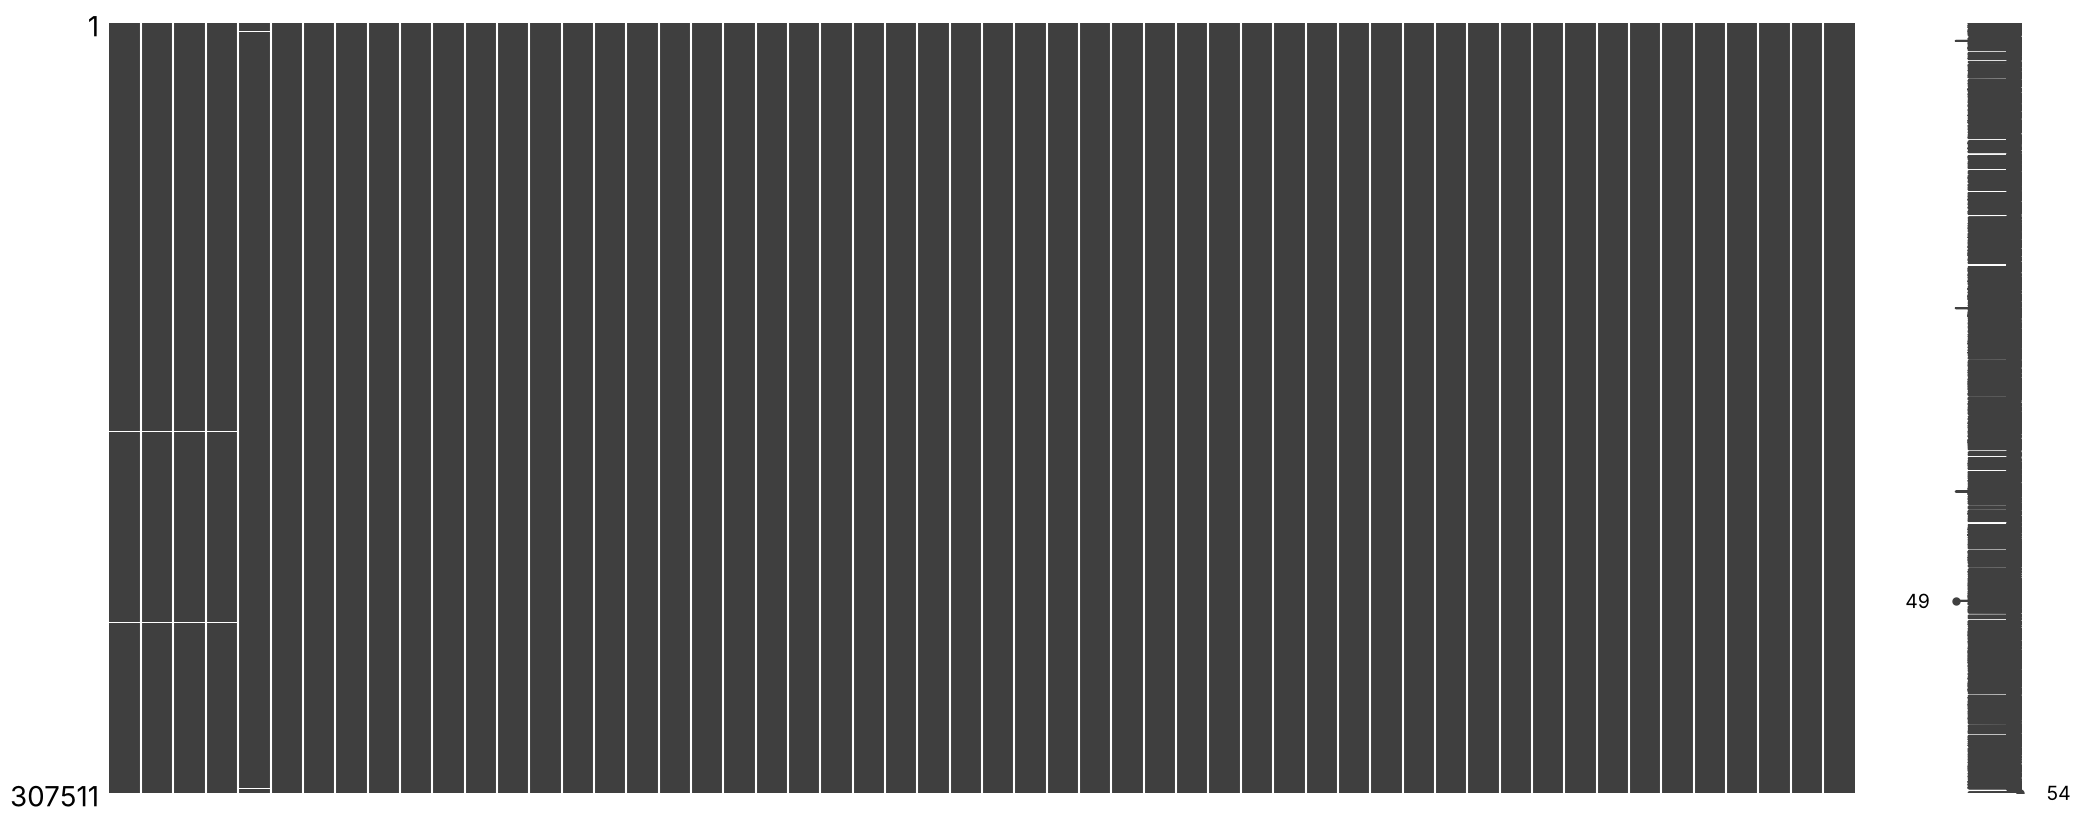

In [54]:
msno.matrix(numeric_data)
plt.show()

In [55]:
has_missing = numeric_data.isnull().any()
missing_data_columns = numeric_data.columns[has_missing]

In [56]:
missing_data_columns

Index(['OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE',
       'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'EXT_SOURCE_2',
       'AMT_GOODS_PRICE', 'AMT_ANNUITY', 'CNT_FAM_MEMBERS',
       'DAYS_LAST_PHONE_CHANGE'],
      dtype='object')

In [57]:
# Showing data with features that have missing values
numeric_data[missing_data_columns].head()

,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0
1,1.0,0.0,1.0,0.0,0.622246,1129500.0,35698.5,2.0,-828.0
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0
3,2.0,0.0,2.0,0.0,0.650442,297000.0,29686.5,2.0,-617.0
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0


In [58]:
# Imputing the missing values with the mean of the data
mean_imputation(numeric_data[missing_data_columns])

,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0
1,1.0,0.0,1.0,0.0,0.622246,1129500.0,35698.5,2.0,-828.0
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0
3,2.0,0.0,2.0,0.0,0.650442,297000.0,29686.5,2.0,-617.0
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0
...,...,...,...,...,...,...,...,...,...
307506,0.0,0.0,0.0,0.0,0.681632,225000.0,27558.0,1.0,-273.0
307507,0.0,0.0,0.0,0.0,0.115992,225000.0,12001.5,1.0,0.0
307508,6.0,0.0,6.0,0.0,0.535722,585000.0,29979.0,1.0,-1909.0
307509,0.0,0.0,0.0,0.0,0.514163,319500.0,20205.0,2.0,-322.0


In [59]:
numeric_data.fillna(numeric_data.mean(), inplace = True)

,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,TARGET,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,1,...,0,0,0,0,0,0,0,0,0,0
1,1.0,0.0,1.0,0.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,...,0,0,0,0,0,0,0,0,0,0
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,...,0,0,0,0,0,0,0,0,0,0
3,2.0,0.0,2.0,0.0,0.650442,297000.0,29686.5,2.0,-617.0,0,...,0,0,0,0,0,0,0,0,0,0
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,0.0,0.0,0.0,0.0,0.681632,225000.0,27558.0,1.0,-273.0,0,...,0,0,0,0,0,0,0,0,0,0
307507,0.0,0.0,0.0,0.0,0.115992,225000.0,12001.5,1.0,0.0,0,...,0,0,0,0,0,0,0,0,0,0
307508,6.0,0.0,6.0,0.0,0.535722,585000.0,29979.0,1.0,-1909.0,0,...,0,0,0,0,0,0,0,0,0,0
307509,0.0,0.0,0.0,0.0,0.514163,319500.0,20205.0,2.0,-322.0,1,...,0,0,0,0,0,0,0,0,0,0


In [60]:
has_missing = categorical_data.isnull().any()
missing_data_columns = categorical_data.columns[has_missing]

In [61]:
print("The shape of numeric data: {}".format(numeric_data.shape))
print("The shape of categorical data: {}".format(categorical_data.shape))

The shape of numeric data: (307511, 54)
The shape of categorical data: (307511, 11)


In [62]:
# concatenating the categorical and numerical column
df_final = pd.concat([numeric_data, categorical_data], axis = 1)

In [63]:
df_final.shape

(307511, 65)

In [64]:
df_final.head()

,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,TARGET,...,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,FLAG_OWN_CAR
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,1,...,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Business Entity Type 3,Unaccompanied,N
1,1.0,0.0,1.0,0.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,...,House / apartment,Higher education,State servant,N,F,Married,Cash loans,School,Family,N
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,...,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Revolving loans,Government,Unaccompanied,Y
3,2.0,0.0,2.0,0.0,0.650442,297000.0,29686.5,2.0,-617.0,0,...,House / apartment,Secondary / secondary special,Working,Y,F,Civil marriage,Cash loans,Business Entity Type 3,Unaccompanied,N
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,0,...,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Religion,Unaccompanied,N


In [65]:
df_final.head()

,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,TARGET,...,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,FLAG_OWN_CAR
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,1,...,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Business Entity Type 3,Unaccompanied,N
1,1.0,0.0,1.0,0.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,...,House / apartment,Higher education,State servant,N,F,Married,Cash loans,School,Family,N
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,...,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Revolving loans,Government,Unaccompanied,Y
3,2.0,0.0,2.0,0.0,0.650442,297000.0,29686.5,2.0,-617.0,0,...,House / apartment,Secondary / secondary special,Working,Y,F,Civil marriage,Cash loans,Business Entity Type 3,Unaccompanied,N
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,0,...,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Religion,Unaccompanied,N


In [66]:
df_final['TARGET']

0         1
1         0
2         0
3         0
4         0
         ..
307506    0
307507    0
307508    0
307509    1
307510    0
Name: TARGET, Length: 307511, dtype: int64

In [67]:
from sklearn.model_selection import train_test_split

# Adding input and output to variables
X = df_final.drop(['TARGET'], axis = 1)
y = df_final['TARGET']

# Splitting data into training and test part
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 101,
                                                   test_size = 0.3)

In [68]:
from sklearn.preprocessing import StandardScaler

In [69]:
df_final.head()

,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,TARGET,...,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,FLAG_OWN_CAR
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,1,...,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Business Entity Type 3,Unaccompanied,N
1,1.0,0.0,1.0,0.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,...,House / apartment,Higher education,State servant,N,F,Married,Cash loans,School,Family,N
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,...,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Revolving loans,Government,Unaccompanied,Y
3,2.0,0.0,2.0,0.0,0.650442,297000.0,29686.5,2.0,-617.0,0,...,House / apartment,Secondary / secondary special,Working,Y,F,Civil marriage,Cash loans,Business Entity Type 3,Unaccompanied,N
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,0,...,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Religion,Unaccompanied,N


In [70]:
categorical_data = df_final.select_dtypes(include = ['object', 'category'])
categorical_data.columns

Index(['WEEKDAY_APPR_PROCESS_START', 'NAME_HOUSING_TYPE',
       'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'FLAG_OWN_REALTY',
       'CODE_GENDER', 'NAME_FAMILY_STATUS', 'NAME_CONTRACT_TYPE',
       'ORGANIZATION_TYPE', 'NAME_TYPE_SUITE', 'FLAG_OWN_CAR'],
      dtype='object')

In [71]:
from sklearn.preprocessing import OneHotEncoder

# Performing one hot encoding operation
encoder = OneHotEncoder()
X_train_ohe = encoder.fit_transform(X_train.select_dtypes(include = ['object', 'category']))
X_test_ohe = encoder.transform(X_test.select_dtypes(include = ['object', 'category']))

In [72]:
X_train_ohe

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2367827 stored elements and shape (215257, 106)>

In [73]:
from scipy.sparse import hstack

In [74]:
# Concatenating categorical and numerical features with hstach
X_train_ohe = hstack([X_train.select_dtypes(exclude = ['object', 'category']), X_train_ohe])
X_test_ohe = hstack([X_test.select_dtypes(exclude = ['object', 'category']), X_test_ohe])

In [75]:
X_train_ohe

<COOrdinate sparse matrix of dtype 'float64'
	with 7144967 stored elements and shape (215257, 159)>

In [76]:
X_test_ohe

<COOrdinate sparse matrix of dtype 'float64'
	with 3062262 stored elements and shape (92254, 159)>

In [77]:
# Reseting index to reduce ambiguity
y_train_reset = y_train.reset_index(drop = True)
y_test_reset = y_test.reset_index(drop = True)

In [78]:
# [Added for Colab] free memory before the next part
import gc
del df_train, df_test, df_train_converted, numeric_data, categorical_data, df_final, X, y, X_train, X_test, X_train_ohe, X_test_ohe
gc.collect()

13053

---
# Part 3 — Machine Learning Models
*Original file: `Machine Learning Models.ipynb`*

# Home Loan Default Prediction

With the help of machine learning, it is possible to predict the chances of a person whether they would pay the loan back or not. Therefore, one would be able to understand and use different machine learning models to understand the behavior of the user and whether there is a possibility to pay back the loan. Using different machine learning models, we are going to be predicting the chances of a person paying back the loan respectively.

The output that we are going to be predicting whether a person would pay the loan back or not is a discrete variable. We are going to be using different machine learning models and understand the behaviour of different customers. In addition to this, we are going to be importing various libraries that are important for machine learning. We see that there are different libraries that could be used for deploying machine learning and deep learning models. 

We first start the project by importing various libraries that are important for data visualization purposes respectively. There are different machine learning models that we are going to be using in order to get the predictions. We see that there are some machine learning models that are important. 

We are now going to be dividing the data into training and test set. 

In [79]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import warnings
import os
import gc
warnings.filterwarnings('ignore')

## Reading the Train and Test dataframe

We are going to be reading the training and the test dataframes that we are going to be working with in machine learning. We are also going to use the garbage collection library. 

In [80]:
df_train = pd.read_csv('application_train.csv')
df_test = pd.read_csv('application_test.csv')
gc.collect()

0

Now, it is now time to calculate the features and float values present in our data. 

In [81]:
print("The type of data that is present based on different features is:")
df_train.dtypes.value_counts()

The type of data that is present based on different features is:


float64    65
int64      41
object     16
Name: count, dtype: int64

Now, it is time to calculate the shape of the training dataframe and understand the number of features and training examples taken into consideration. By taking a look at the output below, the number of training examples that we took is about 300k points. The number of features that were considered were about 122 respectively. 

In [82]:
df_train.shape

(307511, 122)

Let us take a look at all the categorical features present in our data. We see that there are quite a few categorical features. It is important to understand the categorical features in our data. This is because the data which is categorical must be converted in a form that is important for machine learning purposes. 

In [83]:
df_train.select_dtypes('object').head()

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,WEEKDAY_APPR_PROCESS_START,ORGANIZATION_TYPE,FONDKAPREMONT_MODE,HOUSETYPE_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE
0,Cash loans,M,N,Y,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,Laborers,WEDNESDAY,Business Entity Type 3,reg oper account,block of flats,"Stone, brick",No
1,Cash loans,F,N,N,Family,State servant,Higher education,Married,House / apartment,Core staff,MONDAY,School,reg oper account,block of flats,Block,No
2,Revolving loans,M,Y,Y,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,Laborers,MONDAY,Government,NaN,NaN,NaN,NaN
3,Cash loans,F,N,Y,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,Laborers,WEDNESDAY,Business Entity Type 3,NaN,NaN,NaN,NaN
4,Cash loans,M,N,Y,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,Core staff,THURSDAY,Religion,NaN,NaN,NaN,NaN


## Barplot of Type Suite 

We are going to be using the barplot the check the values present for machine learning. Most of the values that are present are Unaccompanied categories. Family type of suits are second best to none. There are other groups such as 'children' where we don't have a lot of values respectively.

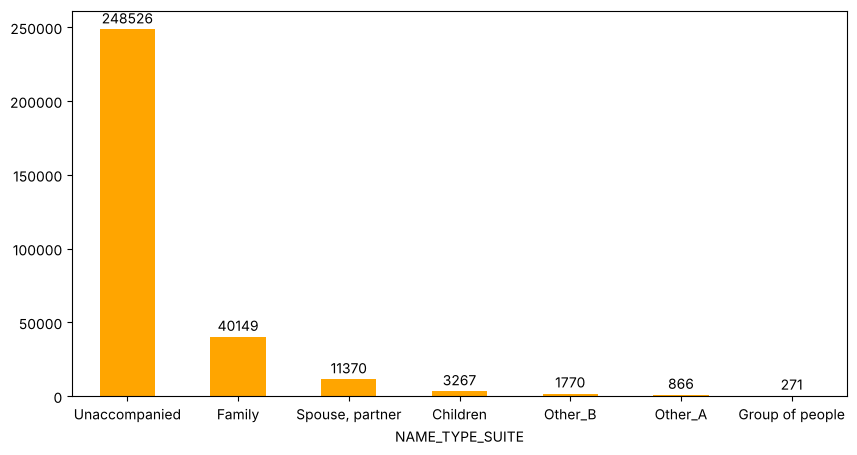

In [84]:
## Code taken from https://www.geeksforgeeks.org/how-to-annotate-bars-in-barplot-with-matplotlib-in-python/
plt.figure(figsize = (10, 5))
plots = df_train['NAME_TYPE_SUITE'].value_counts().plot(kind = 'bar', color = 'orange')
for bar in plots.patches:
    
  # Using Matplotlib's annotate function and
  # passing the coordinates where the annotation shall be done
  # x-coordinate: bar.get_x() + bar.get_width() / 2
  # y-coordinate: bar.get_height()
  # free space to be left to make graph pleasing: (0, 8)
  # ha and va stand for the horizontal and vertical alignment
    plots.annotate(format(bar.get_height(), '.0f'), 
                   (bar.get_x() + bar.get_width() / 2, 
                    bar.get_height()), ha='center', va='center',
                   size=10, xytext=(0, 8),
                   textcoords='offset points')
plt.xticks(rotation = 0)
plt.show()

In [85]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## Counting the cases for default and non-default

We will be using the barplot to visualize the total number of people who have defaulted on a loan and people who have not defaulted on a loan. This will give us a good idea about whether we have a balanced data or imbalanced data.

If it is an imbalanced data, we are going to be performing sampling so that the total number of data points in the majority class are equal to the number of minority class respectively.

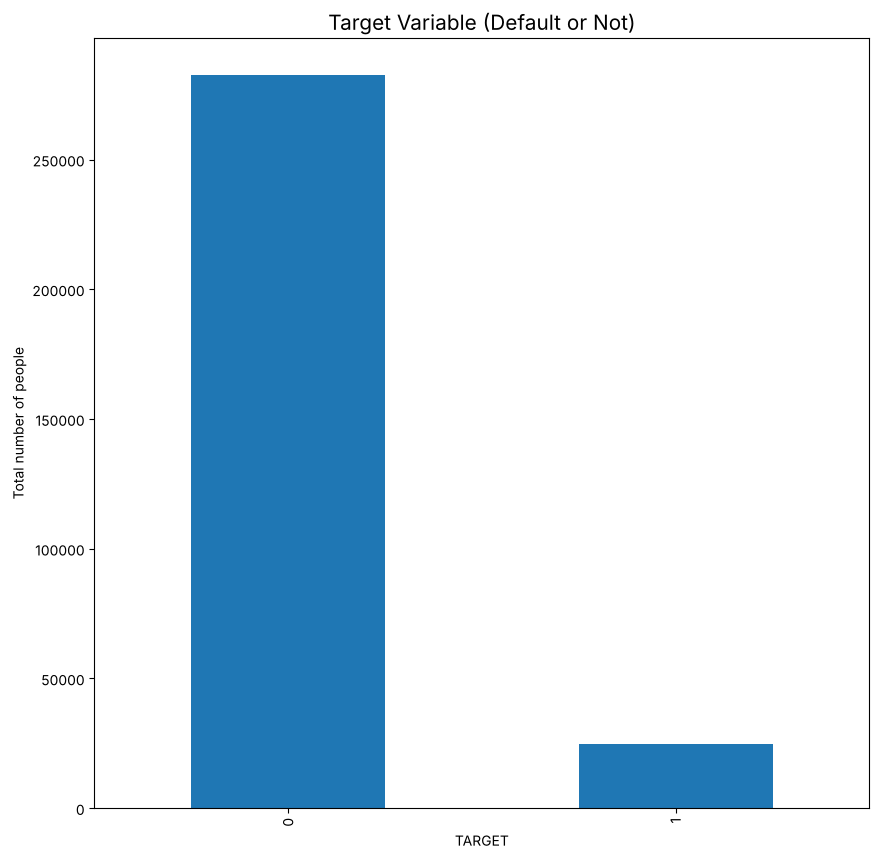

In [86]:
plt.figure(figsize = (10, 10))
plt.title("Target Variable (Default or Not)", fontsize = 15)
plt.xlabel("Default or not")
plt.ylabel("Total number of people")
df_train['TARGET'].value_counts().plot(kind = 'bar')
plt.show()


## Observation:

1. It would be seen that there is a wide gap between the number of people who have defaulted on a loan compared to the total number of people who have not defaulted on a loan.
2. The total number of people who have defaulted on a loan are about 4,000 while the people who did not default on a loan are around 25,00,000. 

Below we are going to be checking if there are NULL values present in our data. We see that there are quite a few null values present in our occupation type. Those values are printed below as can be seen. 

In [87]:
print("Are there any null values for the occupation type?\n")
if any(df_train['OCCUPATION_TYPE'].isnull()):
    print("Yes, there are null values for occupation type feature")
else:
    print("No, there are no null values for occupation type feature")

Are there any null values for the occupation type?

Yes, there are null values for occupation type feature


## Function to Calculate Null Percentage Values 
Now, it is time to calculate the NULL percentage values in our data. We are going to be predicting the NULL percentage values that are present in our data.  

In [88]:
def null_percentage(data):
    null_values_total = data.isnull().sum().sort_values(ascending = False)
    total_null_percent = (data.isnull().sum()/data.isnull().count() * 100).sort_values(ascending = False)
    return pd.concat([null_values_total, total_null_percent], axis = 1, keys = ['Total', 'Percent'])

We are going to be predicting the percentage of NULL values based on different features respectively. 

In [89]:
null_percentage(df_train[['NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']])

,Total,Percent
OCCUPATION_TYPE,96391,31.345545
NAME_HOUSING_TYPE,0,0.000000


Now, it is time to use the function that we have created earlier and we are going to consider the different values that are present for features. 

In [90]:
null_percentage(df_train)[0: 30]

,Total,Percent
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


## Missingno Library 
It is now time to use the missingno library that would plot the number of missing values when we consider those matrix values. The features would be marked on the y-axis. 

In [91]:
import missingno as msno

Below is a plot that is generated using missingno. We see that there are quite a few missing values for a lot of features. There are white dashes that represent missing NULL values. 

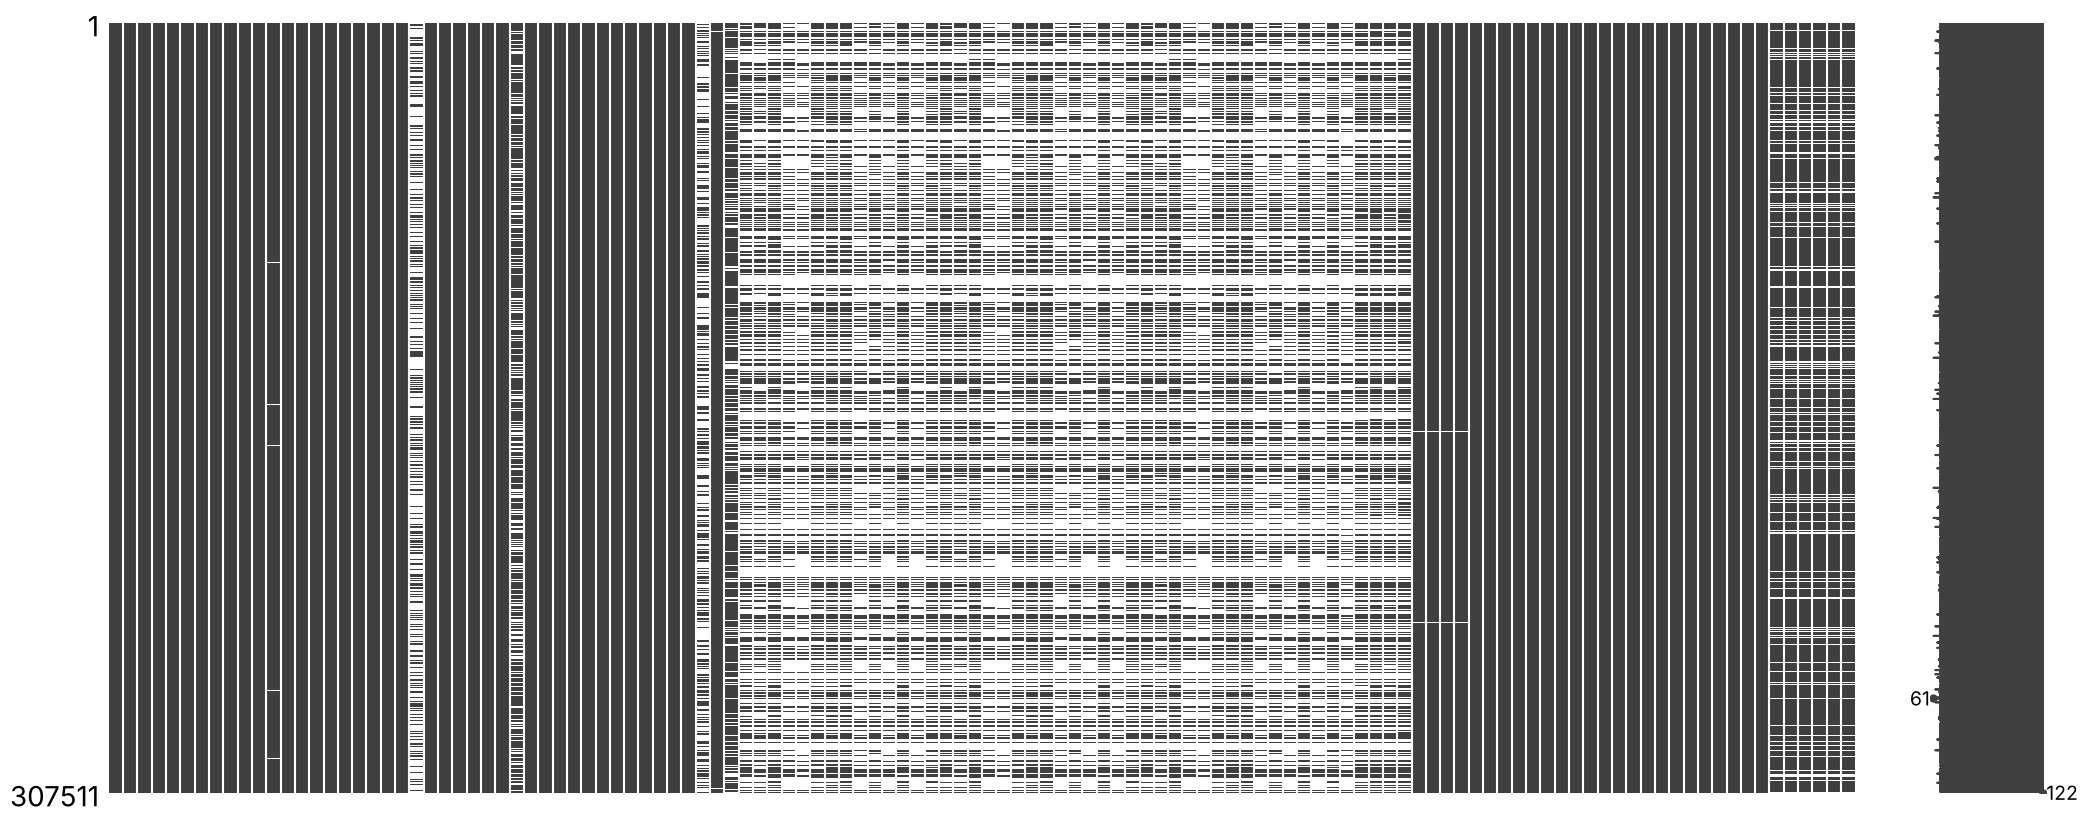

In [92]:
msno.matrix(df_train)
plt.show()

We select the amount goods price values below just to get an idea about the float values present. 

In [93]:
df_train.select_dtypes('float')['AMT_GOODS_PRICE']

0          351000.0
1         1129500.0
2          135000.0
3          297000.0
4          513000.0
            ...    
307506     225000.0
307507     225000.0
307508     585000.0
307509     319500.0
307510     675000.0
Name: AMT_GOODS_PRICE, Length: 307511, dtype: float64

Taking into account the bureau information along with various features that are important. 

In [94]:
len(df_train)

307511

In [95]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Let us also read the test dataframe values just to make sure that we are working with the right data. 

In [96]:
df_test.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


Let us now print the values of the train data and the test data respectively. We see that there are different values. 

In [97]:
print("The shape of the training dataset is: {}".format(df_train.shape))
print("The shape of the testing dataset is: {}".format(df_test.shape))

The shape of the training dataset is: (307511, 122)
The shape of the testing dataset is: (48744, 121)


In [98]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [99]:
df_train.select_dtypes('float').shape

(307511, 65)

In [100]:
df_train.select_dtypes('float')

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_REGISTRATION,OWN_CAR_AGE,CNT_FAM_MEMBERS,EXT_SOURCE_1,EXT_SOURCE_2,...,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,202500.0,406597.5,24700.5,351000.0,0.018801,-3648.0,NaN,1.0,0.083037,0.262949,...,2.0,2.0,2.0,-1134.0,0.0,0.0,0.0,0.0,0.0,1.0
1,270000.0,1293502.5,35698.5,1129500.0,0.003541,-1186.0,NaN,2.0,0.311267,0.622246,...,0.0,1.0,0.0,-828.0,0.0,0.0,0.0,0.0,0.0,0.0
2,67500.0,135000.0,6750.0,135000.0,0.010032,-4260.0,26.0,1.0,NaN,0.555912,...,0.0,0.0,0.0,-815.0,0.0,0.0,0.0,0.0,0.0,0.0
3,135000.0,312682.5,29686.5,297000.0,0.008019,-9833.0,NaN,2.0,NaN,0.650442,...,0.0,2.0,0.0,-617.0,NaN,NaN,NaN,NaN,NaN,NaN
4,121500.0,513000.0,21865.5,513000.0,0.028663,-4311.0,NaN,1.0,NaN,0.322738,...,0.0,0.0,0.0,-1106.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,157500.0,254700.0,27558.0,225000.0,0.032561,-8456.0,NaN,1.0,0.145570,0.681632,...,0.0,0.0,0.0,-273.0,NaN,NaN,NaN,NaN,NaN,NaN
307507,72000.0,269550.0,12001.5,225000.0,0.025164,-4388.0,NaN,1.0,NaN,0.115992,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
307508,153000.0,677664.0,29979.0,585000.0,0.005002,-6737.0,NaN,1.0,0.744026,0.535722,...,0.0,6.0,0.0,-1909.0,1.0,0.0,0.0,1.0,0.0,1.0
307509,171000.0,370107.0,20205.0,319500.0,0.005313,-2562.0,NaN,2.0,NaN,0.514163,...,0.0,0.0,0.0,-322.0,0.0,0.0,0.0,0.0,0.0,0.0


In [101]:
def null_percentage(data):
    null_values_total = data.isnull().sum().sort_values(ascending = False)
    total_null_percent = (data.isnull().sum()/data.isnull().count() * 100).sort_values(ascending = False)
    return pd.concat([null_values_total, total_null_percent], axis = 1, keys = ['Total', 'Percent'])

In [102]:
null_percentage(df_train).iloc[0: 5]

,Total,Percent
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963


Now it is time to plot those NULL values present and calculate the top 50 NULL values respectively. 

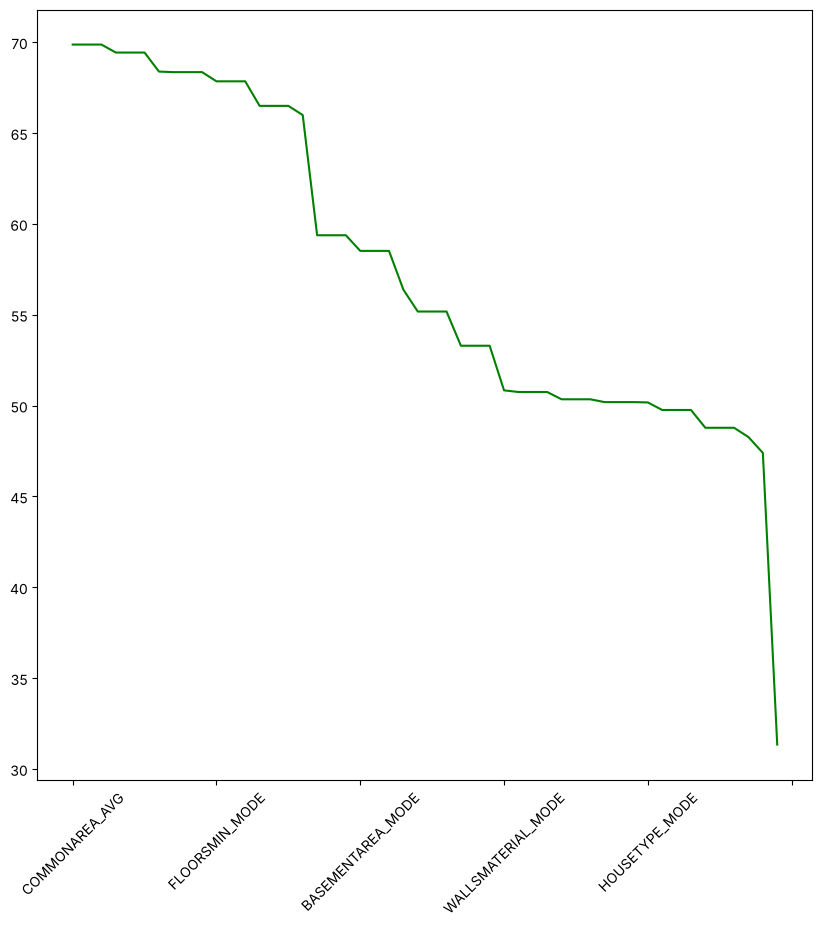

In [103]:
plt.figure(figsize = (10, 10))
null_percentage(df_train).iloc[0: 50]['Percent'].plot(color = 'green')
plt.xticks(rotation = 45)
plt.show()

In [104]:
df_train.shape

(307511, 122)

Taking a look at different features, we are going to be converting those values and removing features that contain more than 50 percent of NULL values respectively. 

In [105]:
for column in df_train.columns:
    if null_percentage(df_train[column].to_frame())['Percent'].iloc[0] > 50.00:  # [Colab fix] .iloc[0]
        df_train.drop([column], axis = 1, inplace = True)

In [106]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [107]:
df_train.shape

(307511, 81)

We have removed the percentage of NULL values that are above 50. Therefore, we are only considering features that contain values that are below 50 percent respectively. 

In [108]:
null_percentage(df_train).iloc[0: 30]

,Total,Percent
FLOORSMAX_MEDI,153020,49.760822
FLOORSMAX_AVG,153020,49.760822
FLOORSMAX_MODE,153020,49.760822
YEARS_BEGINEXPLUATATION_AVG,150007,48.781019
YEARS_BEGINEXPLUATATION_MEDI,150007,48.781019
YEARS_BEGINEXPLUATATION_MODE,150007,48.781019
TOTALAREA_MODE,148431,48.268517
EMERGENCYSTATE_MODE,145755,47.398304
OCCUPATION_TYPE,96391,31.345545
EXT_SOURCE_3,60965,19.825307


We are going to take the head of the dataframe and take a look at the dataframe that contains the training values respectively. 

In [109]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


We are going to be predicting the top 20 negative features by using the function that we have created earlier. 

In [110]:
(df_train.isnull().sum() / df_train.isnull().count()).sort_values(ascending = False).iloc[0: 20]

FLOORSMAX_MEDI                  0.497608
FLOORSMAX_AVG                   0.497608
FLOORSMAX_MODE                  0.497608
YEARS_BEGINEXPLUATATION_AVG     0.487810
YEARS_BEGINEXPLUATATION_MEDI    0.487810
YEARS_BEGINEXPLUATATION_MODE    0.487810
TOTALAREA_MODE                  0.482685
EMERGENCYSTATE_MODE             0.473983
OCCUPATION_TYPE                 0.313455
EXT_SOURCE_3                    0.198253
AMT_REQ_CREDIT_BUREAU_YEAR      0.135016
AMT_REQ_CREDIT_BUREAU_QRT       0.135016
AMT_REQ_CREDIT_BUREAU_HOUR      0.135016
AMT_REQ_CREDIT_BUREAU_MON       0.135016
AMT_REQ_CREDIT_BUREAU_WEEK      0.135016
AMT_REQ_CREDIT_BUREAU_DAY       0.135016
NAME_TYPE_SUITE                 0.004201
OBS_30_CNT_SOCIAL_CIRCLE        0.003320
DEF_30_CNT_SOCIAL_CIRCLE        0.003320
OBS_60_CNT_SOCIAL_CIRCLE        0.003320
dtype: float64

We are going to take the top 20 values that are important for machine learning predictions. Taking a look at the different values, we are going to count the number of missing values from the below cell. 

In [111]:
# Note: this loop visits all ~307k rows one by one and takes a minute or two.
count = 0
for i in range(len(df_train)):
    if df_train.iloc[i].isnull().iloc[0] == True:  # [Colab fix] .iloc[0]
        count = count + 1

Taking a look at  different features, we are considering those values and taking predictions from the data. 

In [112]:
df_train.iloc[0].isnull().iloc[0]  # [Colab fix] .iloc[0]

np.False_

Let us see the percentage of rows that were dropped if we remove features with at least one NULL value. Below, we see that the percentage of values dropped are quite high. Therefore, we cannot remove all the features that contain NULL values. 

In [113]:
Number_of_rows_dropped = df_train.shape[0] - df_train.dropna().shape[0]
print("The total number of rows dropped is {}".format(Number_of_rows_dropped))
print("The percentage of rows dropped is {}%".format(np.round(Number_of_rows_dropped / len(df_train) * 100, 3)))

The total number of rows dropped is 222936
The percentage of rows dropped is 72.497%


In [114]:
df_train.shape

(307511, 81)

In [115]:
df_train.dropna().shape

(84575, 81)

In [116]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Again, we are going to print out the top percent of values that contain NULL values. We see that there are quite a lot of features that contain less that 50 percent of NULL values.

In [117]:
(df_train.isnull().sum() / df_train.isnull().count()).sort_values(ascending = False).iloc[0: 20]

FLOORSMAX_MEDI                  0.497608
FLOORSMAX_AVG                   0.497608
FLOORSMAX_MODE                  0.497608
YEARS_BEGINEXPLUATATION_AVG     0.487810
YEARS_BEGINEXPLUATATION_MEDI    0.487810
YEARS_BEGINEXPLUATATION_MODE    0.487810
TOTALAREA_MODE                  0.482685
EMERGENCYSTATE_MODE             0.473983
OCCUPATION_TYPE                 0.313455
EXT_SOURCE_3                    0.198253
AMT_REQ_CREDIT_BUREAU_YEAR      0.135016
AMT_REQ_CREDIT_BUREAU_QRT       0.135016
AMT_REQ_CREDIT_BUREAU_HOUR      0.135016
AMT_REQ_CREDIT_BUREAU_MON       0.135016
AMT_REQ_CREDIT_BUREAU_WEEK      0.135016
AMT_REQ_CREDIT_BUREAU_DAY       0.135016
NAME_TYPE_SUITE                 0.004201
OBS_30_CNT_SOCIAL_CIRCLE        0.003320
DEF_30_CNT_SOCIAL_CIRCLE        0.003320
OBS_60_CNT_SOCIAL_CIRCLE        0.003320
dtype: float64

In [118]:
df_train['FLOORSMAX_AVG']

0         0.0833
1         0.2917
2            NaN
3            NaN
4            NaN
           ...  
307506    0.6042
307507    0.0833
307508    0.1667
307509    0.0417
307510    0.3750
Name: FLOORSMAX_AVG, Length: 307511, dtype: float64

## Creating Mean, Median and Mode Functions

In the below cell, the functions that would return mean, median and mode for different features. By default, the inplace parameter would be False which means that the data values would not be replaced until it is set to True.

In [119]:
def mean_imputation(data, inplace = False):
    """
    This function would take the NULL values present in data and replace them with average values of the data respectively.
    """
    data.fillna(data.mean(), inplace = inplace)

def median_imputation(data, inplace = False):
    """
    This function would take the NULL values present in data and replace them with median values in our data respectively.
    """
    data.fillna(data.median(), inplace = inplace)

def mode_imputation(data, inplace = False):
    """
    This function would take the NULL values present in data and replace them with mode values of the given data respectively.
    """
    data.fillna(data.mode(), inplace = inplace)

It is time to use the mean imputation to replace the missing values with the mean values. We are going to be doing different types of imputations based on the requirements. Note that the 'inplace' parameter was set to False. However, we can also set the parameter to True in order to make permanent changes to our dataframe. 

In [120]:
mean_imputation(df_train['FLOORSMAX_AVG'])

In [121]:
df_train['FLOORSMAX_AVG']

0         0.0833
1         0.2917
2            NaN
3            NaN
4            NaN
           ...  
307506    0.6042
307507    0.0833
307508    0.1667
307509    0.0417
307510    0.3750
Name: FLOORSMAX_AVG, Length: 307511, dtype: float64

We would be performing similar operations on some of the other features in our dataframe. We see some features that are float values below. 

In [122]:
df_train[['AMT_REQ_CREDIT_BUREAU_YEAR', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON']]

,AMT_REQ_CREDIT_BUREAU_YEAR,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON
0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0
3,NaN,NaN,NaN,NaN,NaN,NaN
4,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...
307506,NaN,NaN,NaN,NaN,NaN,NaN
307507,NaN,NaN,NaN,NaN,NaN,NaN
307508,1.0,0.0,1.0,0.0,0.0,1.0
307509,0.0,0.0,0.0,0.0,0.0,0.0


Taking a look at some of the unique values for amt_req_credit_bureau_year feature. We would be taking a look at the values that are present below to get an understanding of the values. 

In [123]:
df_train['AMT_REQ_CREDIT_BUREAU_YEAR'].unique()

array([ 1.,  0., nan,  2.,  4.,  5.,  3.,  8.,  6.,  9.,  7., 10., 11.,
       13., 16., 12., 25., 23., 15., 14., 22., 17., 19., 18., 21., 20.])

We are following the same approach for amt_req_credit_bureau_week and considering those values respectively. 

In [124]:
df_train['AMT_REQ_CREDIT_BUREAU_WEEK'].unique()

array([ 0., nan,  1.,  3.,  2.,  4.,  5.,  6.,  8.,  7.])

## Countplot of amt_req_credit_bureau_year
We are going to plot a graph between the amt_req_credit_bureau_year feature and calculate important values. We are just going to use the value_counts feature that would count those values and give us the predictions respectively. 

<Axes: xlabel='AMT_REQ_CREDIT_BUREAU_YEAR'>

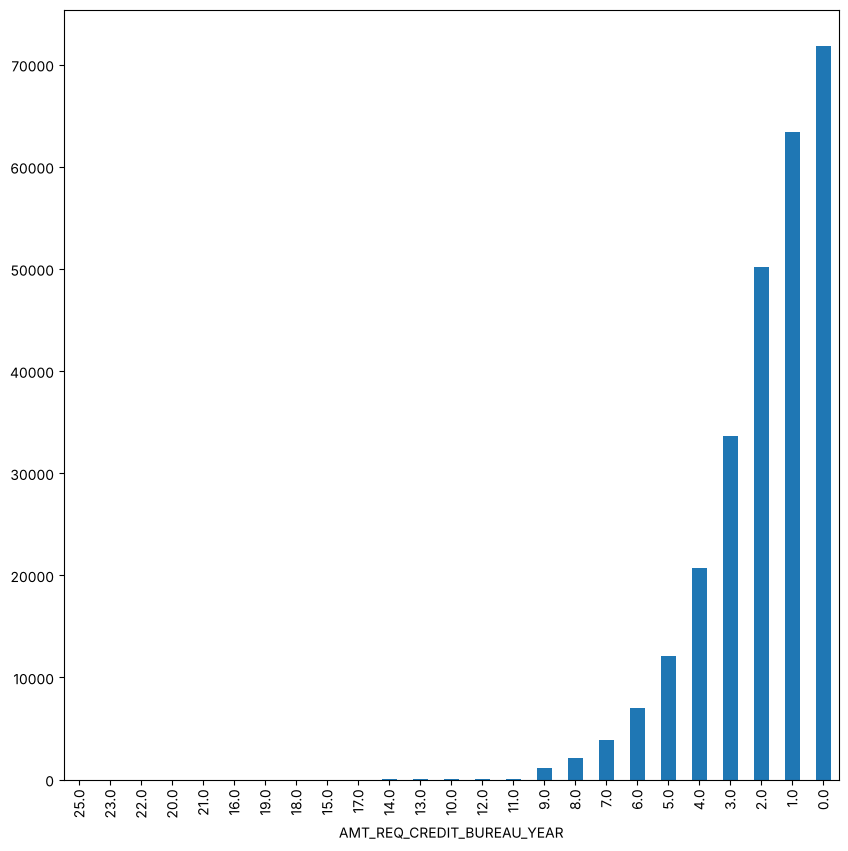

In [125]:
plt.figure(figsize = (10, 10))
df_train['AMT_REQ_CREDIT_BUREAU_YEAR'].value_counts().sort_values(ascending = True).plot(kind = 'bar')

## Countplot of amt_req_credit_bureau_hour

Now, let us also take the amt_req_credit_bureau_hour feature and plot the values. The plot could be seen below. 

<Axes: xlabel='AMT_REQ_CREDIT_BUREAU_HOUR'>

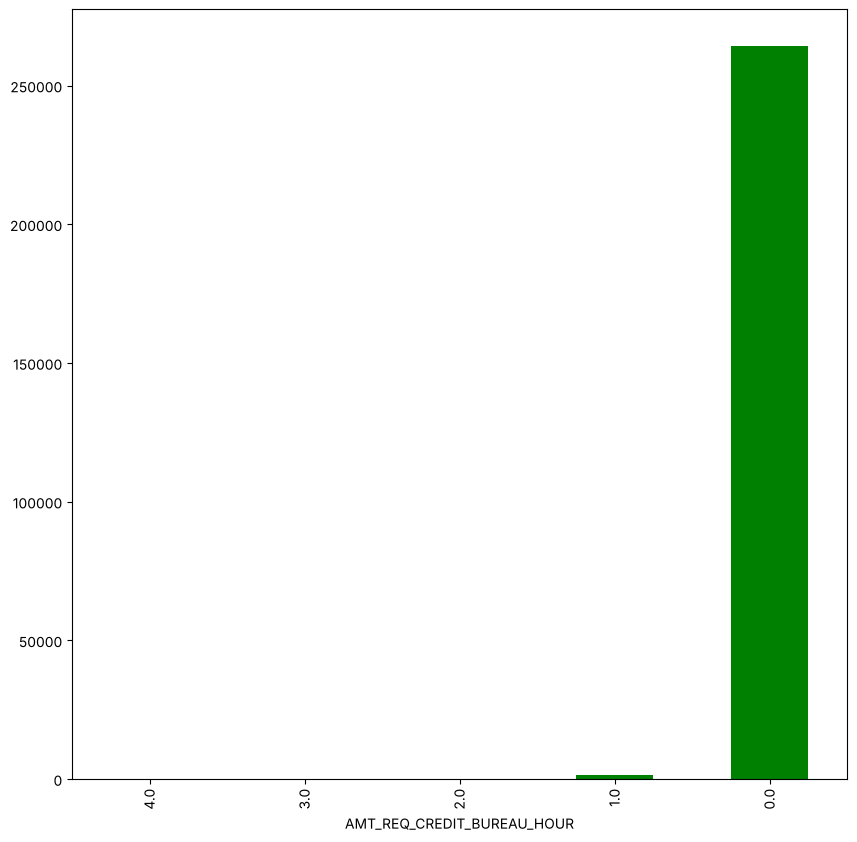

In [126]:
plt.figure(figsize = (10, 10))
df_train['AMT_REQ_CREDIT_BUREAU_HOUR'].value_counts().sort_values(ascending = True).plot(kind = 'bar', color = 'green')

In [127]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## Countplot of amt_req_credit_bureau_qrt

It is now time to get a plot of amt_req_credit_bureau_qrt and get an understanding of the data. 

<Axes: xlabel='AMT_REQ_CREDIT_BUREAU_QRT'>

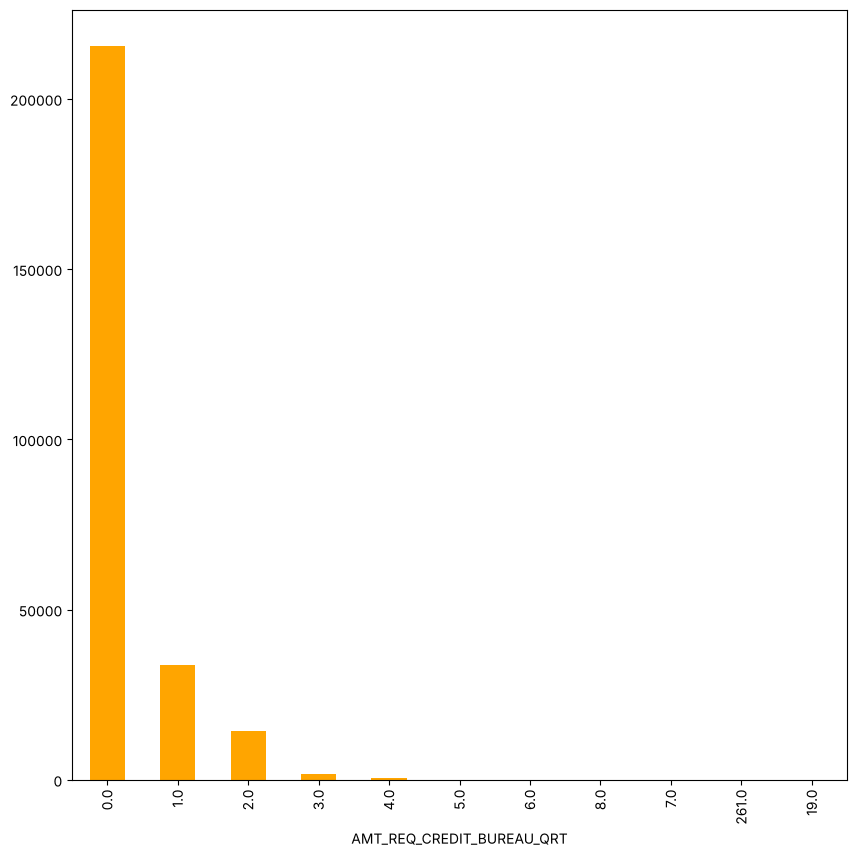

In [128]:
plt.figure(figsize = (10, 10))
df_train['AMT_REQ_CREDIT_BUREAU_QRT'].value_counts().plot(kind = 'bar', color = 'orange')

In [129]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## Countplot of NAME_CONTRACT_TYPE

Taking a look at countplot of the different types of loans, we see that most of the loans taken were cash loans. There were very few revolving loans added. 

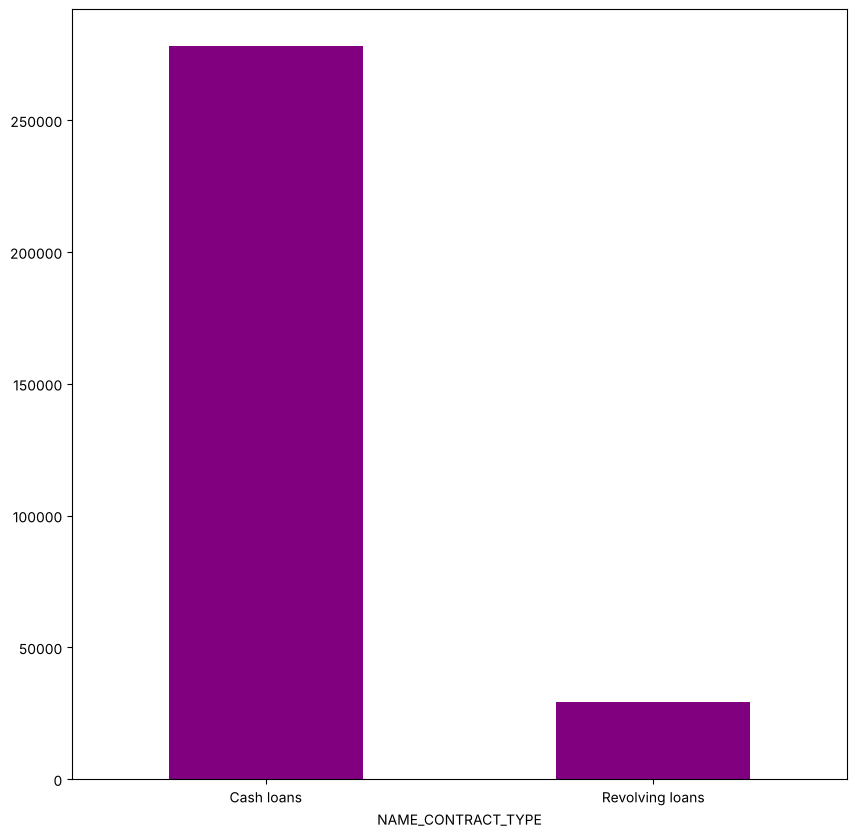

In [130]:
plt.figure(figsize = (10, 10))
df_train['NAME_CONTRACT_TYPE'].value_counts().plot(kind = 'bar', color = 'purple')
plt.xticks(rotation = 0)
plt.show()

## Countplot of CODE_GENDER
Taking a look at the countplot of male and female candidates, we are going to count the values present respectively. We see that there are more number of females than males. 

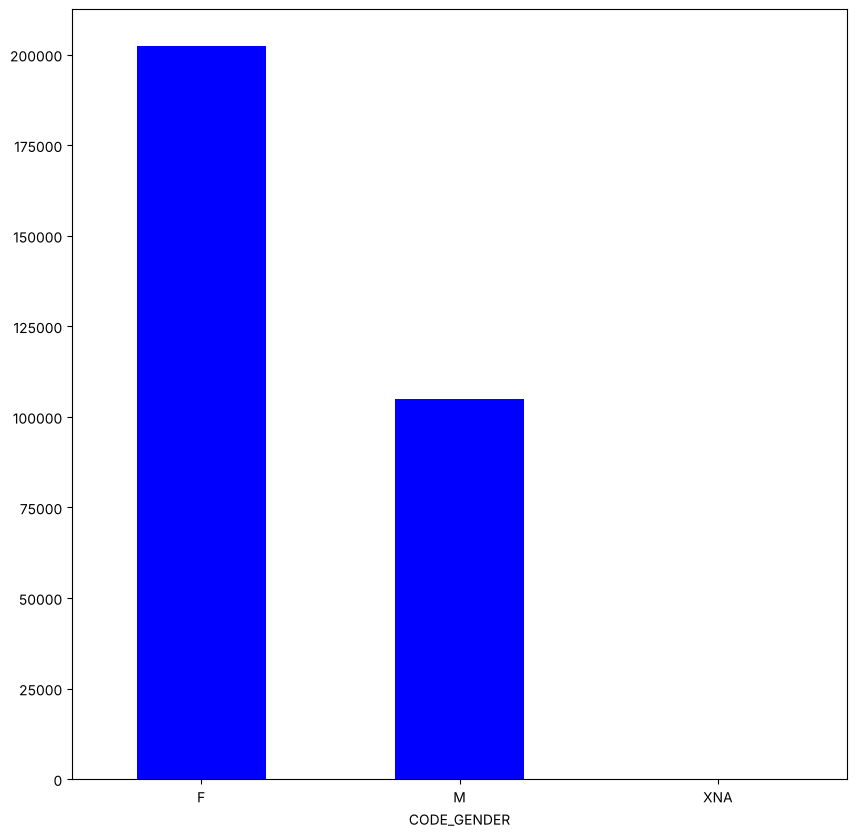

In [131]:
plt.figure(figsize = (10, 10))
df_train['CODE_GENDER'].value_counts().plot(kind = 'bar', color = 'blue')
plt.xticks(rotation = 0)
plt.show()

Taking a look at the 'XNA' gender and counting the values, we see that there are just 4 values. 

In [132]:
len(df_train[df_train['CODE_GENDER'] == 'XNA'])

4

Since there are very few values present that are of gender 'XNA', let us remove them when performing the machine learning operations. 

In [133]:
df_train = df_train[df_train['CODE_GENDER'] != 'XNA']

In [134]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [135]:
len(df_train)

307507

## Countplot of FLAG_OWN_REALTY

Taking a look at this feature, we are going to be getting only yes or no values. We see that there are many 'Yes' values compared to 'No' values respectively. 

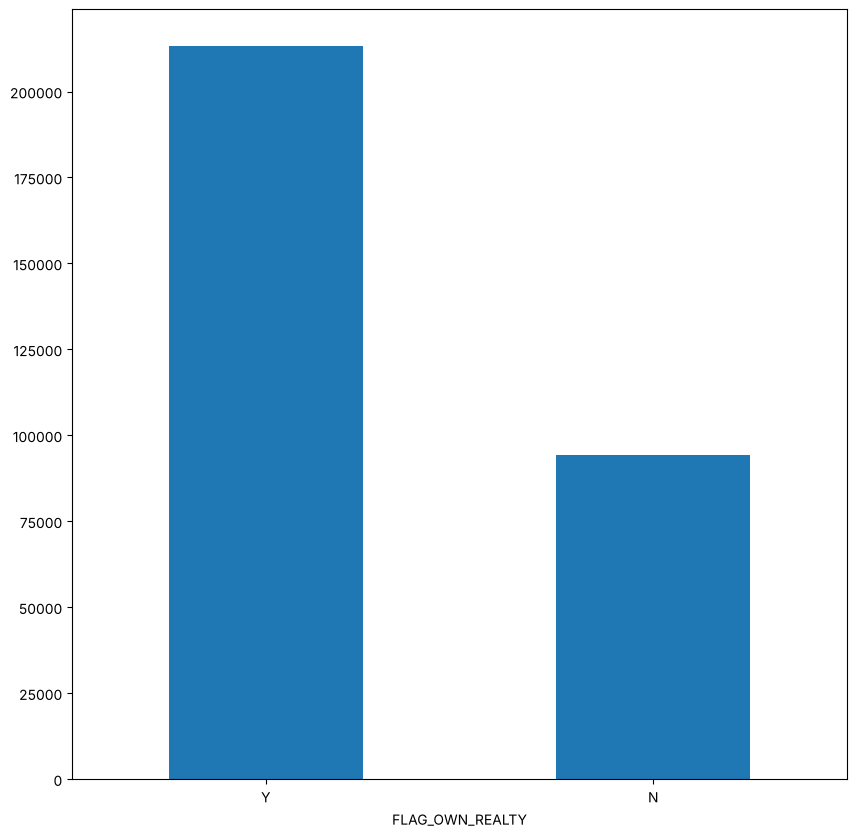

In [136]:
plt.figure(figsize = (10, 10))
df_train['FLAG_OWN_REALTY'].value_counts().plot(kind = 'bar')
plt.xticks(rotation = 0)
plt.show()

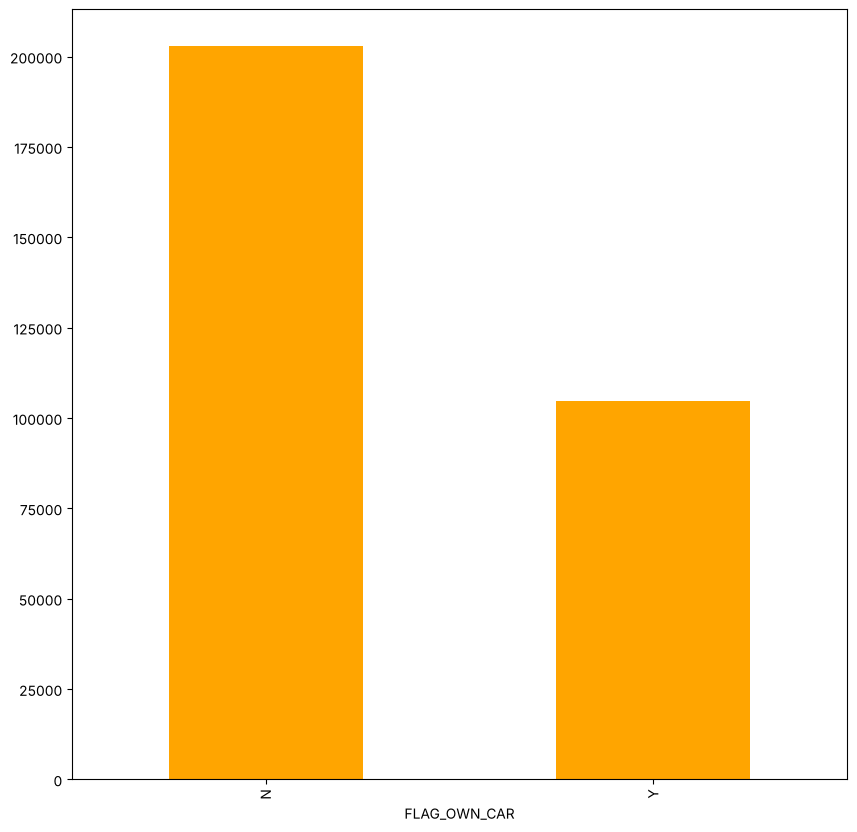

In [137]:
plt.figure(figsize = (10, 10))
df_train['FLAG_OWN_CAR'].value_counts().plot(kind = 'bar', color = 'orange')
plt.show()

## Kdeplot of AMT_INCOME_TOTAL

It is time to check the distribution of the total income amount. A large portion of the values are present in the beginning of the kdeplot and there are very few values that are really high values respectively. In addition to this, we see only a few values that are above 1 standard deviation from the mean. 

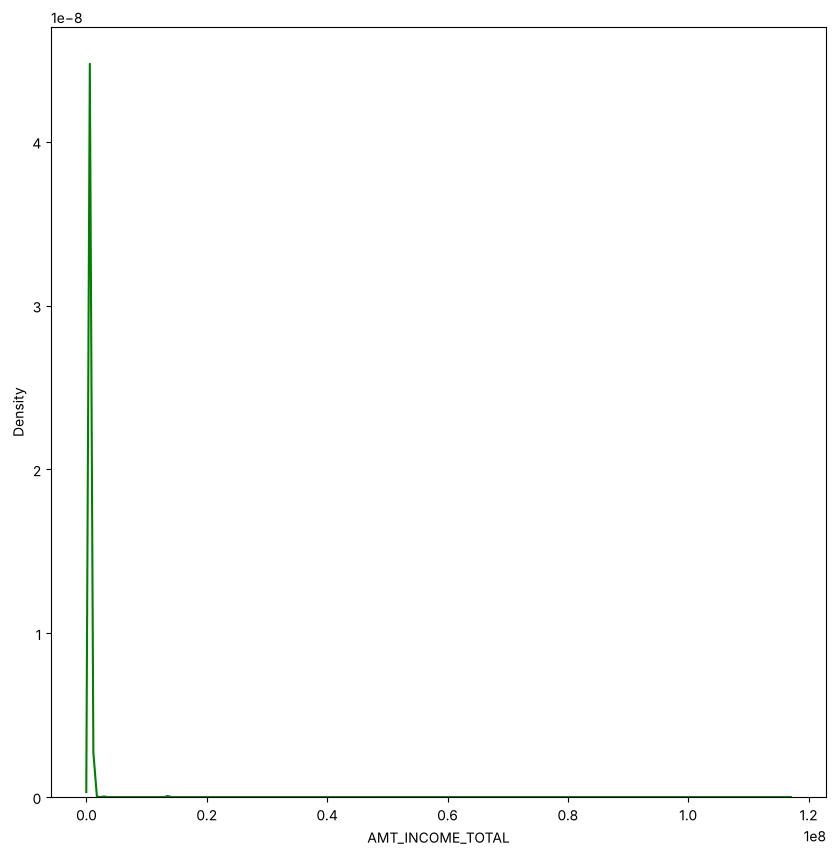

In [138]:
plt.figure(figsize = (10, 10))
sns.kdeplot(df_train['AMT_INCOME_TOTAL'], color = 'green')
plt.show()

In [139]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## Countplot of Target

Taking a look at the countplot, we get an understanding that most of the output points are of people who did not default on loan. There are very few people who have defaulted the loan. Therefore, we are dealing with an imbalanced dataset, and care must be taken when using various machine learning models for predictions. Sometimes, the KNN networks might not work well especially when the number of nearest neighbors taken is 1. If it is taken, the output that we are going to be get would be swayed towards the majority class. 

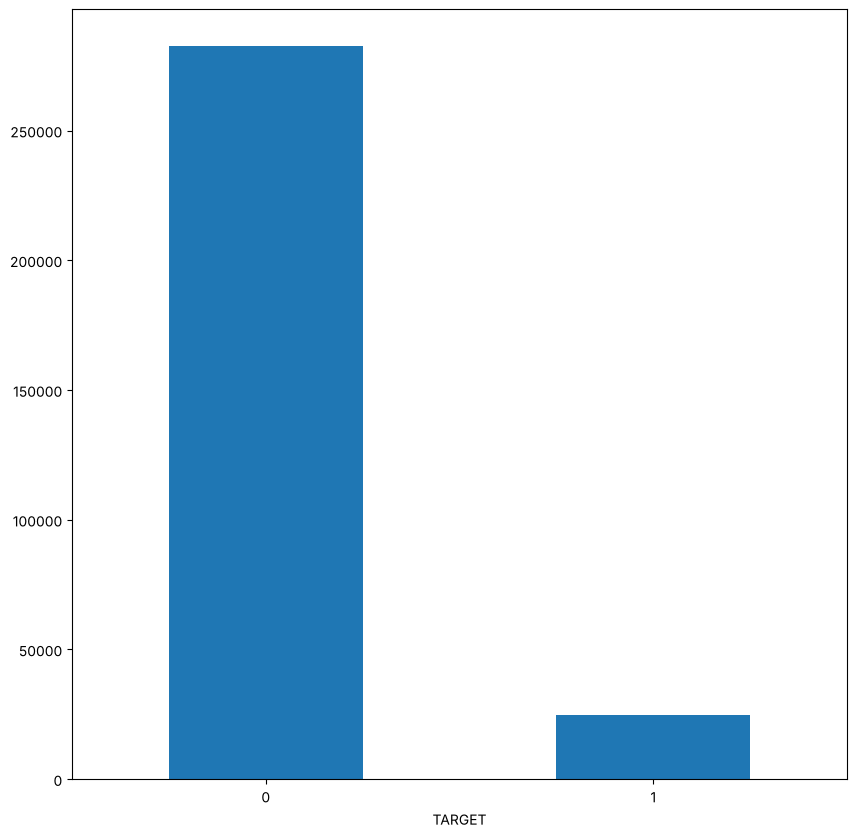

In [140]:
plt.figure(figsize = (10, 10))
df_train['TARGET'].value_counts().plot(kind = 'bar')
plt.xticks(rotation = 0)
plt.show()

## Kdeplot of AMT_INCOME_TOTAL 

Since the values that we took previously for plotting the averge income were quite high, let us restrict the values to just 800000 total income respectively. Below we see clearly that a large portion of customers have an income of about 1,00,000$ per annum respectively. There are some outliers in the data where the income is more than 6,00,000$ per annum. 

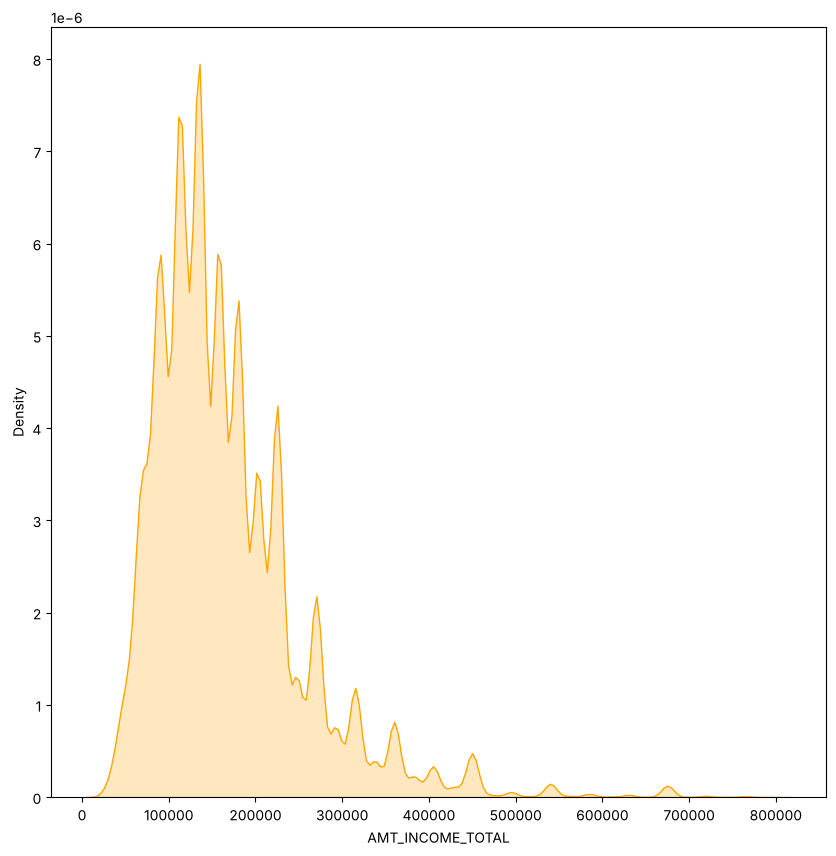

In [141]:
plt.figure(figsize = (10, 10))
sns.kdeplot(df_train[df_train['AMT_INCOME_TOTAL'] < 800000]['AMT_INCOME_TOTAL'], fill = True, color = 'orange')
plt.show()

## Kdeplot of AMT_CREDIT

In a similar fashion, the kdeplot of AMT_CREDIT is plotted below. One could get an understanding that the loan borrowed is about 25,000 dollars where most of the values lie. There are a few people who take a loan about 2,00,000 dollars but those cases are exceptionally rare. 

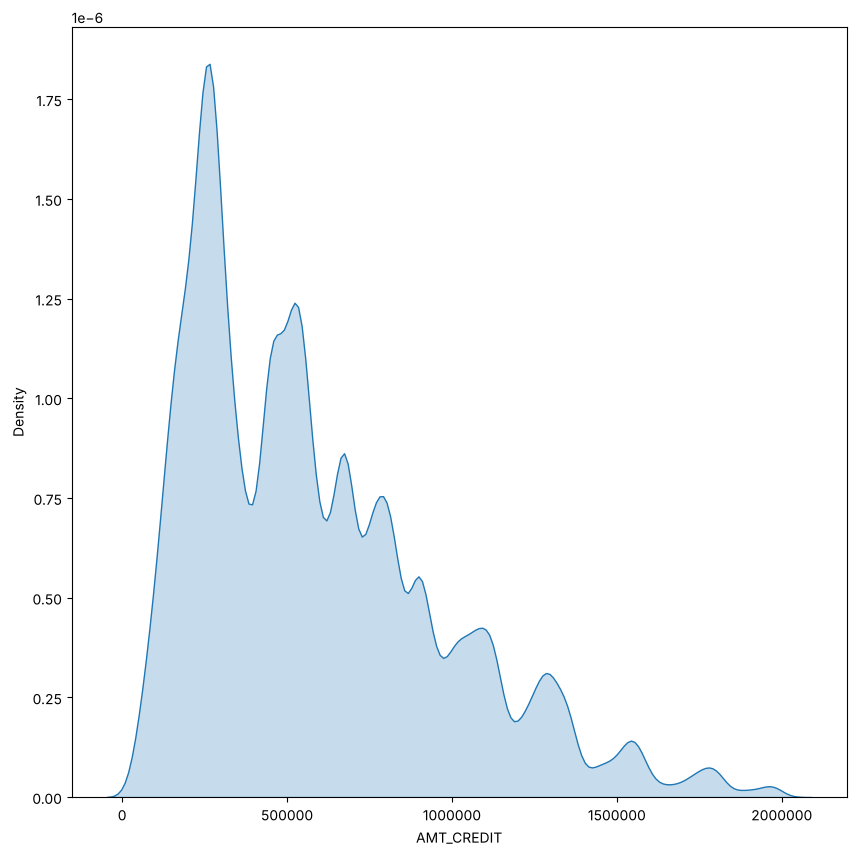

In [142]:
plt.figure(figsize = (10, 10))
sns.kdeplot(df_train[df_train['AMT_CREDIT'] < 2000000]['AMT_CREDIT'], fill = True)
plt.ticklabel_format(style = 'plain', axis = 'x')
plt.show()

Taking a look at all the columns in our data and getting a good understanding of it. 

In [143]:
df_train.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE',
       'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
       'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'FLAG_MOBIL',
       'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE',
       'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS',
       'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY',
       'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START',
       'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION',
       'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY',
       'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY',
       'ORGANIZATION_TYPE', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
       'YEARS_BEGINEXPLUATATION_AVG', 'FLOOR

Let us now read the head of the dataframe and understand the different columns once again to get a good understanding of the data. 

In [144]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Let us consider only the top 30 percent of values present in our data. We are going to be taking those values and we are getting an understanding of the missing values based on the function that we have created earlier. 

In [145]:
null_percentage(df_train).iloc[0: 30]['Percent']

FLOORSMAX_MEDI                  49.761144
FLOORSMAX_AVG                   49.761144
FLOORSMAX_MODE                  49.761144
YEARS_BEGINEXPLUATATION_AVG     48.781329
YEARS_BEGINEXPLUATATION_MEDI    48.781329
YEARS_BEGINEXPLUATATION_MODE    48.781329
TOTALAREA_MODE                  48.268820
EMERGENCYSTATE_MODE             47.398596
OCCUPATION_TYPE                 31.345303
EXT_SOURCE_3                    19.825565
AMT_REQ_CREDIT_BUREAU_YEAR      13.501806
AMT_REQ_CREDIT_BUREAU_QRT       13.501806
AMT_REQ_CREDIT_BUREAU_HOUR      13.501806
AMT_REQ_CREDIT_BUREAU_MON       13.501806
AMT_REQ_CREDIT_BUREAU_WEEK      13.501806
AMT_REQ_CREDIT_BUREAU_DAY       13.501806
NAME_TYPE_SUITE                  0.420153
OBS_30_CNT_SOCIAL_CIRCLE         0.332025
DEF_30_CNT_SOCIAL_CIRCLE         0.332025
OBS_60_CNT_SOCIAL_CIRCLE         0.332025
DEF_60_CNT_SOCIAL_CIRCLE         0.332025
EXT_SOURCE_2                     0.214629
AMT_GOODS_PRICE                  0.090404
AMT_ANNUITY                      0

Let us take a look at some of our columns that we are going to be working with in our data. 

In [146]:
df_train.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE',
       'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
       'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'FLAG_MOBIL',
       'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE',
       'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS',
       'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY',
       'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START',
       'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION',
       'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY',
       'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY',
       'ORGANIZATION_TYPE', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
       'YEARS_BEGINEXPLUATATION_AVG', 'FLOOR

In [147]:
null_percentage(df_train).iloc[0: 30]['Percent']

FLOORSMAX_MEDI                  49.761144
FLOORSMAX_AVG                   49.761144
FLOORSMAX_MODE                  49.761144
YEARS_BEGINEXPLUATATION_AVG     48.781329
YEARS_BEGINEXPLUATATION_MEDI    48.781329
YEARS_BEGINEXPLUATATION_MODE    48.781329
TOTALAREA_MODE                  48.268820
EMERGENCYSTATE_MODE             47.398596
OCCUPATION_TYPE                 31.345303
EXT_SOURCE_3                    19.825565
AMT_REQ_CREDIT_BUREAU_YEAR      13.501806
AMT_REQ_CREDIT_BUREAU_QRT       13.501806
AMT_REQ_CREDIT_BUREAU_HOUR      13.501806
AMT_REQ_CREDIT_BUREAU_MON       13.501806
AMT_REQ_CREDIT_BUREAU_WEEK      13.501806
AMT_REQ_CREDIT_BUREAU_DAY       13.501806
NAME_TYPE_SUITE                  0.420153
OBS_30_CNT_SOCIAL_CIRCLE         0.332025
DEF_30_CNT_SOCIAL_CIRCLE         0.332025
OBS_60_CNT_SOCIAL_CIRCLE         0.332025
DEF_60_CNT_SOCIAL_CIRCLE         0.332025
EXT_SOURCE_2                     0.214629
AMT_GOODS_PRICE                  0.090404
AMT_ANNUITY                      0

In [148]:
df_train['YEARS_BEGINEXPLUATATION_AVG']

0         0.9722
1         0.9851
2            NaN
3            NaN
4            NaN
           ...  
307506    0.9876
307507    0.9727
307508    0.9816
307509    0.9771
307510    0.9881
Name: YEARS_BEGINEXPLUATATION_AVG, Length: 307507, dtype: float64

## Mean Imputation 

There are some features in our dataset that require mean imputation. We are going to only consider those values that require mean imputation. However, there are other values that require median or mode imputation depending on the feature. 

In [149]:
# [Colab fix] Same effect as the original `mean_imputation(df_train[col], inplace = True)` calls,
# written as an assignment so it also works with pandas Copy-on-Write.
for col in ['FLOORSMAX_AVG', 'FLOORSMAX_MEDI', 'FLOORSMAX_MODE',
            'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BEGINEXPLUATATION_MEDI', 'YEARS_BEGINEXPLUATATION_MODE']:
    df_train[col] = df_train[col].fillna(df_train[col].mean())

In [150]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Now that we have imputed the mean values of some of NULL values, we are going to create a function that would take into account the NULL values and impute the mean value of the entire row respectively. We've created that function below. 

In [151]:
count = 0
def null_columns(dataframe):
    count = 0
    null_features = []
    for i in range(len(dataframe.columns)):
        if any(df_train[dataframe.columns[i]].isnull()):
            count = count + 1
            null_features.append(dataframe.columns[i])
    return null_features, count

In [152]:
null_columns, total_null_features = null_columns(df_train)

Taking into account the missingno matrix that would consider the NULL values and give us a pictorial representation of them. Taking a look at the plot below, we can come to a conclusion that there are still many missing values that we must be dealing with before giving them to the machine learning models for predictions. 

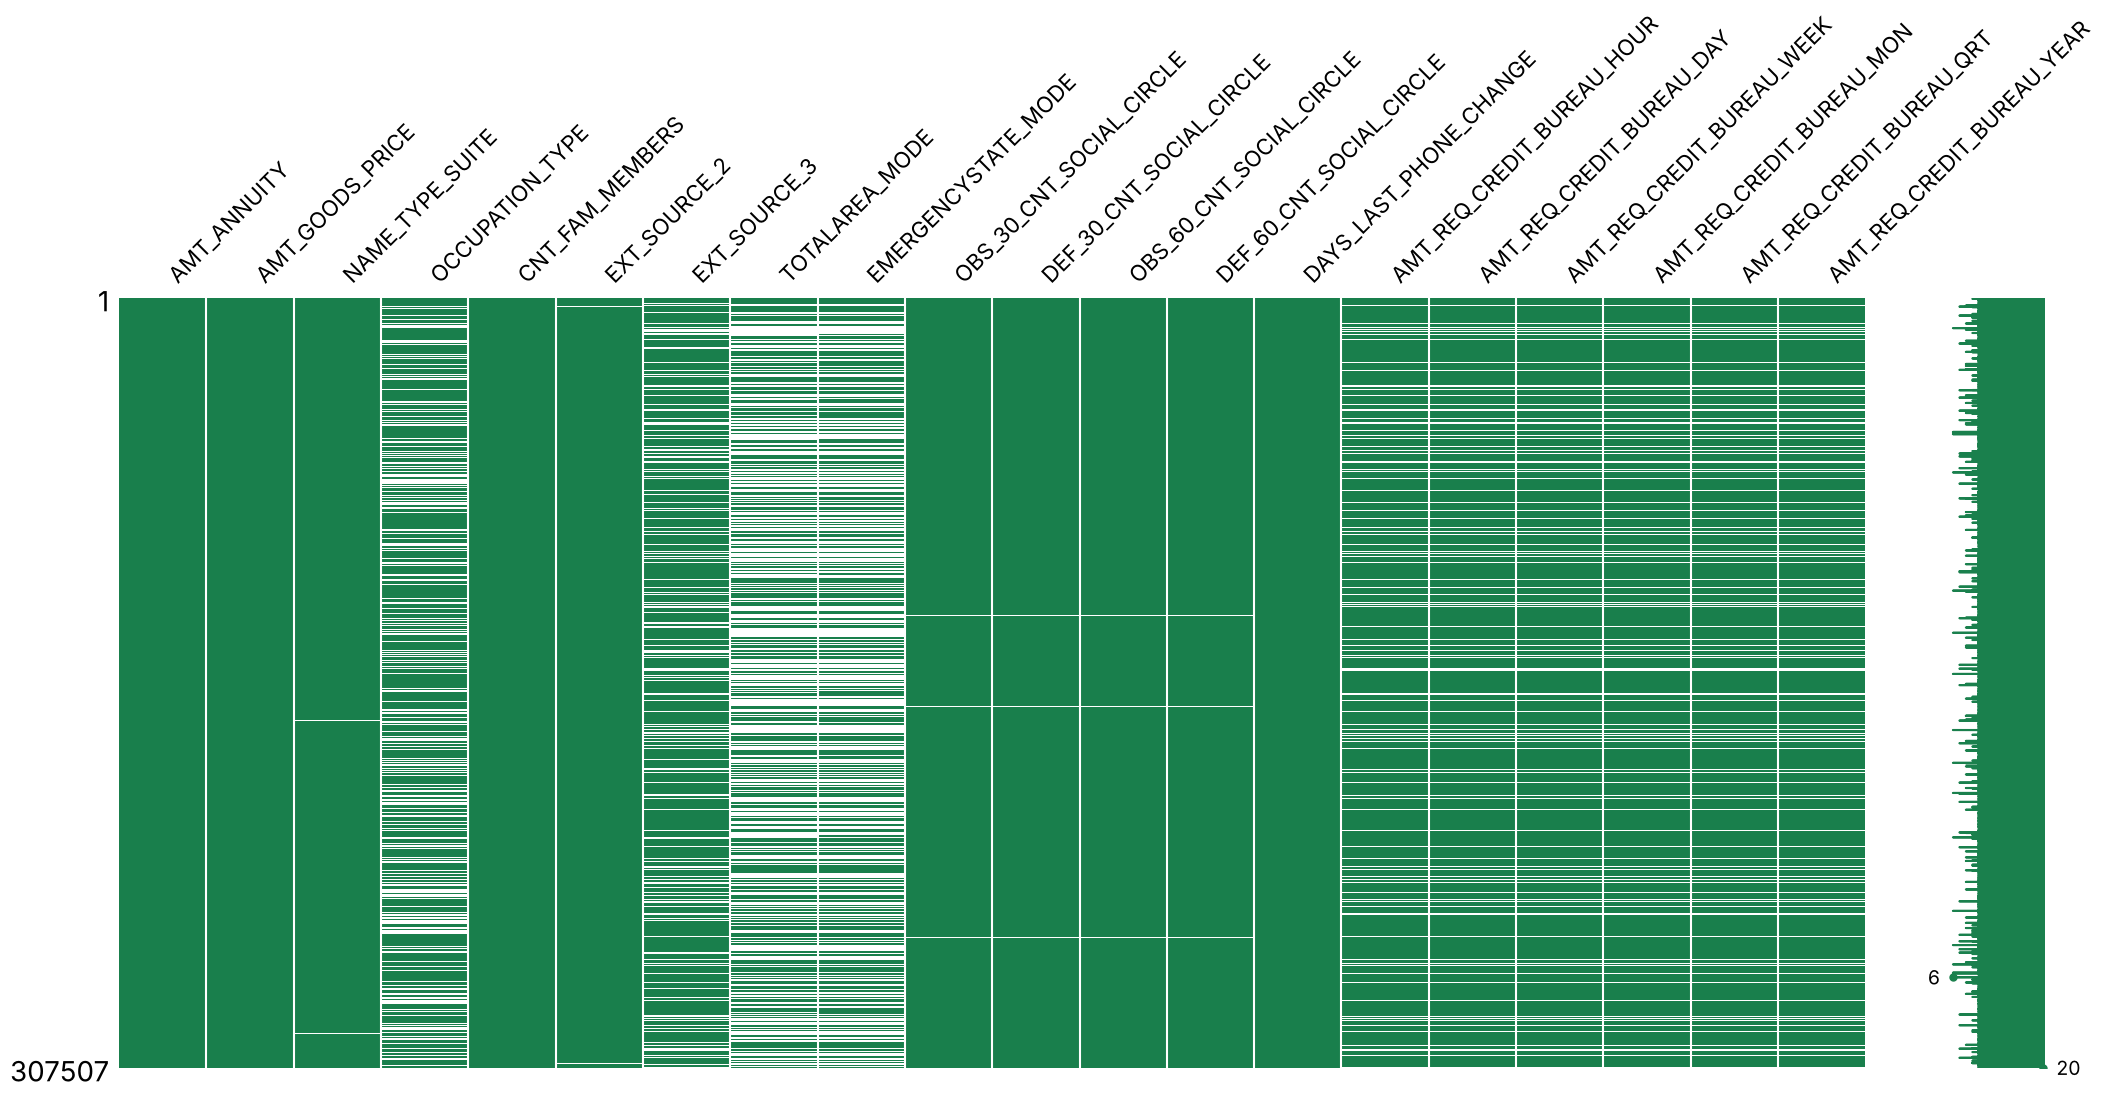

In [153]:
msno.matrix(df_train[null_columns], color = (0.1, 0.5, 0.3))
plt.show()

In [154]:
null_percent_values = null_percentage(df_train)['Percent']
features_with_low_null_values = []
for i in range(len(df_train.columns)):
    if null_percent_values.iloc[i] < 10.0:
        features_with_low_null_values.append(null_percent_values.index[i]) 

In [155]:
features_with_low_null_values

['NAME_TYPE_SUITE',
 'DEF_60_CNT_SOCIAL_CIRCLE',
 'OBS_30_CNT_SOCIAL_CIRCLE',
 'DEF_30_CNT_SOCIAL_CIRCLE',
 'OBS_60_CNT_SOCIAL_CIRCLE',
 'EXT_SOURCE_2',
 'AMT_GOODS_PRICE',
 'AMT_ANNUITY',
 'CNT_FAM_MEMBERS',
 'DAYS_LAST_PHONE_CHANGE',
 'NAME_HOUSING_TYPE',
 'NAME_INCOME_TYPE',
 'CNT_CHILDREN',
 'NAME_FAMILY_STATUS',
 'NAME_EDUCATION_TYPE',
 'FLAG_OWN_CAR',
 'CODE_GENDER',
 'NAME_CONTRACT_TYPE',
 'FLAG_OWN_REALTY',
 'TARGET',
 'SK_ID_CURR',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'REGION_POPULATION_RELATIVE',
 'WEEKDAY_APPR_PROCESS_START',
 'REGION_RATING_CLIENT_W_CITY',
 'REG_REGION_NOT_LIVE_REGION',
 'HOUR_APPR_PROCESS_START',
 'FLAG_MOBIL',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'FLAG_CONT_MOBILE',
 'FLAG_WORK_PHONE',
 'FLAG_EMAIL',
 'FLAG_PHONE',
 'REGION_RATING_CLIENT',
 'FLAG_EMP_PHONE',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'FLOORSMAX_MEDI',
 'YEARS_BEGINEXPLUATATION_MEDI',
 'FLOORSMAX_MODE',
 'YEARS_BEGINEXPLUATATION_MODE',
 'YEARS_BEGINEXPLUATATION_AVG',
 'FLOORSMAX_AVG',
 'LIVE_

In [156]:
df_train[features_with_low_null_values].head()

,NAME_TYPE_SUITE,DEF_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,Unaccompanied,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,...,0,0,0,0,0,0,0,0,0,0
1,Family,0.0,1.0,0.0,1.0,0.622246,1129500.0,35698.5,2.0,-828.0,...,0,0,0,0,0,0,0,0,0,0
2,Unaccompanied,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,...,0,0,0,0,0,0,0,0,0,0
3,Unaccompanied,0.0,2.0,0.0,2.0,0.650442,297000.0,29686.5,2.0,-617.0,...,0,0,0,0,0,0,0,0,0,0
4,Unaccompanied,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,...,0,0,0,0,0,0,0,0,0,0


In [157]:
df_train[features_with_low_null_values].shape

(307507, 71)

In [158]:
null_percentage(df_train[features_with_low_null_values])

,Total,Percent
NAME_TYPE_SUITE,1292,0.420153
DEF_60_CNT_SOCIAL_CIRCLE,1021,0.332025
OBS_30_CNT_SOCIAL_CIRCLE,1021,0.332025
DEF_30_CNT_SOCIAL_CIRCLE,1021,0.332025
OBS_60_CNT_SOCIAL_CIRCLE,1021,0.332025
...,...,...
FLAG_DOCUMENT_16,0,0.000000
FLAG_DOCUMENT_15,0,0.000000
FLAG_DOCUMENT_14,0,0.000000
FLAG_DOCUMENT_20,0,0.000000


In [159]:
df_train[features_with_low_null_values]['NAME_TYPE_SUITE'].value_counts()

NAME_TYPE_SUITE
Unaccompanied      248523
Family              40148
Spouse, partner     11370
Children             3267
Other_B              1770
Other_A               866
Group of people       271
Name: count, dtype: int64

In [160]:
df_train[features_with_low_null_values].head()

,NAME_TYPE_SUITE,DEF_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,Unaccompanied,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,...,0,0,0,0,0,0,0,0,0,0
1,Family,0.0,1.0,0.0,1.0,0.622246,1129500.0,35698.5,2.0,-828.0,...,0,0,0,0,0,0,0,0,0,0
2,Unaccompanied,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,...,0,0,0,0,0,0,0,0,0,0
3,Unaccompanied,0.0,2.0,0.0,2.0,0.650442,297000.0,29686.5,2.0,-617.0,...,0,0,0,0,0,0,0,0,0,0
4,Unaccompanied,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,...,0,0,0,0,0,0,0,0,0,0


In [161]:
df_train_converted = df_train[features_with_low_null_values]

In the cell below, we've considered only the categorical values from features. We would be taking those values and applying the mode imputation which would ensure that we are getting the best results on our test set respectively. We would have to impute those values with the mode so that we get good results and reduce the NULL values. 

In [162]:
## This is done to get the categorical features. We can then perform mode imputation to get the values respectively.
## The suggestion was implemented from the website https://stackoverflow.com/questions/29803093/check-which-columns-in-dataframe-are-categorical
total_columns =df_train_converted.columns 
numeric_data = df_train_converted._get_numeric_data()
categorical_columns = list(set(total_columns) - set(numeric_data.columns))

In [163]:
df_train_converted[categorical_columns].head()

,WEEKDAY_APPR_PROCESS_START,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,FLAG_OWN_CAR
0,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Business Entity Type 3,Unaccompanied,N
1,MONDAY,House / apartment,Higher education,State servant,N,F,Married,Cash loans,School,Family,N
2,MONDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Revolving loans,Government,Unaccompanied,Y
3,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,F,Civil marriage,Cash loans,Business Entity Type 3,Unaccompanied,N
4,THURSDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Religion,Unaccompanied,N


Now, we see that lot of features that had a lot of NULL values are now imputed with mean and mode respectively. There are a few features that contain NULL values. We have to take a look at those features and fill those values so that we get the best results on the test set. 

<Axes: >

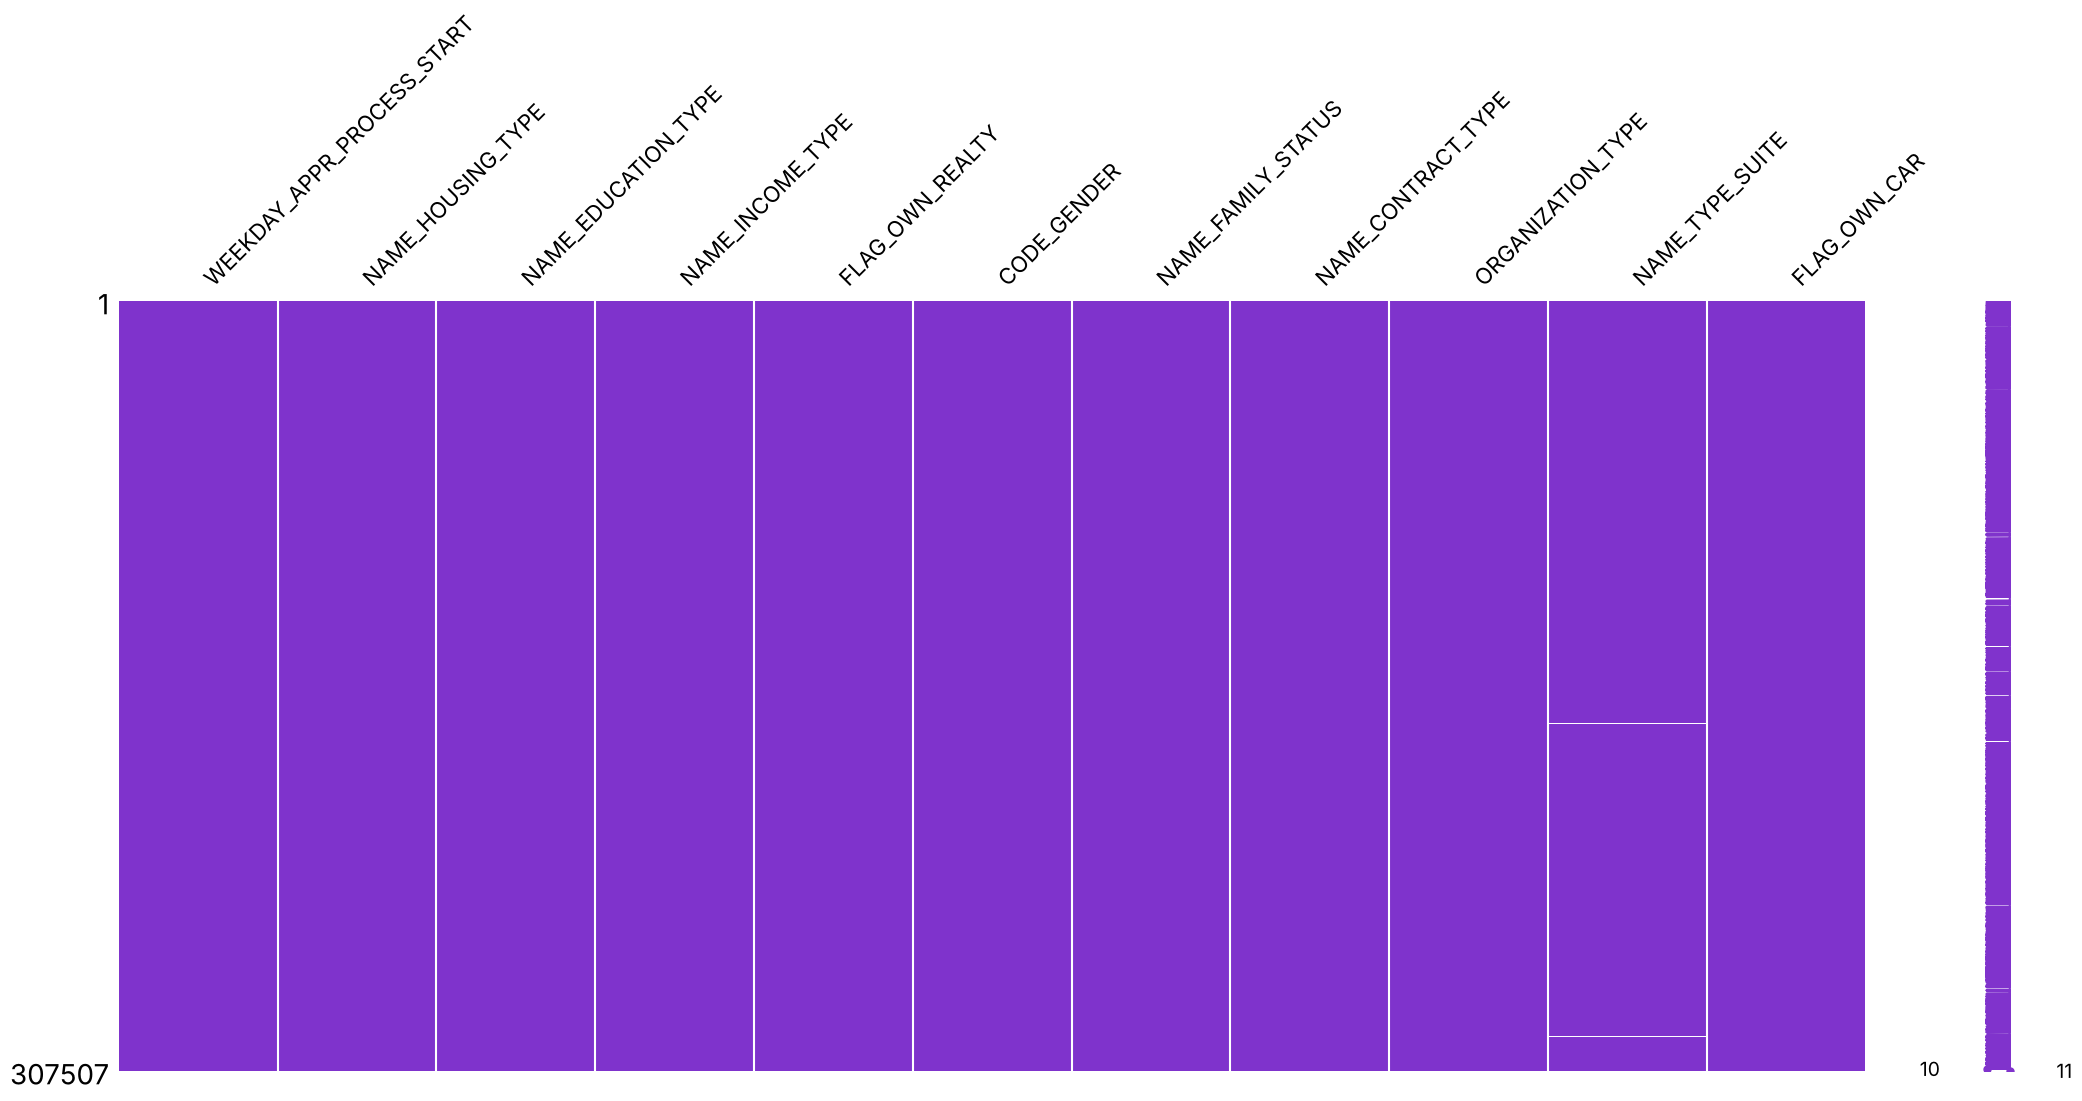

In [164]:
msno.matrix(df_train_converted[categorical_columns], color = (0.5, 0.2, 0.8))

Since we have generated the categorical variables, it is now time to make a good analysis of them and understand their distribution and presence. We would now replace the remaining NULL values and add the mode values so that we get the best results. 

In [165]:
categorical_data = df_train_converted[categorical_columns]

We are now going to perform the mode imputation for the features that still contain missing values. We would be doing that based on the object types. 

In [166]:
mode_imputation(categorical_data, inplace = True)

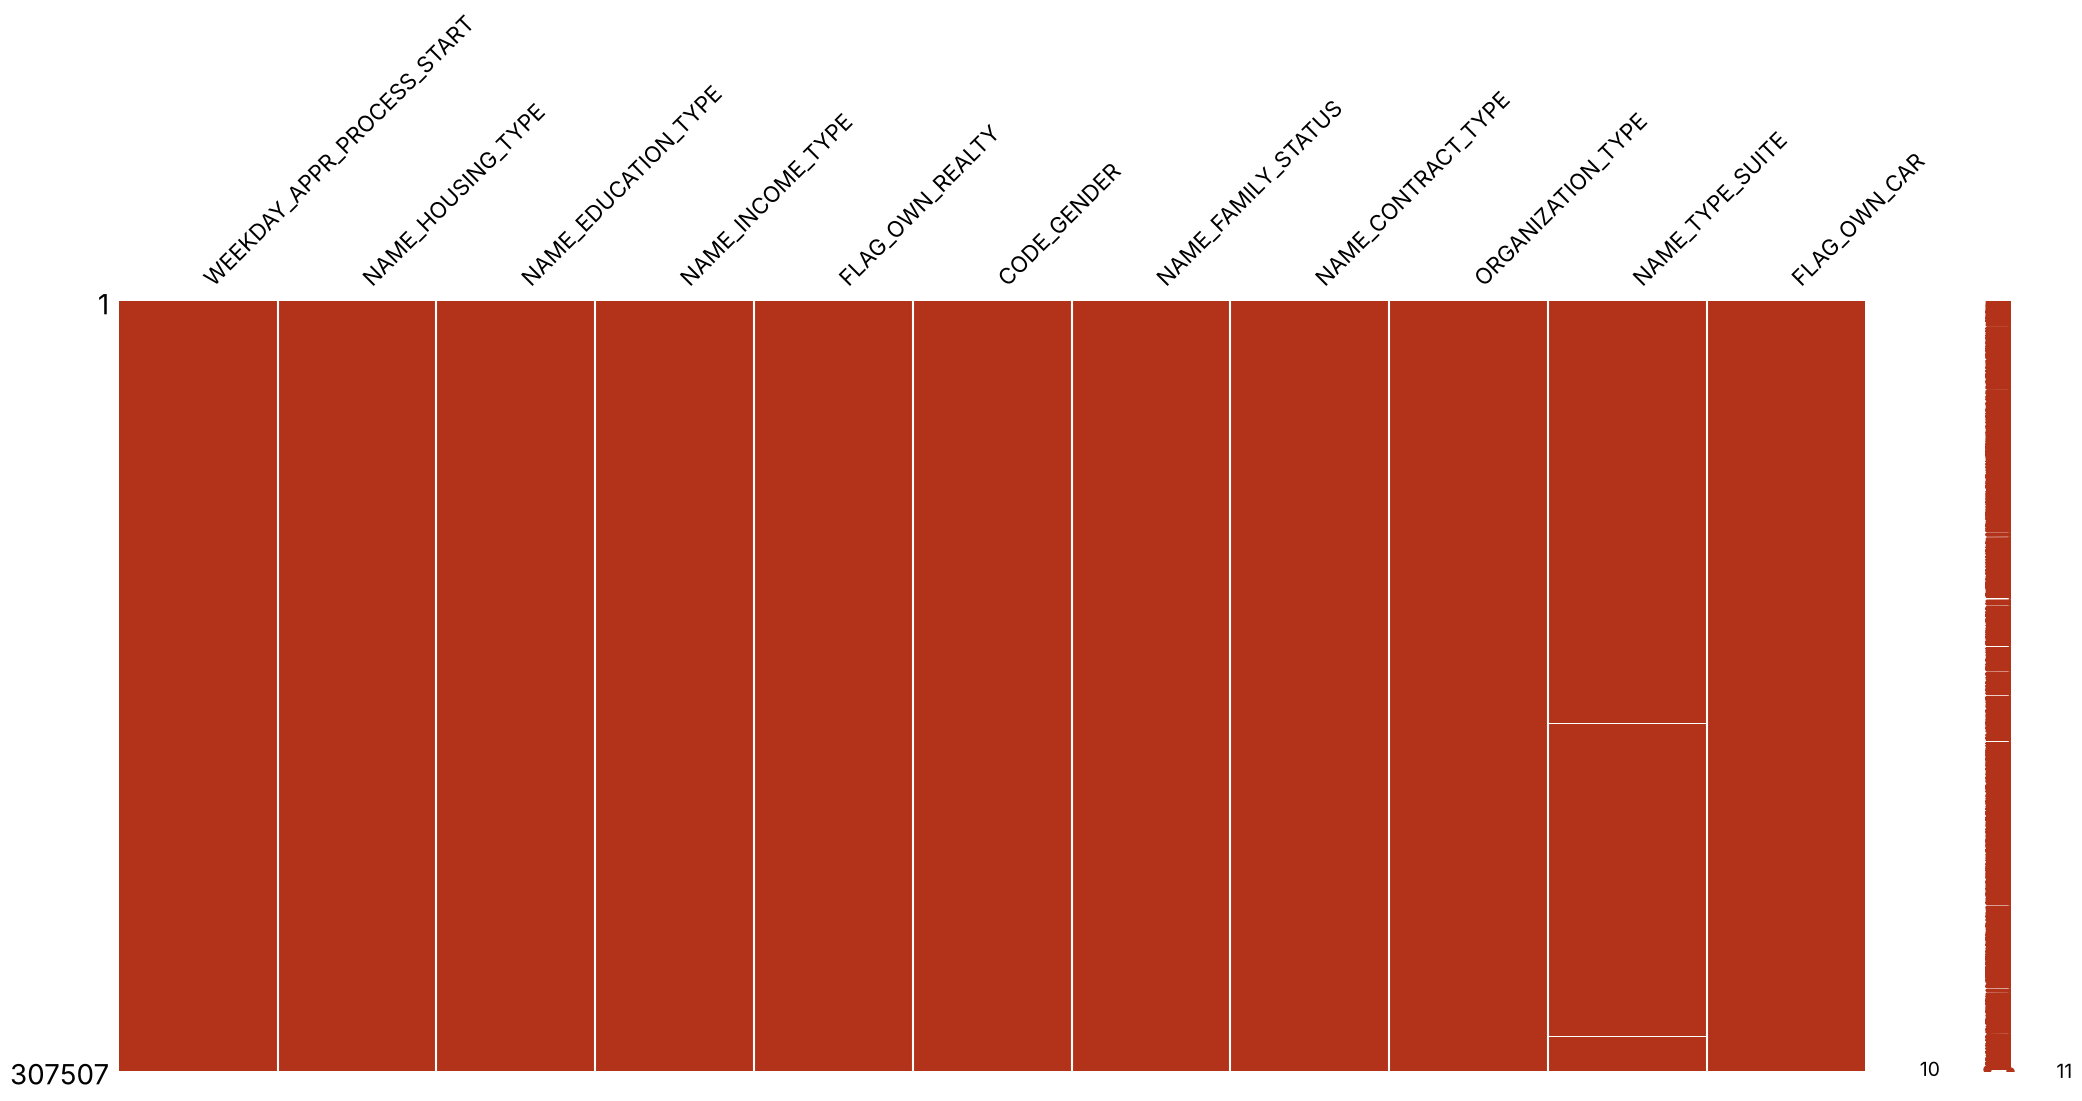

In [167]:
msno.matrix(categorical_data, color = (0.7, 0.2, 0.1))
plt.show()

Let us now consider the numeric columns and exclude the categorical ones so that we get a good idea of their distribution. 

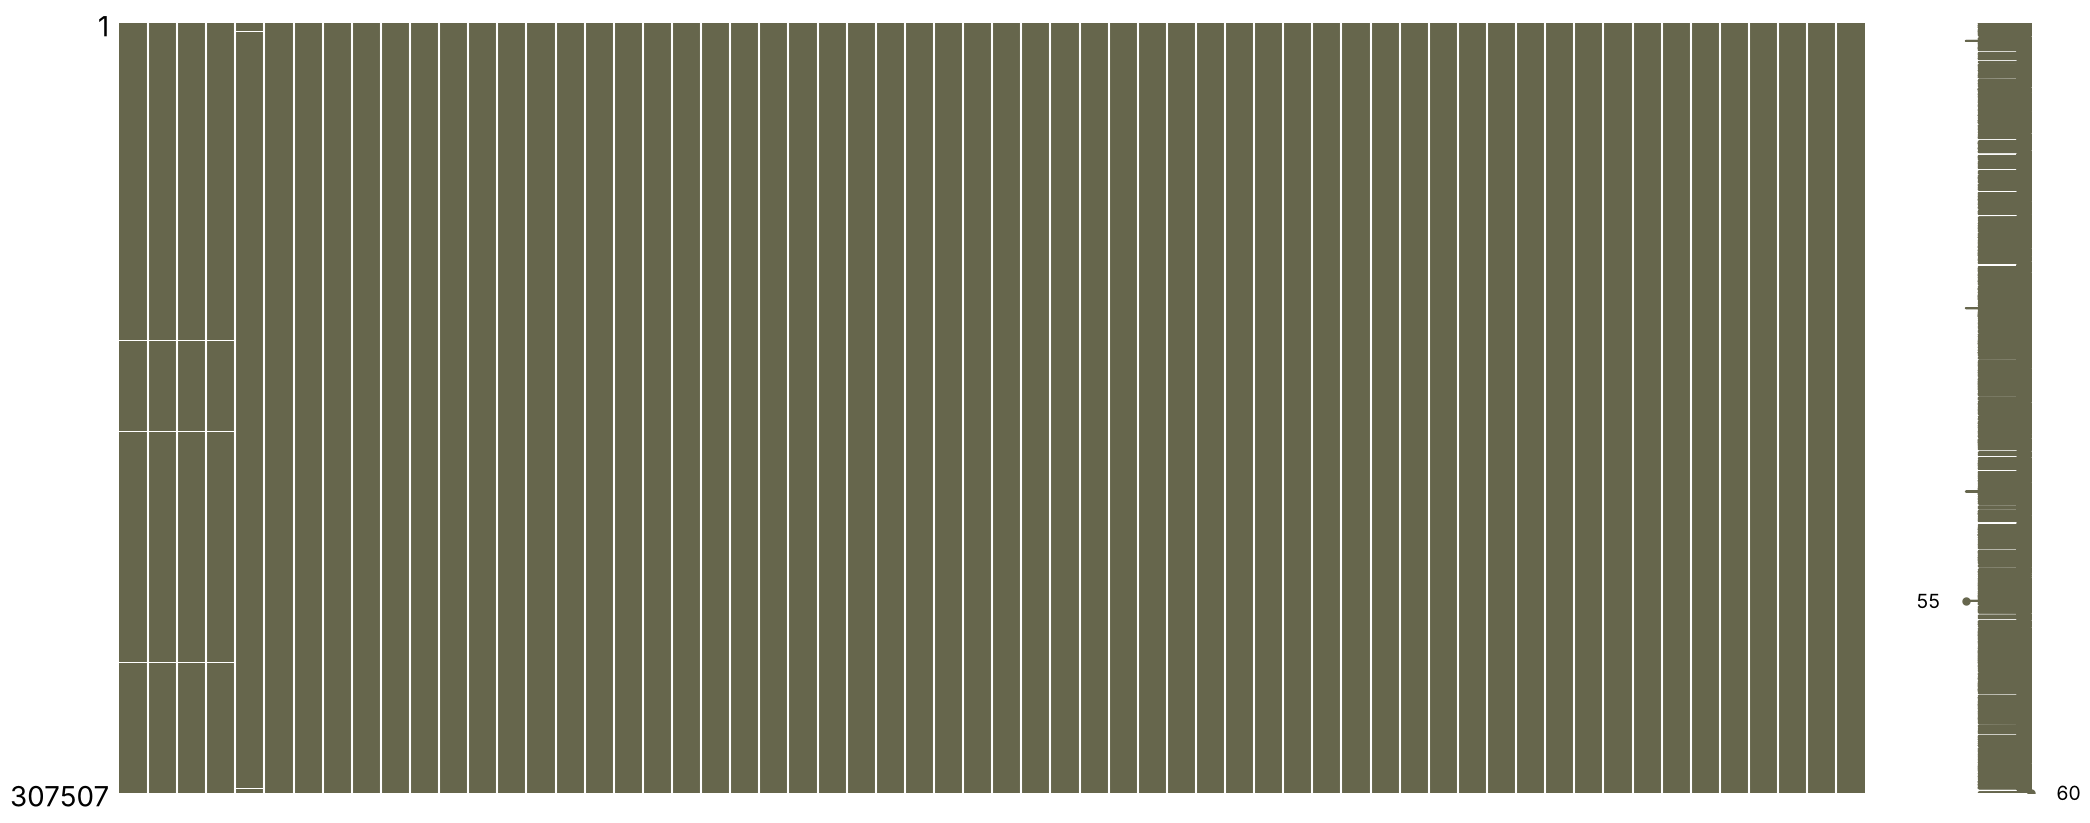

In [168]:
msno.matrix(numeric_data, color = (0.4, 0.4, 0.3))
plt.show()

In [169]:
numeric_data.head()

,DEF_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,CNT_CHILDREN,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,0,...,0,0,0,0,0,0,0,0,0,0
1,0.0,1.0,0.0,1.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,...,0,0,0,0,0,0,0,0,0,0
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,...,0,0,0,0,0,0,0,0,0,0
3,0.0,2.0,0.0,2.0,0.650442,297000.0,29686.5,2.0,-617.0,0,...,0,0,0,0,0,0,0,0,0,0
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,0,...,0,0,0,0,0,0,0,0,0,0


In [170]:
categorical_data.head()

,WEEKDAY_APPR_PROCESS_START,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,FLAG_OWN_CAR
0,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Business Entity Type 3,Unaccompanied,N
1,MONDAY,House / apartment,Higher education,State servant,N,F,Married,Cash loans,School,Family,N
2,MONDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Revolving loans,Government,Unaccompanied,Y
3,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,F,Civil marriage,Cash loans,Business Entity Type 3,Unaccompanied,N
4,THURSDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Religion,Unaccompanied,N


In [171]:
print(mode_imputation.__doc__)


This function would take the NULL values present in data and replace them with mode values of the given data respectively.



In [172]:
categorical_data['NAME_TYPE_SUITE'].unique()

array(['Unaccompanied', 'Family', 'Spouse, partner', 'Children',
       'Other_A', nan, 'Other_B', 'Group of people'], dtype=object)

In [173]:
categorical_data['NAME_TYPE_SUITE'].value_counts()

NAME_TYPE_SUITE
Unaccompanied      248523
Family              40148
Spouse, partner     11370
Children             3267
Other_B              1770
Other_A               866
Group of people       271
Name: count, dtype: int64

In [174]:
categorical_data['NAME_TYPE_SUITE'] = categorical_data['NAME_TYPE_SUITE'].fillna(value = 'Unaccompanied')  # [Colab fix] assign instead of chained inplace

In [175]:
categorical_data['NAME_TYPE_SUITE'].describe()

count            307507
unique                7
top       Unaccompanied
freq             249815
Name: NAME_TYPE_SUITE, dtype: object

In [176]:
any(categorical_data['NAME_TYPE_SUITE'].isnull())

False

In [177]:
np.random.uniform(0, 1)

0.6911174826193444

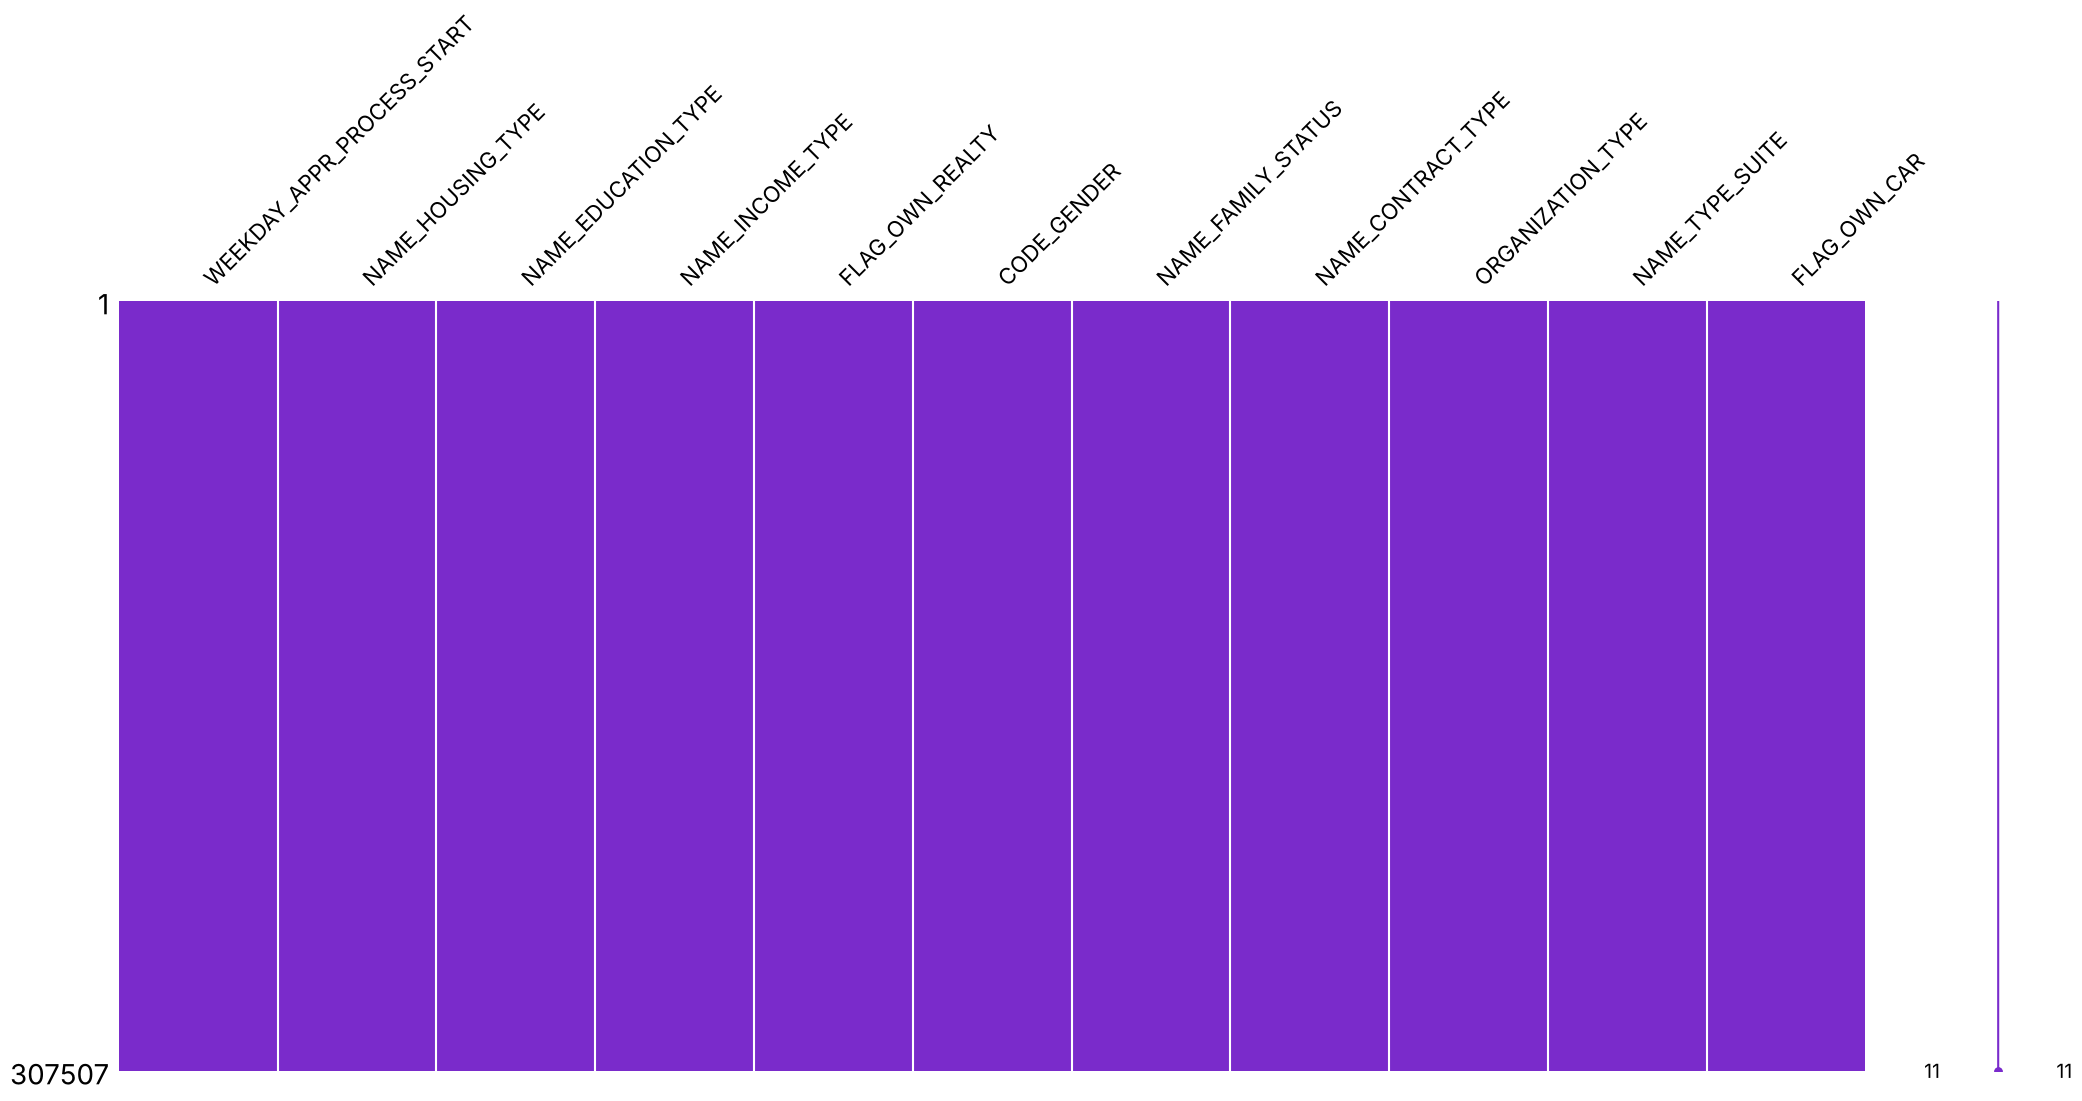

In [178]:
msno.matrix(categorical_data, color = (np.random.uniform(0, 1), np.random.uniform(0, 1), np.random.uniform(0, 1)))
plt.show()

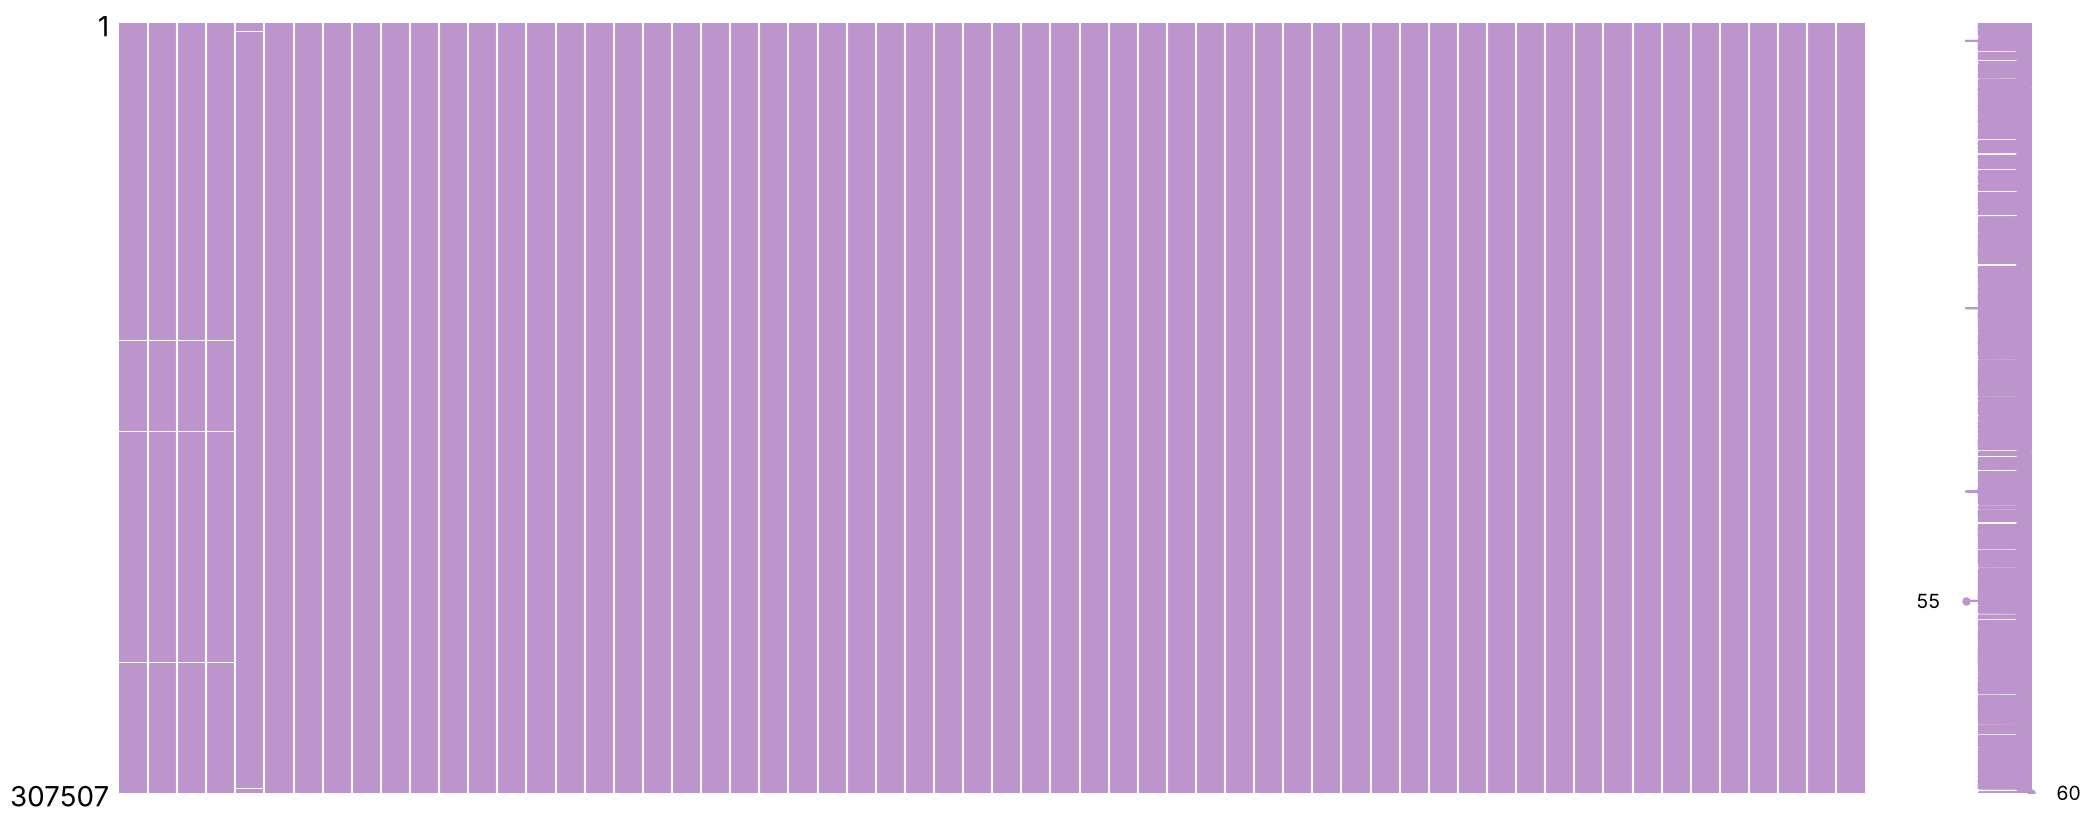

In [179]:
msno.matrix(numeric_data, color = (np.random.uniform(0, 1), np.random.uniform(0, 1), np.random.uniform(0, 1)))
plt.show()

In [180]:
mean_imputation(numeric_data, inplace = True)

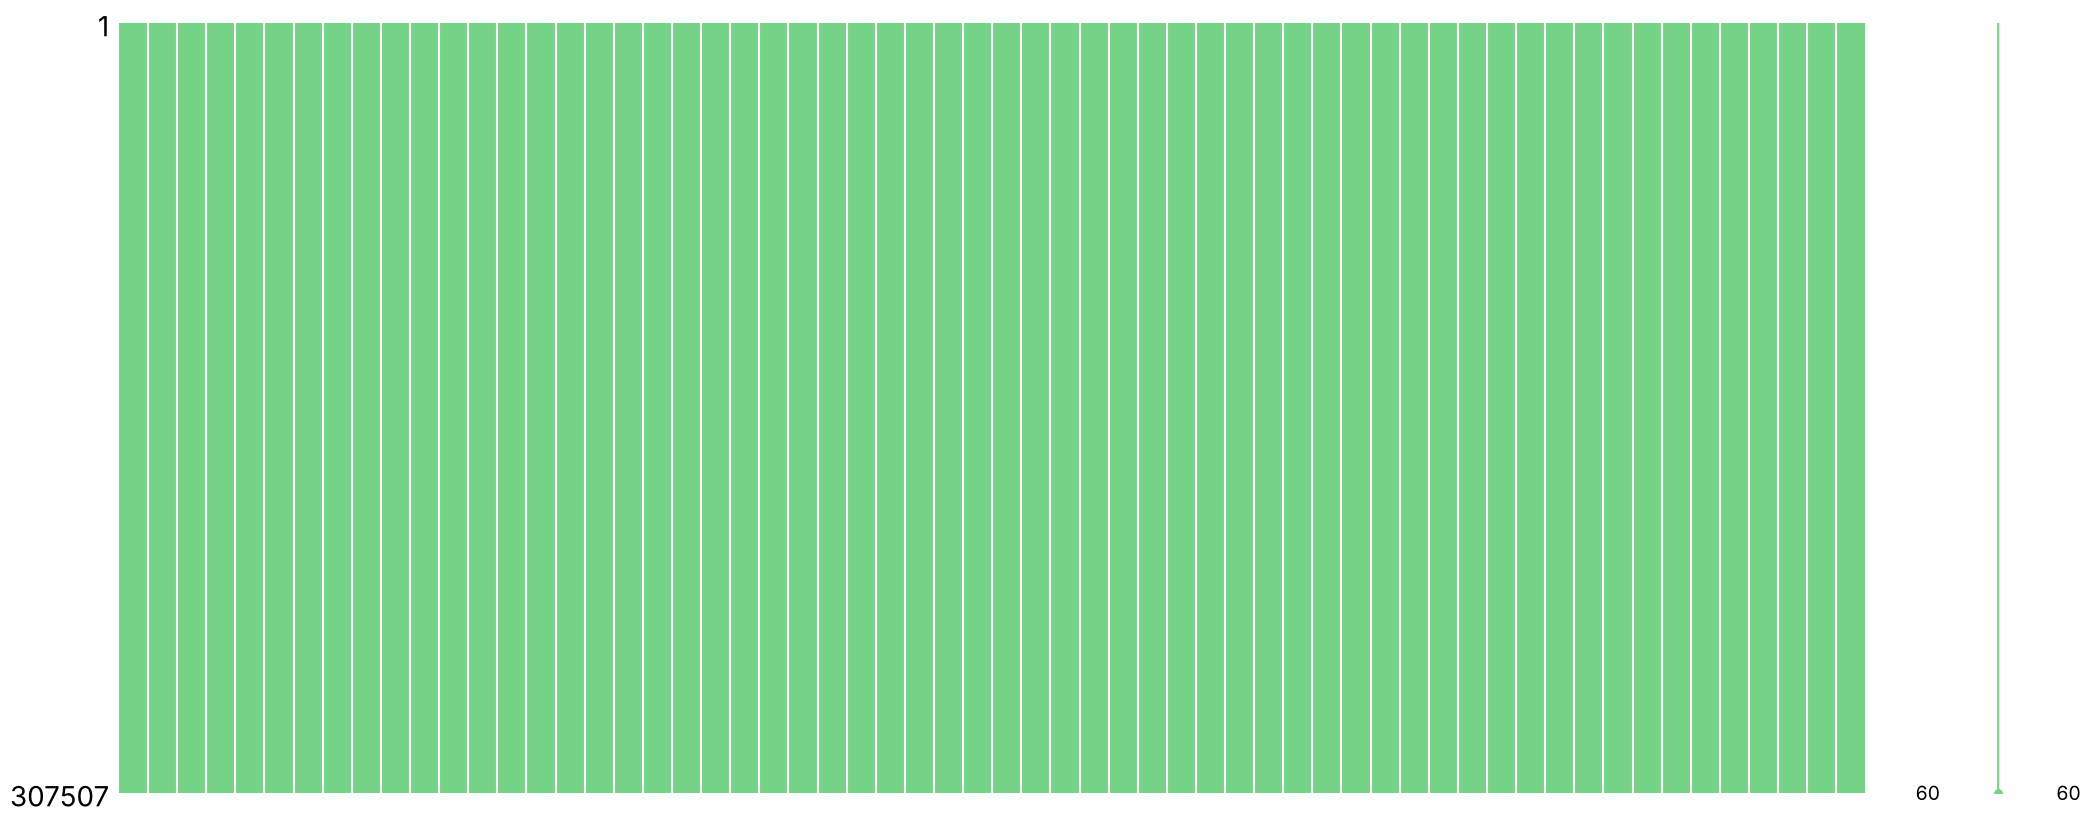

In [181]:
msno.matrix(numeric_data, color = (np.random.uniform(0, 1), np.random.uniform(0, 1), np.random.uniform(0, 1)))
plt.show()

In [182]:
any(numeric_data.isnull())

True

In [183]:
categorical_data.head()

,WEEKDAY_APPR_PROCESS_START,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,FLAG_OWN_CAR
0,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Business Entity Type 3,Unaccompanied,N
1,MONDAY,House / apartment,Higher education,State servant,N,F,Married,Cash loans,School,Family,N
2,MONDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Revolving loans,Government,Unaccompanied,Y
3,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,F,Civil marriage,Cash loans,Business Entity Type 3,Unaccompanied,N
4,THURSDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Religion,Unaccompanied,N


In [184]:
numeric_data.head()

,DEF_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,CNT_CHILDREN,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,0,...,0,0,0,0,0,0,0,0,0,0
1,0.0,1.0,0.0,1.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,...,0,0,0,0,0,0,0,0,0,0
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,...,0,0,0,0,0,0,0,0,0,0
3,0.0,2.0,0.0,2.0,0.650442,297000.0,29686.5,2.0,-617.0,0,...,0,0,0,0,0,0,0,0,0,0
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,0,...,0,0,0,0,0,0,0,0,0,0


In [185]:
numeric_data.columns

Index(['DEF_60_CNT_SOCIAL_CIRCLE', 'OBS_30_CNT_SOCIAL_CIRCLE',
       'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'EXT_SOURCE_2',
       'AMT_GOODS_PRICE', 'AMT_ANNUITY', 'CNT_FAM_MEMBERS',
       'DAYS_LAST_PHONE_CHANGE', 'CNT_CHILDREN', 'TARGET', 'SK_ID_CURR',
       'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'REGION_POPULATION_RELATIVE',
       'REGION_RATING_CLIENT_W_CITY', 'REG_REGION_NOT_LIVE_REGION',
       'HOUR_APPR_PROCESS_START', 'FLAG_MOBIL', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
       'FLAG_CONT_MOBILE', 'FLAG_WORK_PHONE', 'FLAG_EMAIL', 'FLAG_PHONE',
       'REGION_RATING_CLIENT', 'FLAG_EMP_PHONE', 'DAYS_REGISTRATION',
       'DAYS_ID_PUBLISH', 'FLOORSMAX_MEDI', 'YEARS_BEGINEXPLUATATION_MEDI',
       'FLOORSMAX_MODE', 'YEARS_BEGINEXPLUATATION_MODE',
       'YEARS_BEGINEXPLUATATION_AVG', 'FLOORSMAX_AVG',
       'LIVE_CITY_NOT_WORK_CITY', 'REG_REGION_NOT_WORK_REGION',
       'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_WORK_CITY',
       'REG_CITY_NOT_LIVE_CITY', 'FLAG_DOCUMENT

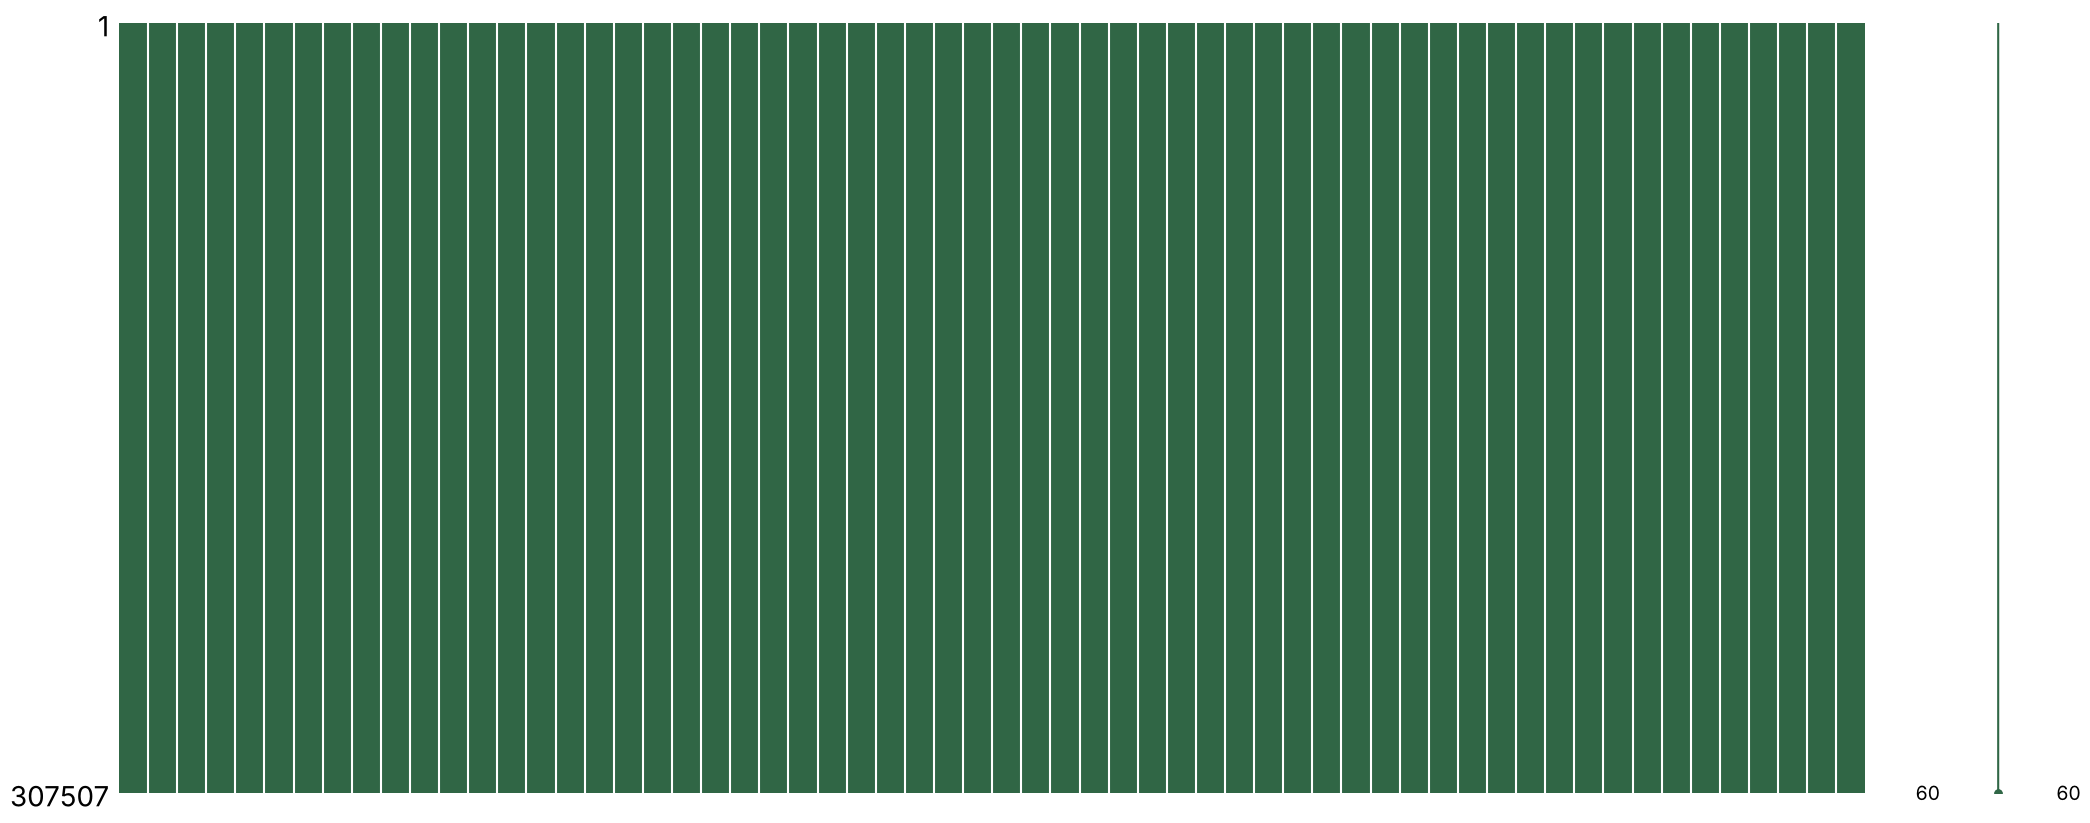

In [186]:
msno.matrix(numeric_data, color = (np.random.uniform(0, 1), np.random.uniform(0, 1), np.random.uniform(0, 1)))
plt.show()

In [187]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [188]:
numeric_data.head()

,DEF_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,CNT_CHILDREN,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,0,...,0,0,0,0,0,0,0,0,0,0
1,0.0,1.0,0.0,1.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,...,0,0,0,0,0,0,0,0,0,0
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,...,0,0,0,0,0,0,0,0,0,0
3,0.0,2.0,0.0,2.0,0.650442,297000.0,29686.5,2.0,-617.0,0,...,0,0,0,0,0,0,0,0,0,0
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,0,...,0,0,0,0,0,0,0,0,0,0


In [189]:
df_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [190]:
numeric_data.head()

,DEF_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,CNT_CHILDREN,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,0,...,0,0,0,0,0,0,0,0,0,0
1,0.0,1.0,0.0,1.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,...,0,0,0,0,0,0,0,0,0,0
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,...,0,0,0,0,0,0,0,0,0,0
3,0.0,2.0,0.0,2.0,0.650442,297000.0,29686.5,2.0,-617.0,0,...,0,0,0,0,0,0,0,0,0,0
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,0,...,0,0,0,0,0,0,0,0,0,0


In [191]:
# !pip install imblearn   (already installed by the setup cell at the top)

In [192]:
import imblearn
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import TomekLinks
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import NearMiss
# from sklearn.metrics import plot_confusion_matrix   # [Colab fix] removed from sklearn; shim defined in the setup cell

In [193]:
def sampler_function(data_x, data_y, sampler = 0, random_state = 101):
    
    if sampler == 0:
        sampler = RandomOverSampler(random_state = random_state)
    elif sampler == 1:
        sampler = TomekLinks()
    elif sampler == 2:
        sampler = SMOTE()
    else:
        sampler = NearMiss()
    X_transformed, y_transformed = sampler.fit_resample(data_x, data_y)
    
    print('Original dataset shape:', data_y.shape)
    print('Resample dataset shape:', y_transformed.shape)
    
    return X_transformed, y_transformed

In [194]:
numeric_data_with_target_dropped = numeric_data.drop('TARGET', axis = 1)

In [195]:
X = numeric_data_with_target_dropped
y = df_train['TARGET'].values

In [196]:
X_train, X_cv, y_train, y_cv = train_test_split(X, y, test_size = 0.3, random_state = 101)

In [197]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train_standardized = scaler.transform(X_train)
X_cv_standardized = scaler.transform(X_cv)

In [198]:
X_train, y_train = sampler_function(X_train_standardized, y_train, sampler = 0)

Original dataset shape: (215254,)
Resample dataset shape: (395864,)


In [199]:
X_cv, y_cv = sampler_function(X_cv_standardized, y_cv, sampler = 0)

Original dataset shape: (92253,)
Resample dataset shape: (169500,)


In [200]:
from sklearn.linear_model import LogisticRegression

In [201]:
model = LogisticRegression()
model.fit(X_train, y_train)
y_predictions = model.predict(X_cv)

In [202]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [203]:
from sklearn.metrics import accuracy_score

In [204]:
mean_absolute_error(y_predictions, y_cv)

0.35546312684365783

In [205]:
accuracy_score(y_predictions, y_cv)

0.6445368731563422

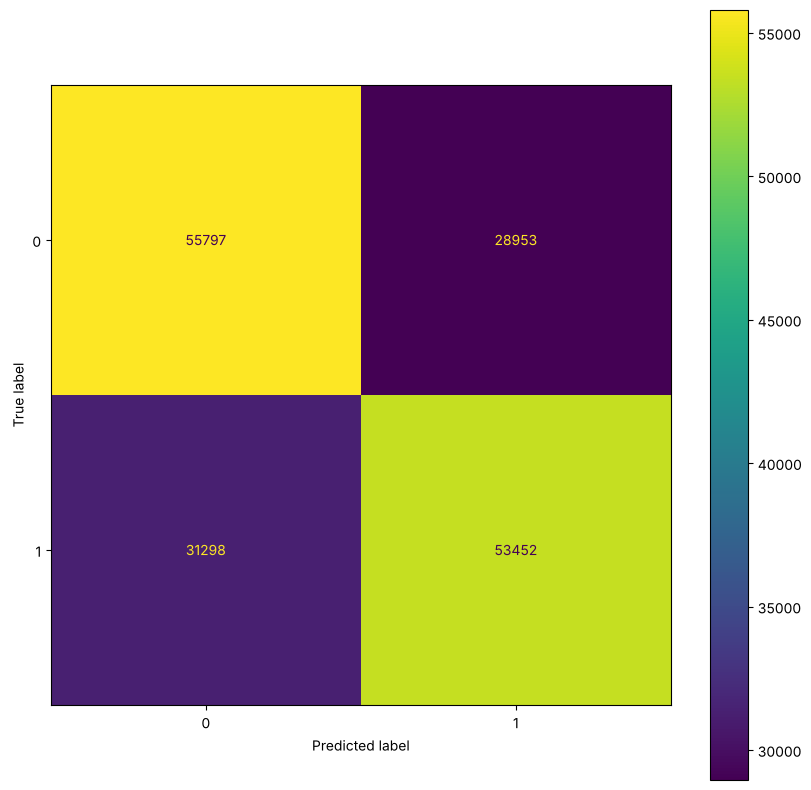

In [206]:
# https://stackoverflow.com/questions/61325314/how-to-change-plot-confusion-matrix-default-figure-size-in-sklearn-metrics-packa
# Credits to this blog for helping me in changing the size of the plot_confusion_matrix function from sklearn.metrics 
fig, ax = plt.subplots(figsize = (10, 10))
plot_confusion_matrix(model, X_cv, y_cv, ax = ax)
plt.show()

AUC for our classifier is: 0.6985063960111728


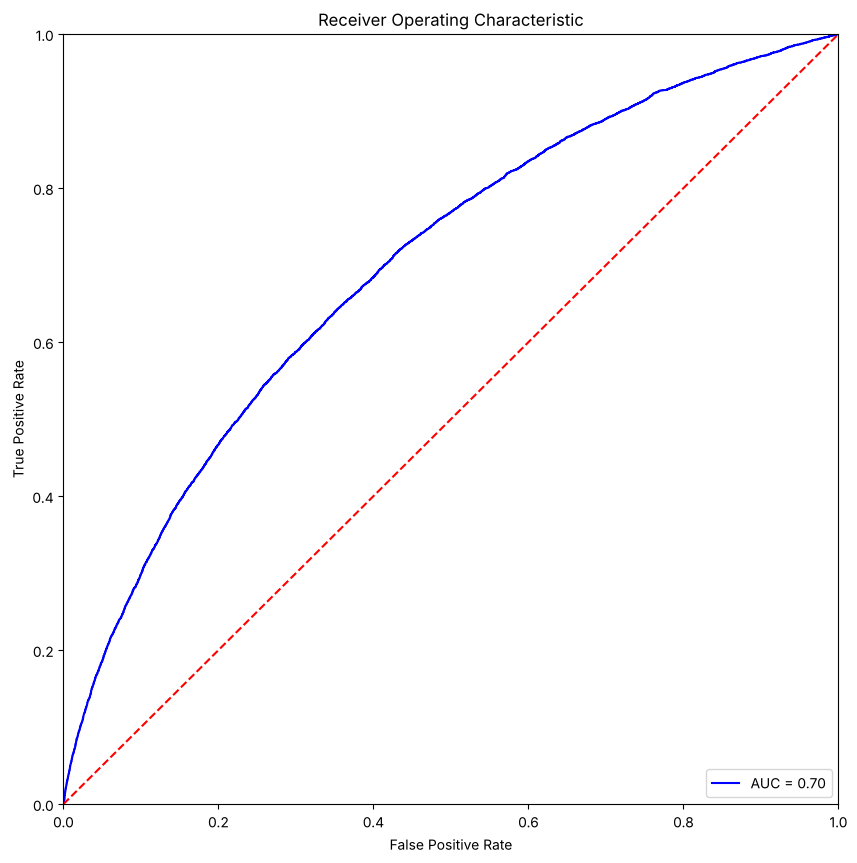

In [207]:
## https://medium.com/analytics-vidhya/evaluation-metrics-for-classification-problems-with-implementation-in-python-a20193b4f2c3
## Credits to this website for providing such an useful and clear explanation of the topic along with the code.

from sklearn.metrics import roc_curve, auc

class_probabilities = model.predict_proba(X_cv)
preds = class_probabilities[:, 1]

fpr, tpr, threshold = roc_curve(y_cv, preds)
roc_auc = auc(fpr, tpr)

# Printing AUC
print(f"AUC for our classifier is: {roc_auc}")

# Plotting the ROC
plt.figure(figsize = (10, 10))
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

## Naive Bayes Classifier

In [208]:
from sklearn.naive_bayes import GaussianNB

In [209]:
model = GaussianNB()
model.fit(X_train, y_train)
y_predictions = model.predict(X_cv)

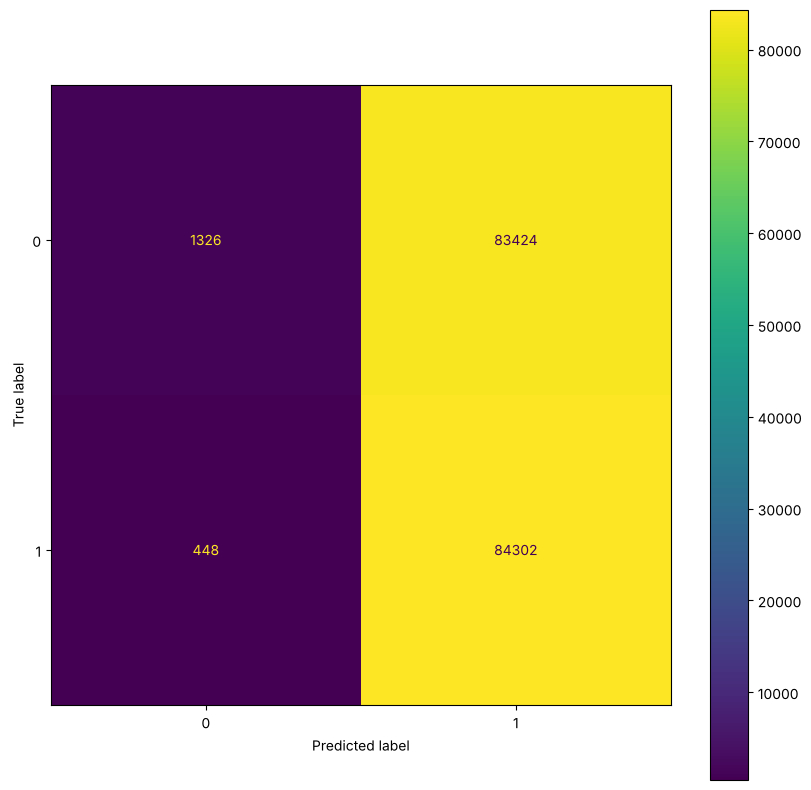

In [210]:
fig, ax = plt.subplots(figsize = (10, 10))
plot_confusion_matrix(model, X_cv, y_cv, ax = ax)
plt.show()

AUC for our classifier is: 0.6442324416947295


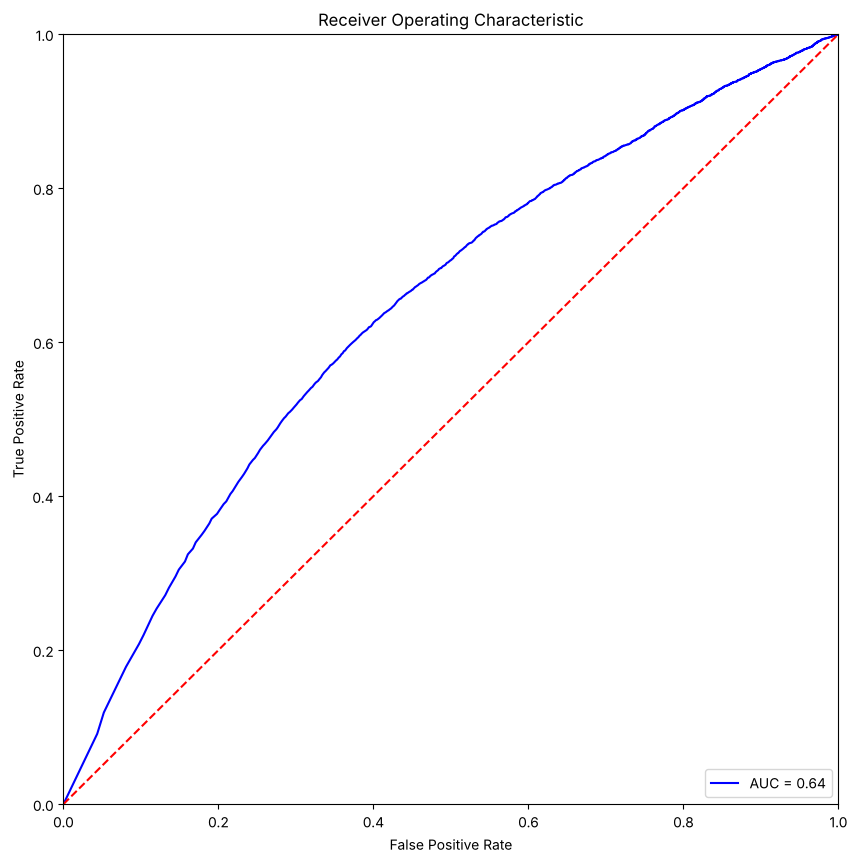

In [211]:
## https://medium.com/analytics-vidhya/evaluation-metrics-for-classification-problems-with-implementation-in-python-a20193b4f2c3
## Credits to this website for providing such an useful and clear explanation of the topic along with the code.

class_probabilities = model.predict_proba(X_cv)
preds = class_probabilities[:, 1]

fpr, tpr, threshold = roc_curve(y_cv, preds)
roc_auc = auc(fpr, tpr)

# Printing AUC
print(f"AUC for our classifier is: {roc_auc}")

# Plotting the ROC
plt.figure(figsize = (10, 10))
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

## Decision Tree Classifier

In [212]:
from sklearn.tree import DecisionTreeClassifier

In [213]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)
y_predictions = model.predict(X_cv)

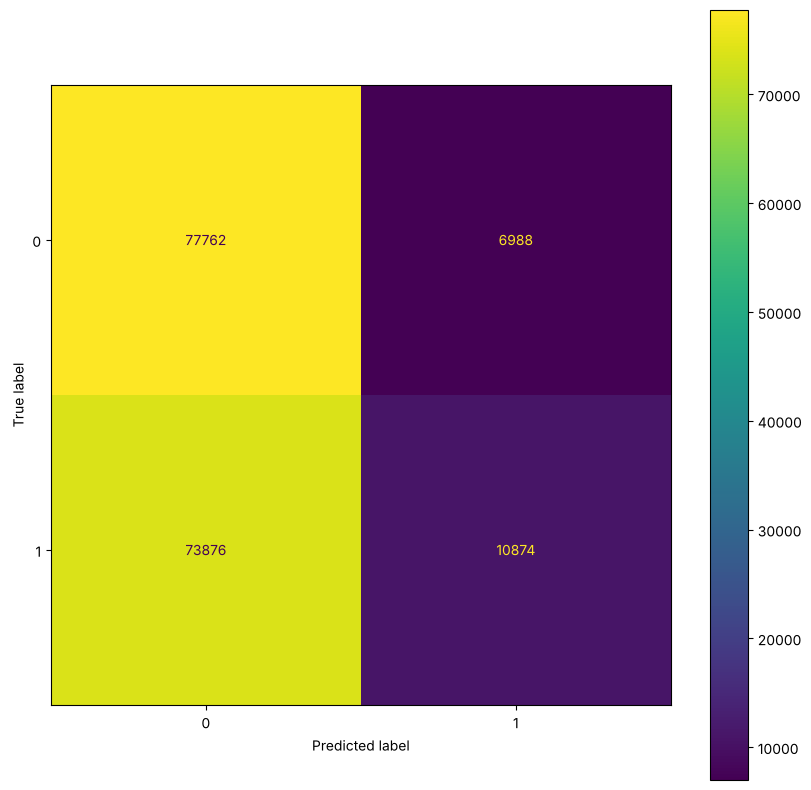

In [214]:
fig, ax = plt.subplots(figsize = (10, 10))
plot_confusion_matrix(model, X_cv, y_cv, ax = ax)
plt.show()

In [215]:
from sklearn.metrics import classification_report

In [216]:
print(classification_report(y_predictions, y_cv))

              precision    recall  f1-score   support

           0       0.92      0.51      0.66    151638
           1       0.13      0.61      0.21     17862

    accuracy                           0.52    169500
   macro avg       0.52      0.56      0.43    169500
weighted avg       0.83      0.52      0.61    169500



In [217]:
from sklearn.ensemble import RandomForestClassifier

AUC for our classifier is: 0.5229262536873156


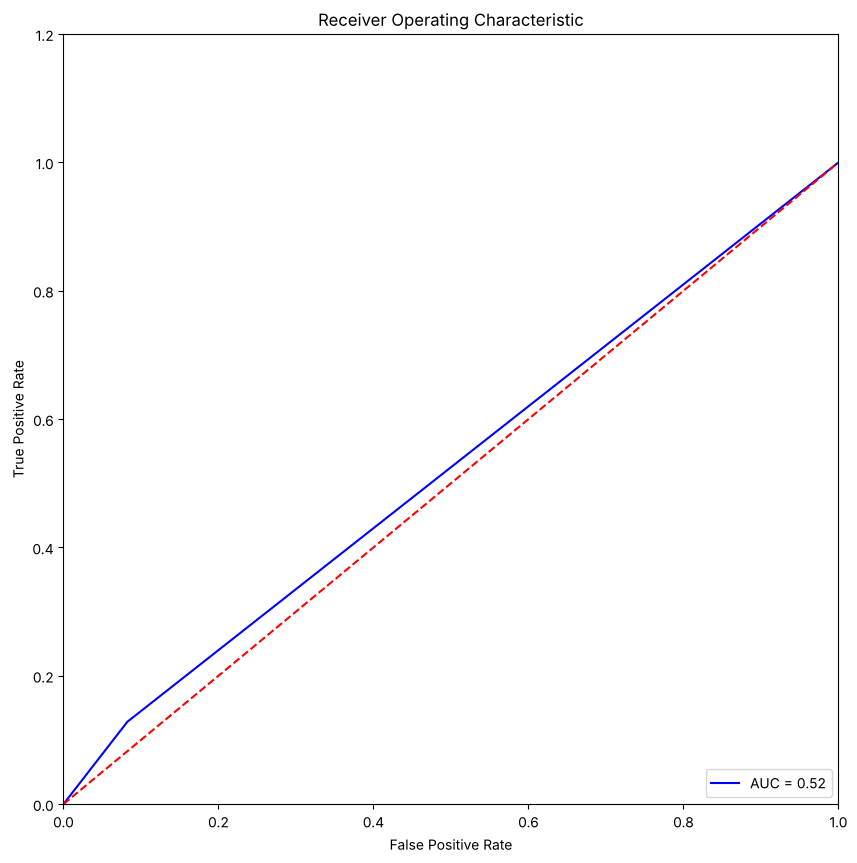

In [218]:
## https://medium.com/analytics-vidhya/evaluation-metrics-for-classification-problems-with-implementation-in-python-a20193b4f2c3
## Credits to this website for providing such an useful and clear explanation of the topic along with the code.

class_probabilities = model.predict_proba(X_cv)
preds = class_probabilities[:, 1]

fpr, tpr, threshold = roc_curve(y_cv, preds)
roc_auc = auc(fpr, tpr)

# Printing AUC
print(f"AUC for our classifier is: {roc_auc}")

# Plotting the ROC
plt.figure(figsize = (10, 10))
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1.2])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

## Random Forest Classifier

In [219]:
model = RandomForestClassifier(n_jobs = -1)
model.fit(X_train, y_train)
y_predictions = model.predict(X_cv)

In [220]:
print(classification_report(y_predictions, y_cv))

              precision    recall  f1-score   support

           0       1.00      0.50      0.67    168606
           1       0.01      0.89      0.02       894

    accuracy                           0.50    169500
   macro avg       0.50      0.70      0.34    169500
weighted avg       0.99      0.50      0.66    169500



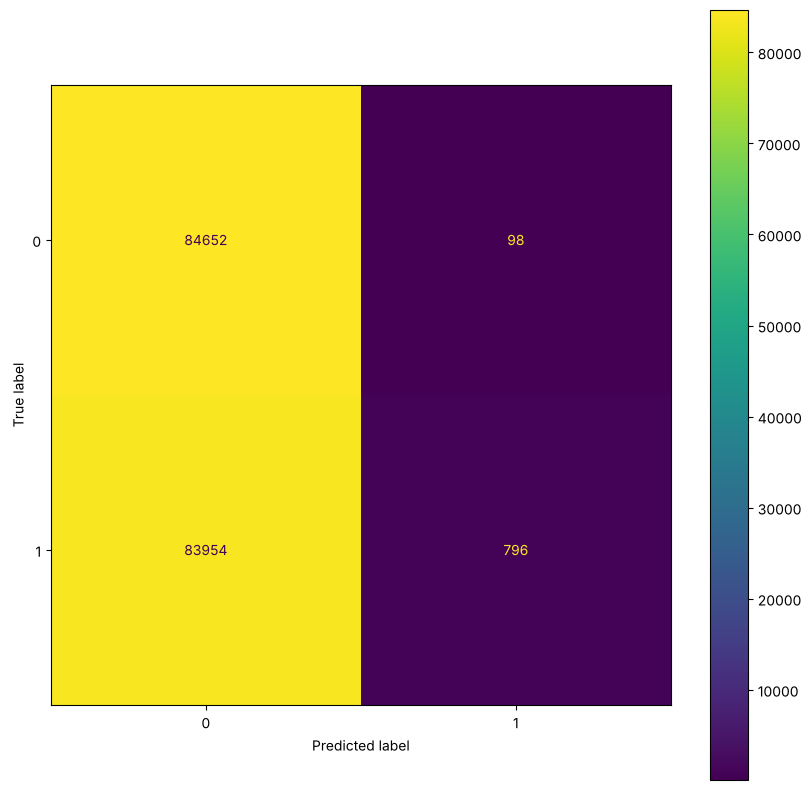

In [221]:
fig, ax = plt.subplots(figsize = (10, 10))
plot_confusion_matrix(model, X_cv, y_cv, ax = ax)
plt.show()

AUC for our classifier is: 0.6834329100512526


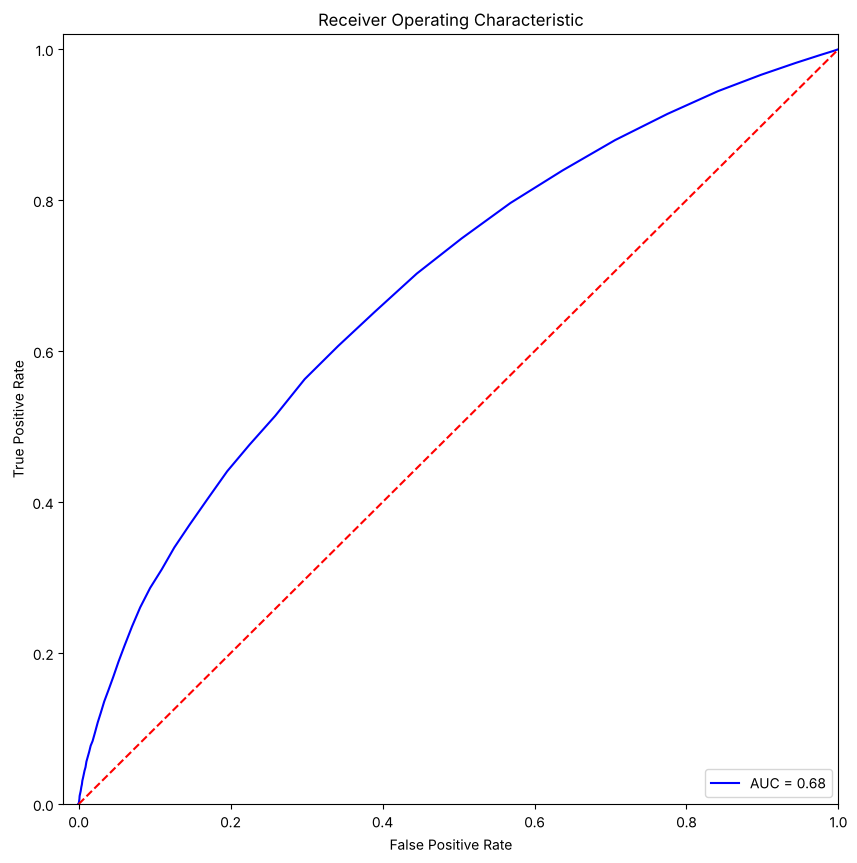

In [222]:
## https://medium.com/analytics-vidhya/evaluation-metrics-for-classification-problems-with-implementation-in-python-a20193b4f2c3
## Credits to this website for providing such an useful and clear explanation of the topic along with the code.

class_probabilities = model.predict_proba(X_cv)
preds = class_probabilities[:, 1]

fpr, tpr, threshold = roc_curve(y_cv, preds)
roc_auc = auc(fpr, tpr)

# Printing AUC
print(f"AUC for our classifier is: {roc_auc}")

# Plotting the ROC
plt.figure(figsize = (10, 10))
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([-0.02, 1])
plt.ylim([0, 1.02])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [223]:
X = numeric_data_with_target_dropped
y = df_train['TARGET'].values

X_train, X_cv, y_train, y_cv = train_test_split(X, y, test_size = 0.3, random_state = 101)

scaler = StandardScaler()
scaler.fit(X_train)
X_train_standardized = scaler.transform(X_train)
X_cv_standardized = scaler.transform(X_cv)


X_train, y_train = sampler_function(X_train_standardized, y_train, sampler = 2)
X_cv, y_cv = sampler_function(X_cv_standardized, y_cv, sampler = 2)

Original dataset shape: (215254,)
Resample dataset shape: (395864,)


Original dataset shape: (92253,)
Resample dataset shape: (169500,)


In [224]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)
y_predictions = model.predict(X_cv)

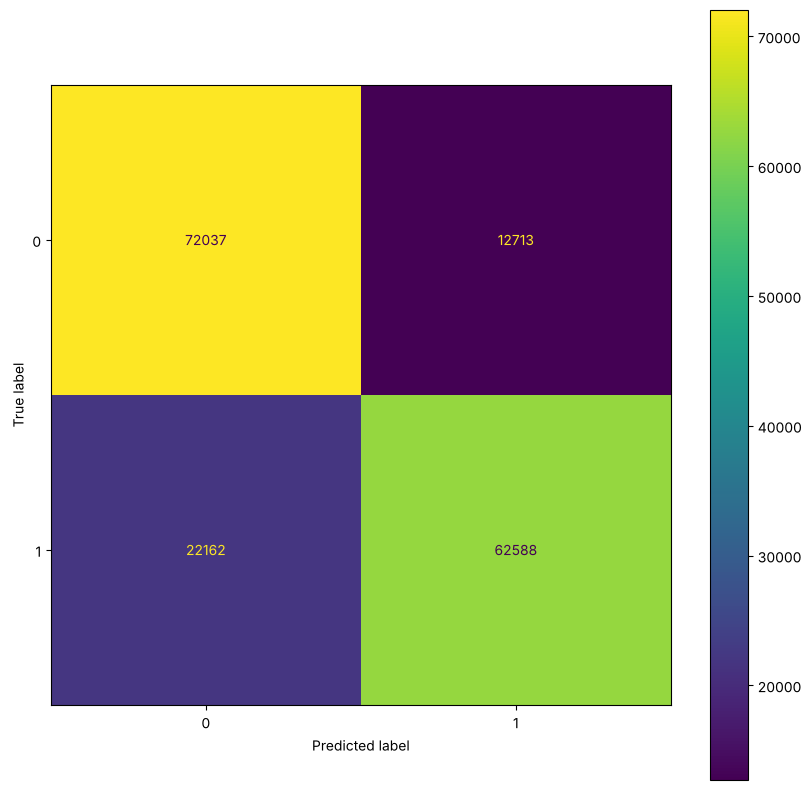

In [225]:
fig, ax = plt.subplots(figsize = (10, 10))
plot_confusion_matrix(model, X_cv, y_cv, ax = ax)
plt.show()

In [226]:
print(classification_report(y_predictions, y_cv))

              precision    recall  f1-score   support

           0       0.85      0.76      0.81     94199
           1       0.74      0.83      0.78     75301

    accuracy                           0.79    169500
   macro avg       0.79      0.80      0.79    169500
weighted avg       0.80      0.79      0.79    169500



AUC for our classifier is: 0.7942477876106195


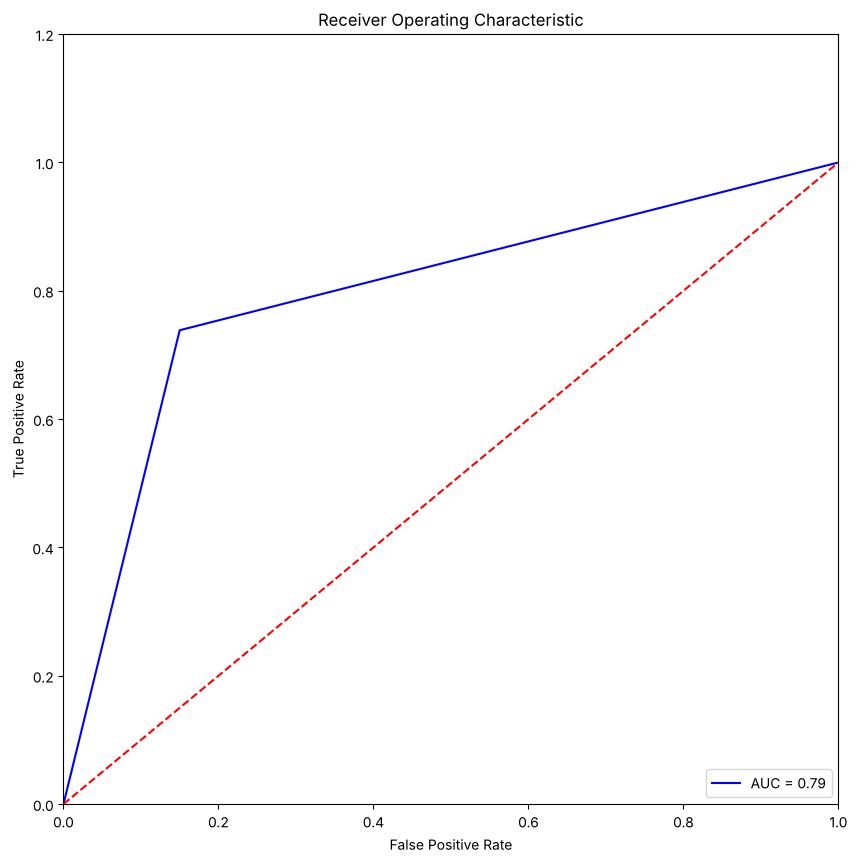

In [227]:
## https://medium.com/analytics-vidhya/evaluation-metrics-for-classification-problems-with-implementation-in-python-a20193b4f2c3
## Credits to this website for providing such an useful and clear explanation of the topic along with the code.

class_probabilities = model.predict_proba(X_cv)
preds = class_probabilities[:, 1]

fpr, tpr, threshold = roc_curve(y_cv, preds)
roc_auc = auc(fpr, tpr)

# Printing AUC
print(f"AUC for our classifier is: {roc_auc}")

# Plotting the ROC
plt.figure(figsize = (10, 10))
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1.2])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [228]:
model = RandomForestClassifier(n_jobs = -1)
model.fit(X_train, y_train)
y_predictions = model.predict(X_cv)

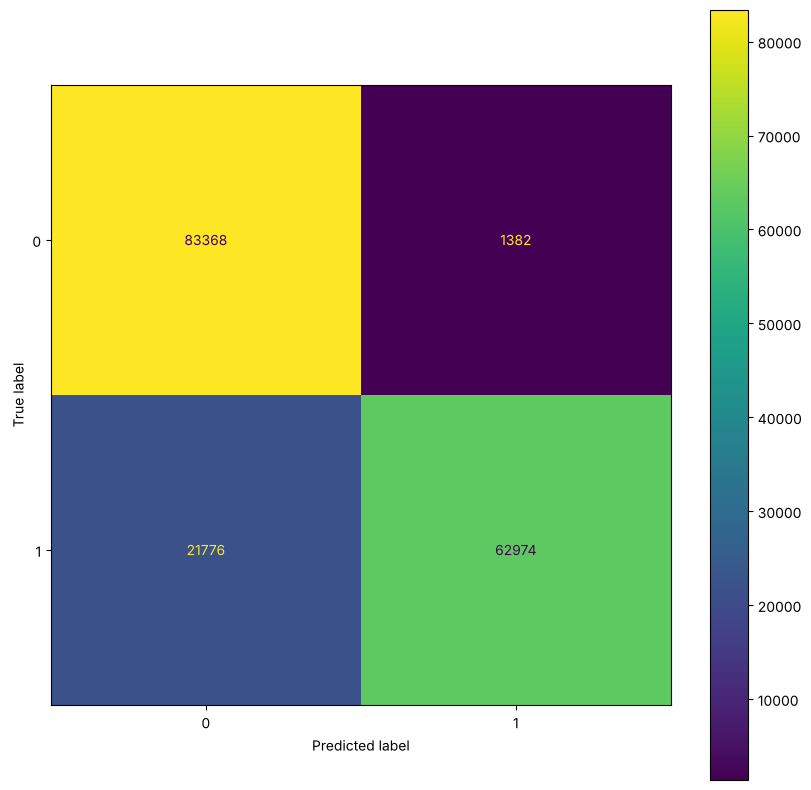

In [229]:
fig, ax = plt.subplots(figsize = (10, 10))
plot_confusion_matrix(model, X_cv, y_cv, ax = ax)
plt.show()

AUC for our classifier is: 0.9479764870128174


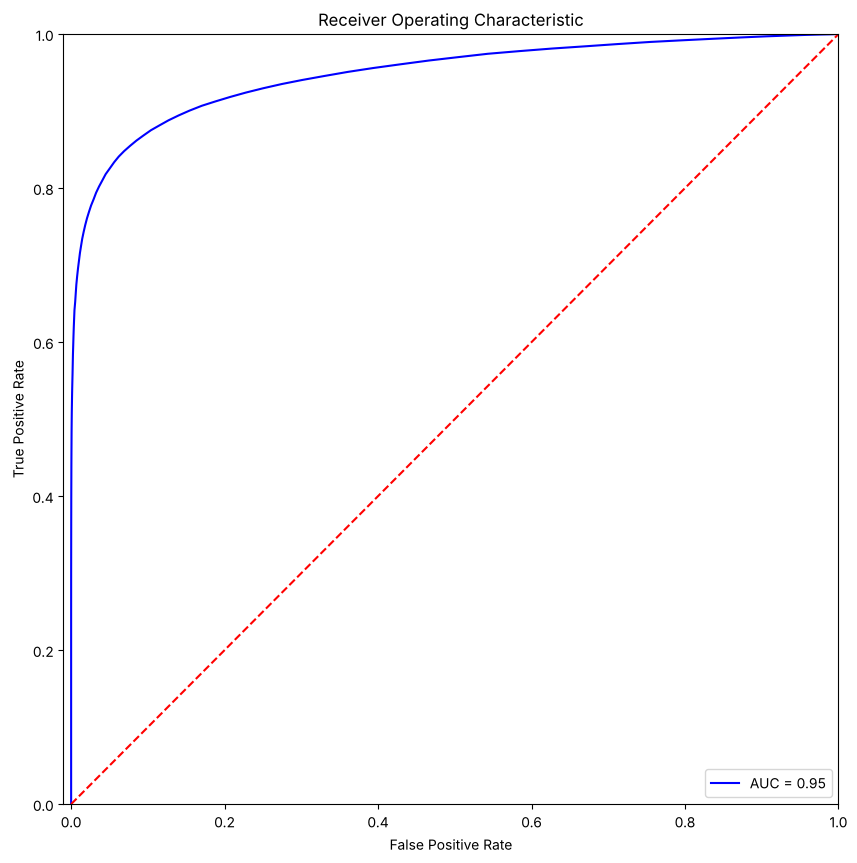

In [230]:
## https://medium.com/analytics-vidhya/evaluation-metrics-for-classification-problems-with-implementation-in-python-a20193b4f2c3
## Credits to this website for providing such an useful and clear explanation of the topic along with the code.

class_probabilities = model.predict_proba(X_cv)
preds = class_probabilities[:, 1]

fpr, tpr, threshold = roc_curve(y_cv, preds)
roc_auc = auc(fpr, tpr)

# Printing AUC
print(f"AUC for our classifier is: {roc_auc}")

# Plotting the ROC
plt.figure(figsize = (10, 10))
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([-0.01, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [231]:
print(classification_report(y_predictions, y_cv))

              precision    recall  f1-score   support

           0       0.98      0.79      0.88    105144
           1       0.74      0.98      0.84     64356

    accuracy                           0.86    169500
   macro avg       0.86      0.89      0.86    169500
weighted avg       0.89      0.86      0.87    169500



## Hyperparameter Tuning (Random Forest Model)

In [232]:
from sklearn.model_selection import GridSearchCV
from tqdm import tqdm

In [233]:
# This code cell can take about 10 minutes to run as we are performing hyperparameter tuning

# Define the parameter grid for tuning
param_grid = {'n_estimators': [10, 20]}

# Define the classifier used
model = RandomForestClassifier(n_jobs = -1)

# Create the grid search object
grid_search = GridSearchCV(estimator = model, param_grid = param_grid, cv = 3)

# Create a progress bar
pbar = tqdm(total=len(grid_search.param_grid['n_estimators']))

# Fit the grid search object to the training data
grid_search.fit(X_train, y_train)

# Update the progress bar
pbar.update(1)

# Close the progress bar
pbar.close()

# Get the best hyperparameters from the grid search
best_params = grid_search.best_params_

  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [01:09<01:09, 69.01s/it]

 50%|█████     | 1/2 [01:09<01:09, 69.01s/it]

In [234]:
print(best_params)

{'n_estimators': 20}


## Prediction with both categorical and numerical features

In [235]:
categorical_data.head()

,WEEKDAY_APPR_PROCESS_START,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,FLAG_OWN_CAR
0,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Business Entity Type 3,Unaccompanied,N
1,MONDAY,House / apartment,Higher education,State servant,N,F,Married,Cash loans,School,Family,N
2,MONDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Revolving loans,Government,Unaccompanied,Y
3,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,F,Civil marriage,Cash loans,Business Entity Type 3,Unaccompanied,N
4,THURSDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Religion,Unaccompanied,N


In [236]:
categorical_data.shape

(307507, 11)

In [237]:
categorical_data.info()

<class 'pandas.DataFrame'>
Index: 307507 entries, 0 to 307510
Data columns (total 11 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   WEEKDAY_APPR_PROCESS_START  307507 non-null  object
 1   NAME_HOUSING_TYPE           307507 non-null  object
 2   NAME_EDUCATION_TYPE         307507 non-null  object
 3   NAME_INCOME_TYPE            307507 non-null  object
 4   FLAG_OWN_REALTY             307507 non-null  object
 5   CODE_GENDER                 307507 non-null  object
 6   NAME_FAMILY_STATUS          307507 non-null  object
 7   NAME_CONTRACT_TYPE          307507 non-null  object
 8   ORGANIZATION_TYPE           307507 non-null  object
 9   NAME_TYPE_SUITE             307507 non-null  object
 10  FLAG_OWN_CAR                307507 non-null  object
dtypes: object(11)
memory usage: 28.2+ MB


In [238]:
from sklearn.preprocessing import OneHotEncoder

In [239]:
numeric_data.head()

,DEF_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,CNT_CHILDREN,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,0,...,0,0,0,0,0,0,0,0,0,0
1,0.0,1.0,0.0,1.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,...,0,0,0,0,0,0,0,0,0,0
2,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,...,0,0,0,0,0,0,0,0,0,0
3,0.0,2.0,0.0,2.0,0.650442,297000.0,29686.5,2.0,-617.0,0,...,0,0,0,0,0,0,0,0,0,0
4,0.0,0.0,0.0,0.0,0.322738,513000.0,21865.5,1.0,-1106.0,0,...,0,0,0,0,0,0,0,0,0,0


In [240]:
total_data = pd.concat([categorical_data, numeric_data], axis = 1)

In [241]:
total_data.head()

,WEEKDAY_APPR_PROCESS_START,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Business Entity Type 3,Unaccompanied,...,0,0,0,0,0,0,0,0,0,0
1,MONDAY,House / apartment,Higher education,State servant,N,F,Married,Cash loans,School,Family,...,0,0,0,0,0,0,0,0,0,0
2,MONDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Revolving loans,Government,Unaccompanied,...,0,0,0,0,0,0,0,0,0,0
3,WEDNESDAY,House / apartment,Secondary / secondary special,Working,Y,F,Civil marriage,Cash loans,Business Entity Type 3,Unaccompanied,...,0,0,0,0,0,0,0,0,0,0
4,THURSDAY,House / apartment,Secondary / secondary special,Working,Y,M,Single / not married,Cash loans,Religion,Unaccompanied,...,0,0,0,0,0,0,0,0,0,0


In [242]:
X_numeric = numeric_data.drop(['TARGET'], axis = 1)
y = numeric_data['TARGET']

X_categorical = categorical_data

In [243]:
X_train_numeric, X_cv_numeric, y_train, y_cv = train_test_split(X_numeric, y, test_size = 0.3, random_state = 101)
X_train_categorical, X_cv_categorical, y_train, y_cv = train_test_split(X_categorical, y, test_size = 0.3, random_state = 101)

In [244]:
X_train_numeric.head()

,DEF_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,CNT_CHILDREN,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
91135,0.0,0.0,0.0,0.0,0.628767,270000.0,13500.0,4.0,-405.0,2,...,0,0,0,0,0,0,0,0,0,0
113628,0.0,0.0,0.0,0.0,0.362218,238500.0,11767.5,2.0,-4.0,0,...,0,0,0,0,0,1,0,0,0,0
200241,0.0,0.0,0.0,0.0,0.766267,229500.0,26019.0,2.0,-2766.0,0,...,0,0,0,0,0,0,0,0,0,0
119745,0.0,0.0,0.0,0.0,0.456335,1125000.0,37800.0,2.0,-2174.0,0,...,0,0,0,0,0,0,0,0,0,0
242191,0.0,9.0,0.0,9.0,0.567862,675000.0,30078.0,1.0,-1651.0,0,...,0,0,0,0,0,0,0,0,0,0


In [245]:
X_train_categorical.head()

,WEEKDAY_APPR_PROCESS_START,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,FLAG_OWN_REALTY,CODE_GENDER,NAME_FAMILY_STATUS,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,NAME_TYPE_SUITE,FLAG_OWN_CAR
91135,MONDAY,House / apartment,Secondary / secondary special,Pensioner,Y,F,Married,Revolving loans,XNA,Unaccompanied,N
113628,FRIDAY,House / apartment,Secondary / secondary special,Working,N,M,Married,Cash loans,Self-employed,Unaccompanied,N
200241,MONDAY,House / apartment,Higher education,Commercial associate,N,F,Married,Cash loans,Advertising,Unaccompanied,N
119745,THURSDAY,House / apartment,Secondary / secondary special,State servant,Y,F,Married,Cash loans,Government,Unaccompanied,Y
242191,SUNDAY,House / apartment,Secondary / secondary special,Pensioner,N,F,Widow,Cash loans,XNA,Unaccompanied,N


In [246]:
encoder = OneHotEncoder()
encoder.fit(X_train_categorical)
X_train_ohe = encoder.transform(X_train_categorical)
X_cv_ohe = encoder.transform(X_cv_categorical)

In [247]:
X_cv_ohe

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1014783 stored elements and shape (92253, 105)>

In [248]:
X_train_ohe

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2367794 stored elements and shape (215254, 105)>

In [249]:
X_train_numeric.shape

(215254, 59)

In [250]:
final_df_train = pd.concat([X_train_numeric, pd.DataFrame(X_train_ohe.toarray()).reset_index(drop = True, inplace = True)], axis = 1)
final_df_cv = pd.concat([X_cv_numeric, pd.DataFrame(X_cv_ohe.toarray()).reset_index(drop = True, inplace = True)], axis = 1)

In [251]:
final_df_train.head()

,DEF_60_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,CNT_CHILDREN,...,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_19,FLAG_DOCUMENT_18,FLAG_DOCUMENT_17,FLAG_DOCUMENT_16,FLAG_DOCUMENT_15,FLAG_DOCUMENT_14,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
91135,0.0,0.0,0.0,0.0,0.628767,270000.0,13500.0,4.0,-405.0,2,...,0,0,0,0,0,0,0,0,0,0
113628,0.0,0.0,0.0,0.0,0.362218,238500.0,11767.5,2.0,-4.0,0,...,0,0,0,0,0,1,0,0,0,0
200241,0.0,0.0,0.0,0.0,0.766267,229500.0,26019.0,2.0,-2766.0,0,...,0,0,0,0,0,0,0,0,0,0
119745,0.0,0.0,0.0,0.0,0.456335,1125000.0,37800.0,2.0,-2174.0,0,...,0,0,0,0,0,0,0,0,0,0
242191,0.0,9.0,0.0,9.0,0.567862,675000.0,30078.0,1.0,-1651.0,0,...,0,0,0,0,0,0,0,0,0,0


In [252]:
scaler = StandardScaler()
scaler.fit(final_df_train)
X_train_standardized = scaler.transform(final_df_train)
X_cv_standardized = scaler.transform(final_df_cv)

In [253]:
X_train, y_train = sampler_function(X_train_standardized, y_train, sampler = 2)

Original dataset shape: (215254,)
Resample dataset shape: (395864,)


In [254]:
X_cv, y_cv = sampler_function(X_cv_standardized, y_cv, sampler = 2)

Original dataset shape: (92253,)
Resample dataset shape: (169500,)


In [255]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)
y_predictions = model.predict(X_cv)

In [256]:
print(classification_report(y_predictions, y_cv))

              precision    recall  f1-score   support

           0       0.85      0.78      0.82     92521
           1       0.76      0.84      0.80     76979

    accuracy                           0.81    169500
   macro avg       0.81      0.81      0.81    169500
weighted avg       0.81      0.81      0.81    169500



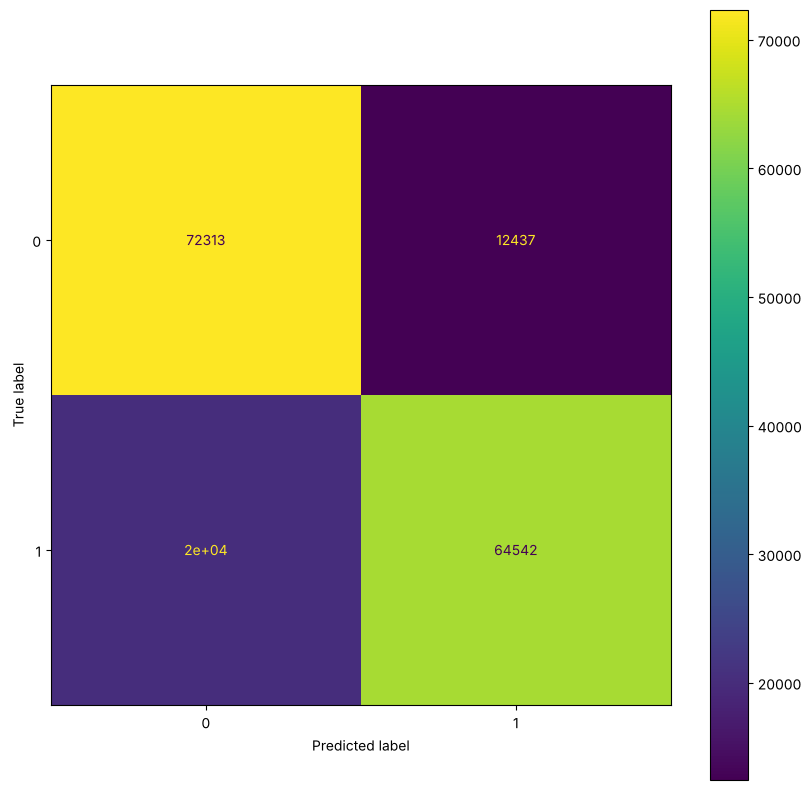

In [257]:
fig, ax = plt.subplots(figsize = (10, 10))
plot_confusion_matrix(model, X_cv, y_cv, ax = ax)
plt.show()

AUC for our classifier is: 0.8074041297935104


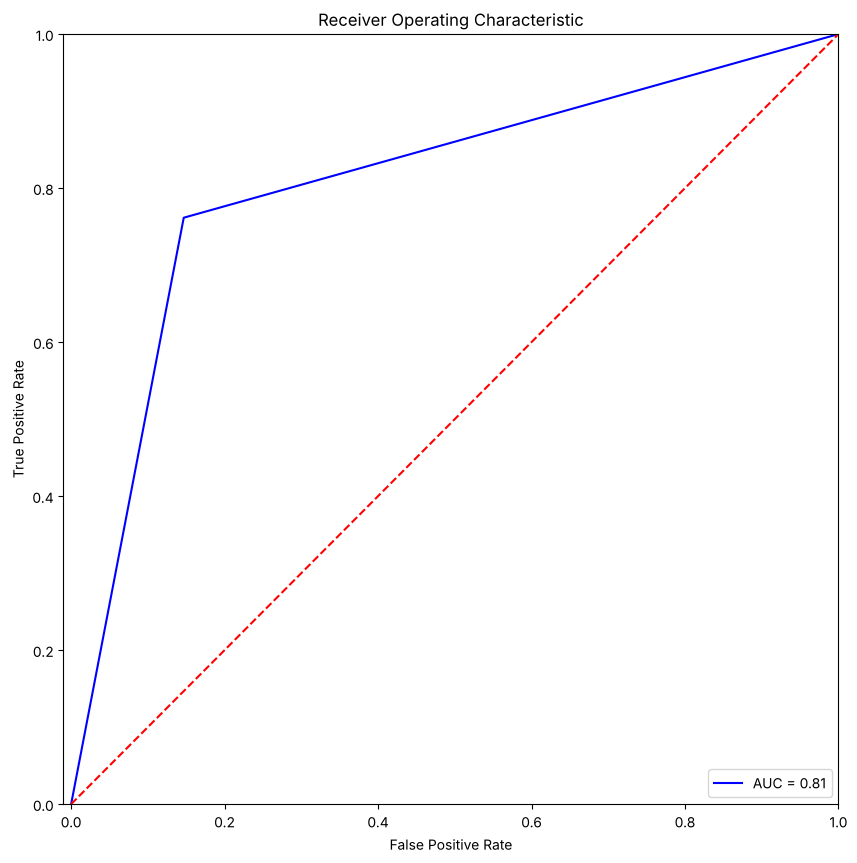

In [258]:
## https://medium.com/analytics-vidhya/evaluation-metrics-for-classification-problems-with-implementation-in-python-a20193b4f2c3
## Credits to this website for providing such an useful and clear explanation of the topic along with the code.

class_probabilities = model.predict_proba(X_cv)
preds = class_probabilities[:, 1]

fpr, tpr, threshold = roc_curve(y_cv, preds)
roc_auc = auc(fpr, tpr)

# Printing AUC
print(f"AUC for our classifier is: {roc_auc}")

# Plotting the ROC
plt.figure(figsize = (10, 10))
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([-0.01, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [259]:
model = RandomForestClassifier(n_jobs = -1)
model.fit(X_train, y_train)
y_predictions = model.predict(X_cv)

In [260]:
print(classification_report(y_predictions, y_cv))

              precision    recall  f1-score   support

           0       0.98      0.79      0.88    105093
           1       0.74      0.98      0.85     64407

    accuracy                           0.86    169500
   macro avg       0.86      0.89      0.86    169500
weighted avg       0.89      0.86      0.87    169500



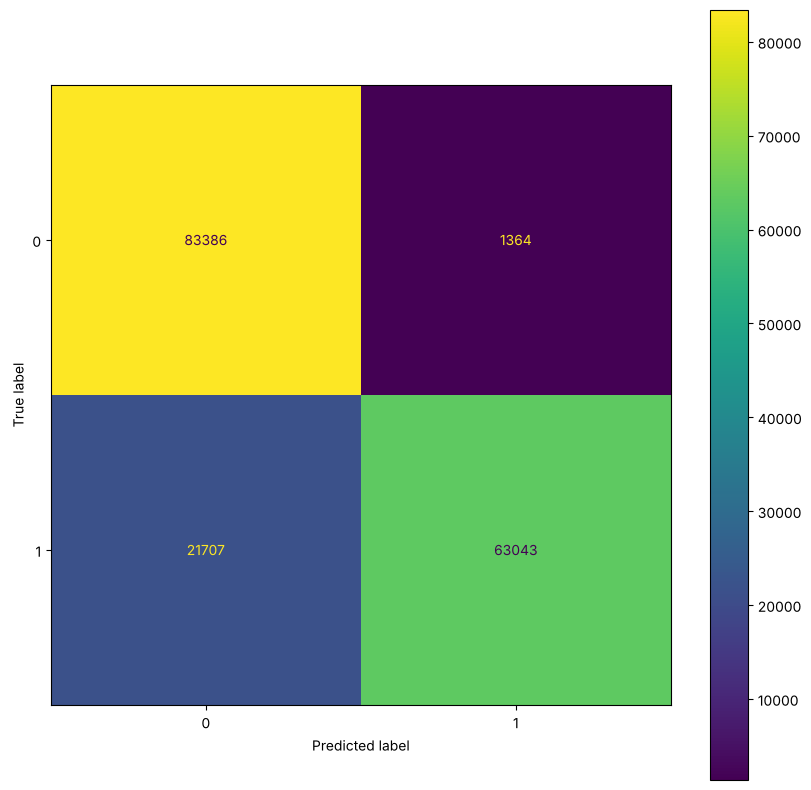

In [261]:
fig, ax = plt.subplots(figsize = (10, 10))
plot_confusion_matrix(model, X_cv, y_cv, ax = ax)
plt.show()

---
# Bonus (not in the original) — an honest re-evaluation

The original Part 3 reports very high scores (Random Forest AUC ≈ 0.95). Two things inflate them:

1. **The validation set is resampled too.** `sampler_function` is applied to `X_cv, y_cv`, so the model is graded on
   synthetic SMOTE points (and on duplicated rows for RandomOverSampler) instead of on real, imbalanced data.
   SMOTE points are interpolated between real neighbours, which makes them much easier to classify.
2. **The "categorical + numerical" model never actually sees the categorical columns.**
   `pd.DataFrame(...).reset_index(drop=True, inplace=True)` returns `None`, and `pd.concat` silently drops `None`,
   so `final_df_train` is just the numeric data again — which is why both runs print identical reports.

Also, `SK_ID_CURR` (a row ID) is used as a feature.

Below the same kind of models are trained the standard way: resample **only the training data**, keep the validation
data untouched, drop the ID, and actually include the one-hot encoded categories. Expect lower but *real* numbers —
for reference, the top Kaggle solutions using many more tables reached an AUC of about 0.80.

In [262]:
# [Added] Leakage-free pipeline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from imblearn.over_sampling import SMOTE

y_all = numeric_data['TARGET'].values
X_num = numeric_data.drop(columns=['TARGET', 'SK_ID_CURR'])
X_cat = categorical_data

Xn_tr, Xn_va, Xc_tr, Xc_va, y_tr, y_va = train_test_split(
    X_num, X_cat, y_all, test_size=0.3, random_state=101, stratify=y_all)

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
scaler_b = StandardScaler()
Xtr = np.hstack([scaler_b.fit_transform(Xn_tr), ohe.fit_transform(Xc_tr)])
Xva = np.hstack([scaler_b.transform(Xn_va), ohe.transform(Xc_va)])
feature_names = list(X_num.columns) + list(ohe.get_feature_names_out(X_cat.columns))

Xtr_sm, ytr_sm = SMOTE(random_state=101).fit_resample(Xtr, y_tr)   # resample TRAIN only
print('train after SMOTE:', Xtr_sm.shape, '| validation (untouched):', Xva.shape,
      f'| default rate in validation: {y_va.mean():.1%}')

train after SMOTE: (395754, 163) | validation (untouched): (92253, 163) | default rate in validation: 8.1%


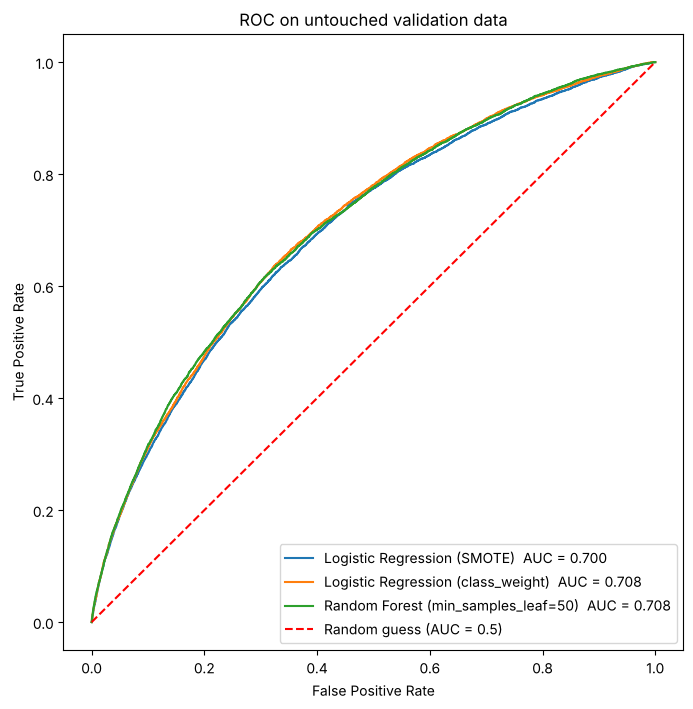

              precision    recall  f1-score   support

  repaid (0)       0.96      0.67      0.78     84805
 default (1)       0.15      0.65      0.24      7448

    accuracy                           0.66     92253
   macro avg       0.55      0.66      0.51     92253
weighted avg       0.89      0.66      0.74     92253



In [263]:
# [Added] Train and score on the real, untouched validation set
honest = {}
lr = LogisticRegression(max_iter=1000).fit(Xtr_sm, ytr_sm)
honest['Logistic Regression (SMOTE)'] = lr.predict_proba(Xva)[:, 1]

lr_w = LogisticRegression(max_iter=1000, class_weight='balanced').fit(Xtr, y_tr)
honest['Logistic Regression (class_weight)'] = lr_w.predict_proba(Xva)[:, 1]

rf_b = RandomForestClassifier(n_estimators=100, min_samples_leaf=50, n_jobs=-1, random_state=101).fit(Xtr, y_tr)
honest['Random Forest (min_samples_leaf=50)'] = rf_b.predict_proba(Xva)[:, 1]

plt.figure(figsize=(8, 8))
for name, p in honest.items():
    fpr, tpr, _ = roc_curve(y_va, p)
    plt.plot(fpr, tpr, label=f'{name}  AUC = {roc_auc_score(y_va, p):.3f}')
plt.plot([0, 1], [0, 1], 'r--', label='Random guess (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC on untouched validation data'); plt.legend(loc='lower right'); plt.show()

print(classification_report(y_va, (honest['Logistic Regression (class_weight)'] > 0.5).astype(int),
                            target_names=['repaid (0)', 'default (1)']))

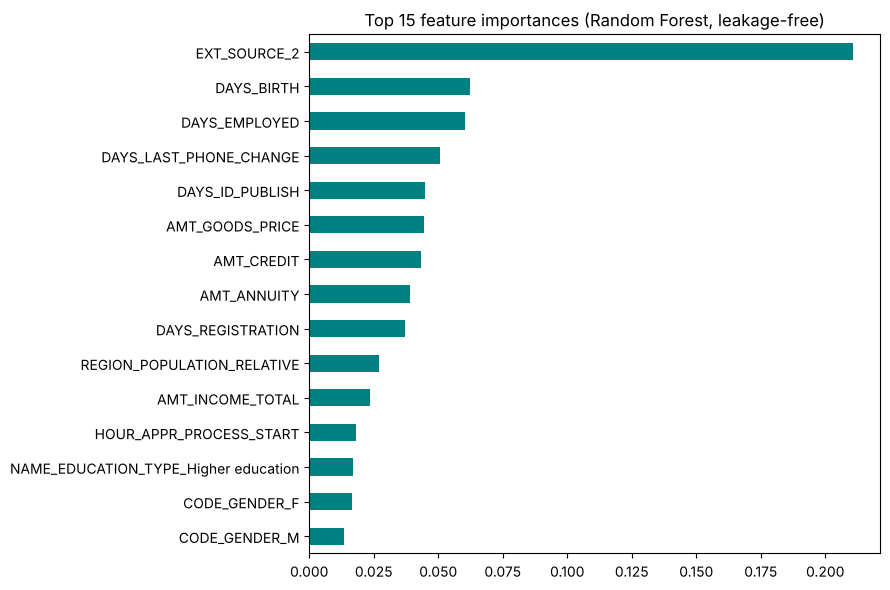

In [264]:
# [Added] Which features does the Random Forest lean on most?
imp = pd.Series(rf_b.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6))
imp[::-1].plot(kind='barh', color='teal')
plt.title('Top 15 feature importances (Random Forest, leakage-free)'); plt.tight_layout(); plt.show()